In [1]:
#!python.exe -m pip install --upgrade pip

In [2]:
#pip install scikit-posthocs

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import re
import glob
import scikit_posthocs as sp
from scipy.stats import friedmanchisquare, rankdata

<h1 style = "color:green;">Time Execution Plots</h1>

In [2]:
def plot_mean_execution_time(files, kp_range=None, primary_algo=None,
                             title=None, xlabel=None, filename=None,
                             numeric_order=False):
    """
    Plots the average execution time of algorithms.

    Parameters
    ----------
    files : dict
        Dictionary of {'Algorithm Name': 'csv_file_path'}
    kp_range : tuple, optional
        (start_kp, end_kp), e.g. (1,30). If None, uses all instances.
    primary_algo : str, optional
        Algorithm to highlight in dark blue.
    title : str, optional
        Custom plot title.
    xlabel : str, optional
        Custom x-axis label.
    filename : str, optional
        Output filename.
    numeric_order : bool, optional
        If True, x-axis labels are sorted numerically
        (e.g., 0.1, 0.2, ..., 0.9).
        If False (default), bars are sorted by mean execution time
        (largest to smallest).
    """

    dataframes = {}

    # Read all csv files
    for alg_name, file_name in files.items():
        dataframes[alg_name] = pd.read_csv(file_name)

    # Get dataset names
    first_df = next(iter(dataframes.values()))
    all_datasets = first_df['Dataset'].values

    # Filter kp instances
    if kp_range is not None:
        start_kp, end_kp = kp_range

        mask = [
            (int(d.split('_')[1]) >= start_kp) and
            (int(d.split('_')[1]) <= end_kp)
            for d in all_datasets
        ]

        title_suffix = f"kp{start_kp} to kp{end_kp}"
        filename_suffix = f"kp{start_kp}_to_kp{end_kp}"

    else:
        mask = [True] * len(all_datasets)

        kp_values = [int(d.split('_')[1]) for d in all_datasets]
        title_suffix = f"all kp instances (kp{min(kp_values)} to kp{max(kp_values)})"
        filename_suffix = "all_kp"

    # Calculate average execution time
    mean_times = []

    for alg_name, df_alg in dataframes.items():
        filtered_times = df_alg['Time sec'].values[mask]

        mean_times.append({
            'Algorithm': alg_name,
            'Mean Time (sec)': np.mean(filtered_times)
        })

    mean_df = pd.DataFrame(mean_times)

    # --------------------------------------------------
    # Determine x-axis order
    # --------------------------------------------------
    if numeric_order:
        # Sort labels numerically (0.1 -> 0.9)
        ordered_algs = sorted(mean_df['Algorithm'], key=float)
    else:
        # Sort by execution time (highest -> lowest)
        mean_df_sorted = mean_df.sort_values(
            by='Mean Time (sec)',
            ascending=False
        )
        ordered_algs = mean_df_sorted['Algorithm'].tolist()

    # --------------------------------------------------
    # Assign colors
    # --------------------------------------------------
    colors = {}

    for alg in ordered_algs:
        if primary_algo is not None and alg == primary_algo:
            colors[alg] = 'darkblue'
        else:
            colors[alg] = 'steelblue'

    # Apply ordering
    mean_df['Algorithm'] = pd.Categorical(
        mean_df['Algorithm'],
        categories=ordered_algs,
        ordered=True
    )

    mean_df = mean_df.sort_values('Algorithm')

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------
    plt.figure(figsize=(12, 7))

    sns.barplot(
        x='Algorithm',
        y='Mean Time (sec)',
        data=mean_df,
        palette=colors
    )

    #plt.yscale('log')

    plt.xlabel(
        xlabel if xlabel is not None else 'Algorithms',
        fontsize=14
    )

    plt.ylabel(
        'Average Execution Time in seconds',
        fontsize=14
    )

    if title is not None:
        plot_title = title
    else:
        plot_title = f'Average Algorithm Execution Time Comparison ({title_suffix})'

    plt.title(plot_title, fontsize=16)

    plt.tight_layout()

    if filename is not None:
        save_filename = filename
    else:
        save_filename = f'{filename_suffix}.png'

    plt.savefig(save_filename, dpi=300, bbox_inches='tight')
    plt.show()

    return mean_df

<h3 style = "color:blue;">Reinitialization Time Execution Experiment</h3>

C:\Users\sedra\AppData\Local\Temp\ipykernel_20484\3119342.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


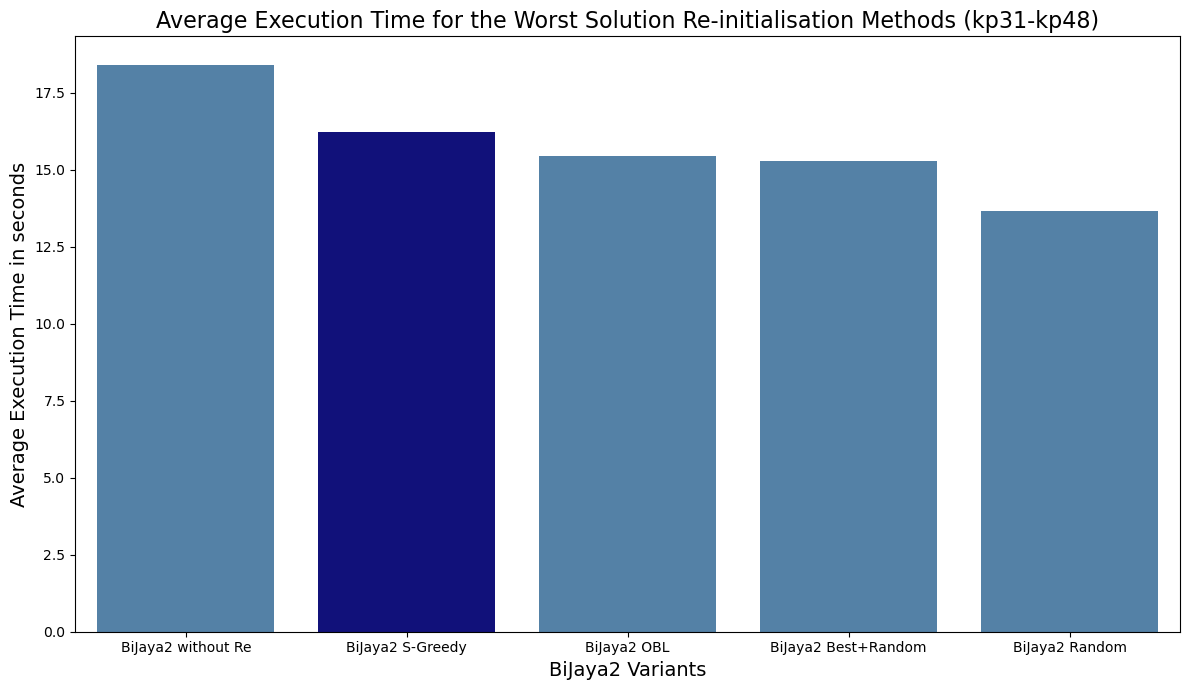

In [3]:
files = {
    'BiJaya2 S-Greedy': 'reinitialization (with SRO2)/BiJaya2_greedy/BiJaya2_Greedy_Re_Knapsack.csv',
    'BiJaya2 OBL': 'reinitialization (with SRO2)/BiJaya2_OBL/BiJaya2_OBL_Re_Knapsack.csv',
    'BiJaya2 Best+Random': 'reinitialization (with SRO2)/BiJaya2_best_AND_random/BiJaya2_best_random_Re_Knapsack.csv',
    'BiJaya2 Random': 'reinitialization (with SRO2)/BiJaya2_random/BiJaya2_Random_Re_Knapsack.csv',
    'BiJaya2 without Re': 'reinitialization (with SRO2)/BiJaya2_without_Re/BiJaya2_without_Re_Knapsack.csv'
}

mean_df = plot_mean_execution_time(
    files, 
    kp_range=(31, 48), 
    primary_algo='BiJaya2 S-Greedy',
    title='Average Execution Time for the Worst Solution Re-initialisation Methods (kp31-kp48)',
    xlabel='BiJaya2 Variants',
    filename='avgTime_reinitialization_kp31_kp48.png'
)

<h3 style = "color:blue;">r1 Time Execution Experiment (kp31-kp48)</h3>

C:\Users\sedra\AppData\Local\Temp\ipykernel_20484\3119342.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


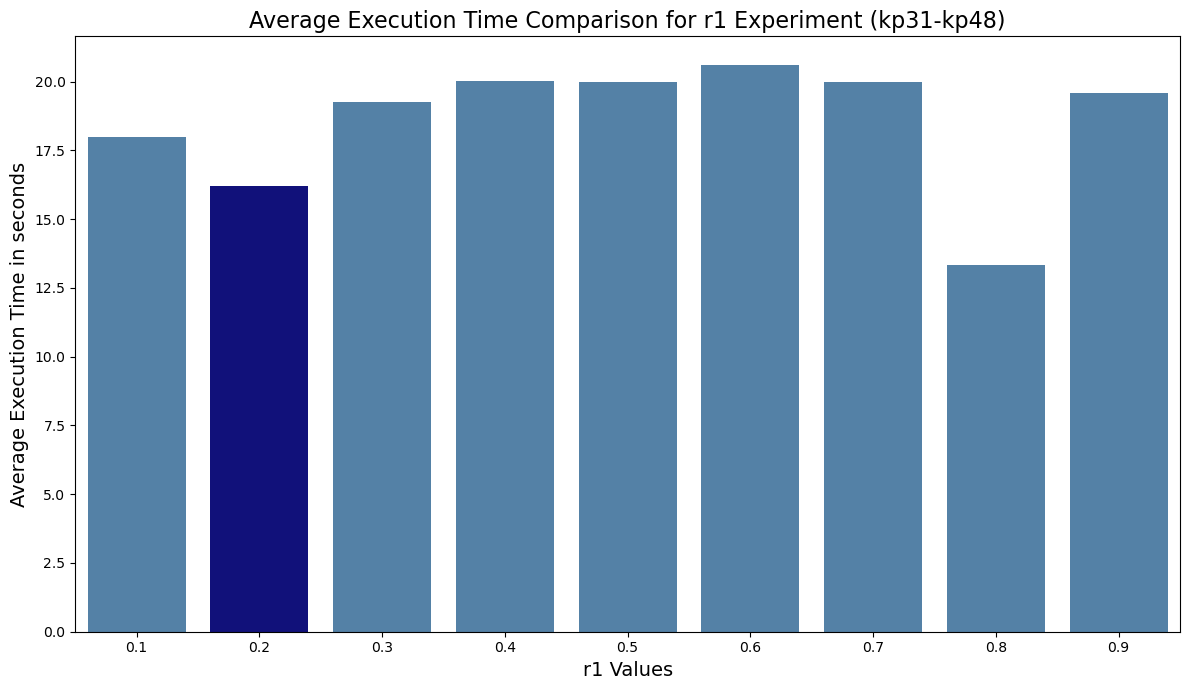

In [4]:
files = {
    '0.1': 'BiJaya2_r1/BiJaya2_r1_0.1/BiJaya2_r1_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r1/BiJaya2_r1_0.2/BiJaya2_r1_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r1/BiJaya2_r1_0.3/BiJaya2_r1_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r1/BiJaya2_r1_0.4/BiJaya2_r1_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r1/BiJaya2_r1_0.5/BiJaya2_r1_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r1/BiJaya2_r1_0.6/BiJaya2_r1_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r1/BiJaya2_r1_0.7/BiJaya2_r1_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r1/BiJaya2_r1_0.8/BiJaya2_r1_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r1/BiJaya2_r1_0.9/BiJaya2_r1_0.9_Knapsack.csv'
}

mean_df = plot_mean_execution_time(
    files, 
    kp_range=(31, 48), 
    primary_algo='0.2',
    numeric_order=True,
    title='Average Execution Time Comparison for r1 Experiment (kp31-kp48)',
    xlabel='r1 Values',
    filename='avgTime_r1_kp31_kp48.png'
)

<h3 style = "color:blue;">r2 Time Execution Experiment (kp31-kp48)</h3>

C:\Users\sedra\AppData\Local\Temp\ipykernel_20484\3119342.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


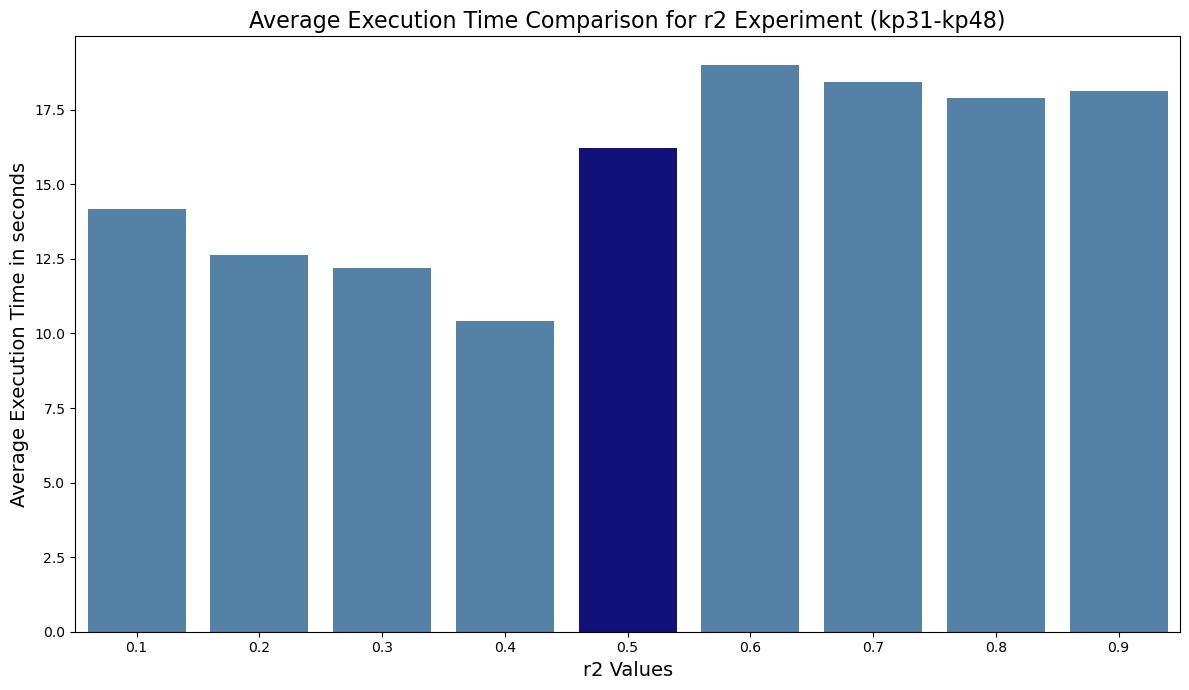

In [5]:
files = {
    '0.1': 'BiJaya2_r2/BiJaya2_r2_0.1/BiJaya2_r2_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r2/BiJaya2_r2_0.2/BiJaya2_r2_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r2/BiJaya2_r2_0.3/BiJaya2_r2_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r2/BiJaya2_r2_0.4/BiJaya2_r2_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r2/BiJaya2_r2_0.5/BiJaya2_r2_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r2/BiJaya2_r2_0.6/BiJaya2_r2_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r2/BiJaya2_r2_0.7/BiJaya2_r2_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r2/BiJaya2_r2_0.8/BiJaya2_r2_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r2/BiJaya2_r2_0.9/BiJaya2_r2_0.9_Knapsack.csv'
}

mean_df = plot_mean_execution_time(
    files, 
    kp_range=(31, 48), 
    primary_algo='0.5',
    numeric_order=True,
    title='Average Execution Time Comparison for r2 Experiment (kp31-kp48)',
    xlabel='r2 Values',
    filename='avgTime_r2_kp31_kp48.png'
)

<h3 style = "color:blue;">Jaya Variants Time Execution Experiment (kp31-kp48)</h3>

C:\Users\sedra\AppData\Local\Temp\ipykernel_20484\3119342.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


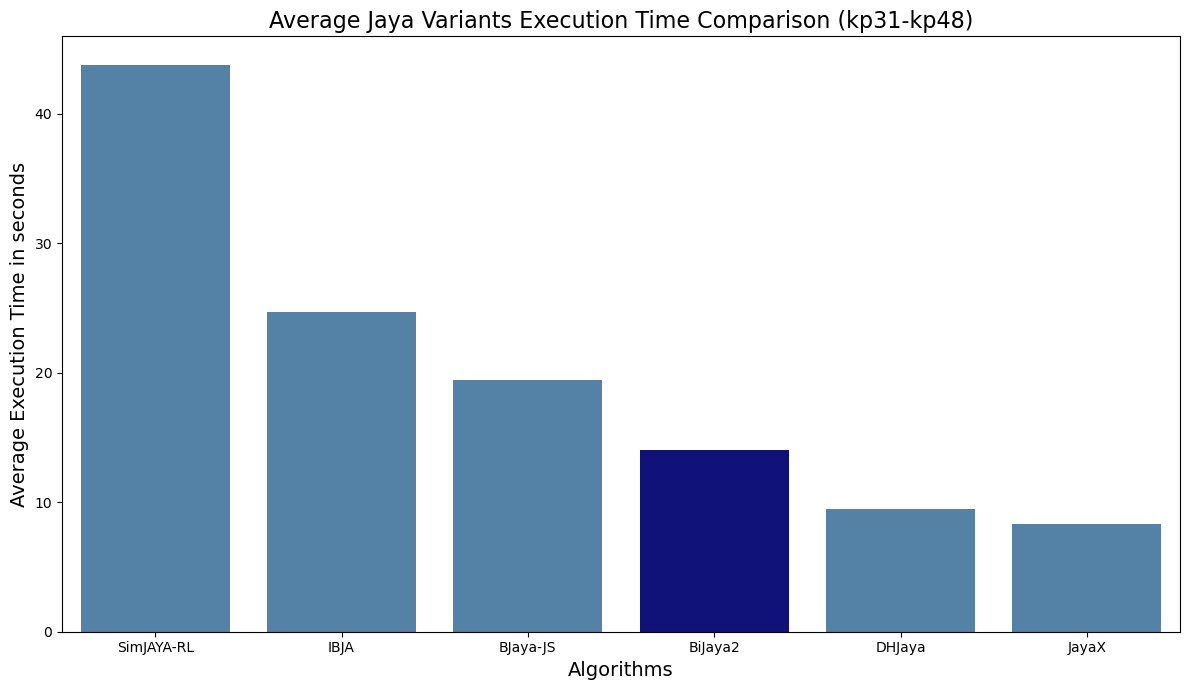

In [6]:
files = {
    'BiJaya2': 'Jaya variants/Jaya2_SRO/BiJaya2_Knapsack.csv',
    'BJaya-JS': 'Jaya variants/Jaya-JS RO/BJayaJS_Knapsack.csv',
    'DHJaya': 'Jaya variants/DHJaya RO/DHJaya_Knapsack.csv',
    'IBJA': 'Jaya variants/IBJaya/IBJaya_Knapsack.csv',
    'JayaX': 'Jaya variants/JayaX RO/JayaX_Knapsack.csv',
    'SimJAYA-RL': 'Jaya variants/SimBJAYA-RL RO/SimJAYA_RL_Knapsack.csv'
}

mean_df = plot_mean_execution_time(
    files, 
    kp_range=(31, 48), 
    primary_algo='BiJaya2',
    numeric_order=False,
    title='Average Jaya Variants Execution Time Comparison (kp31-kp48)',
    xlabel='Algorithms',
    filename='avgTime_Jaya_Varaints_large_kp31_kp48.png'
)

<h3 style = "color:blue;">6 Algorithm Time Execution Experiment (kp1-kp30)</h3>

C:\Users\sedra\AppData\Local\Temp\ipykernel_20484\3119342.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


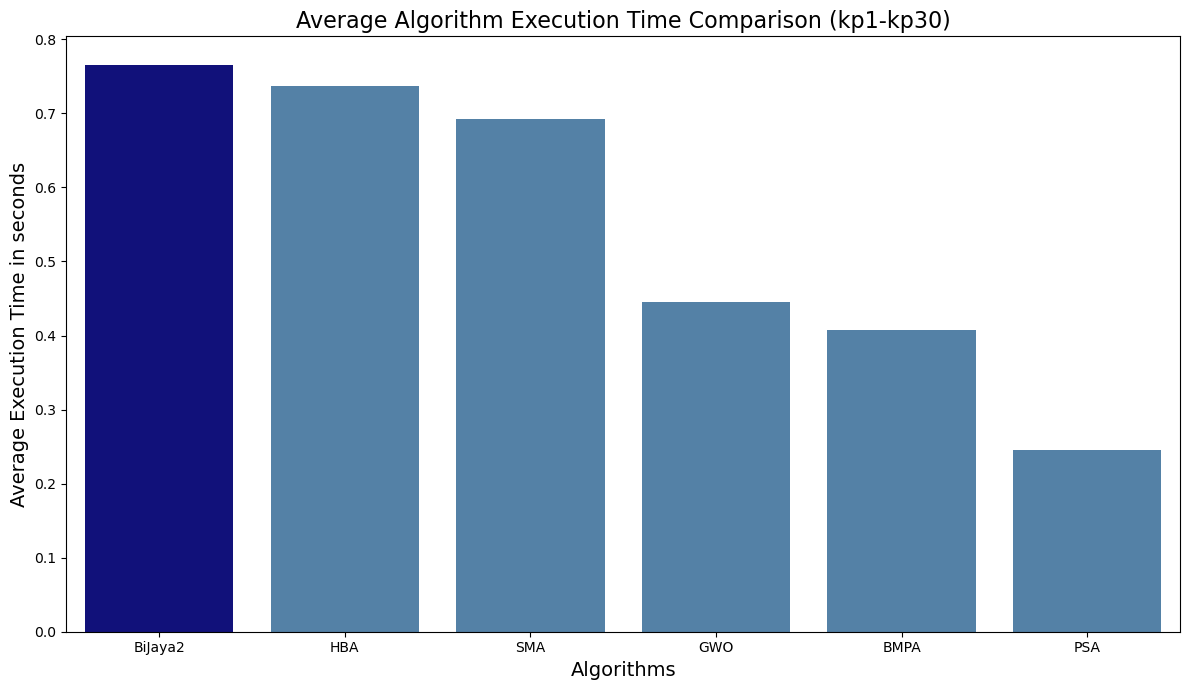

In [7]:
files = {
    'BiJaya2': '6 Algorithms (small instances)/BiJaya (without SRO2)/BiJaya2_withoutSRO2_small_Knapsack.csv',
    'SMA': '6 Algorithms (small instances)/SMA/SMA_Knapsack.csv',
    'PSA': '6 Algorithms (small instances)/PSA/PSA_Knapsack.csv',
    #'SCA': '6 Algorithms (small instances)/SCA (without RO)/SCA_Knapsack.csv',
    'HBA': '6 Algorithms (small instances)/HBA (without RO)/HBA_Knapsack.csv',
    'GWO': '6 Algorithms (small instances)/GWO/GWO_Knapsack.csv',
    'BMPA': '6 Algorithms (small instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

mean_df = plot_mean_execution_time(
    files, 
    kp_range=(1, 30), 
    primary_algo='BiJaya2',
    numeric_order=False,
    title='Average Algorithm Execution Time Comparison (kp1-kp30)',
    xlabel='Algorithms',
    filename='avgTime_6algo_small_kp1_kp30.png'
)

<h3 style = "color:blue;">5 Algorithm Time Execution Experiment (kp31-kp48)</h3>

C:\Users\sedra\AppData\Local\Temp\ipykernel_20484\3119342.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


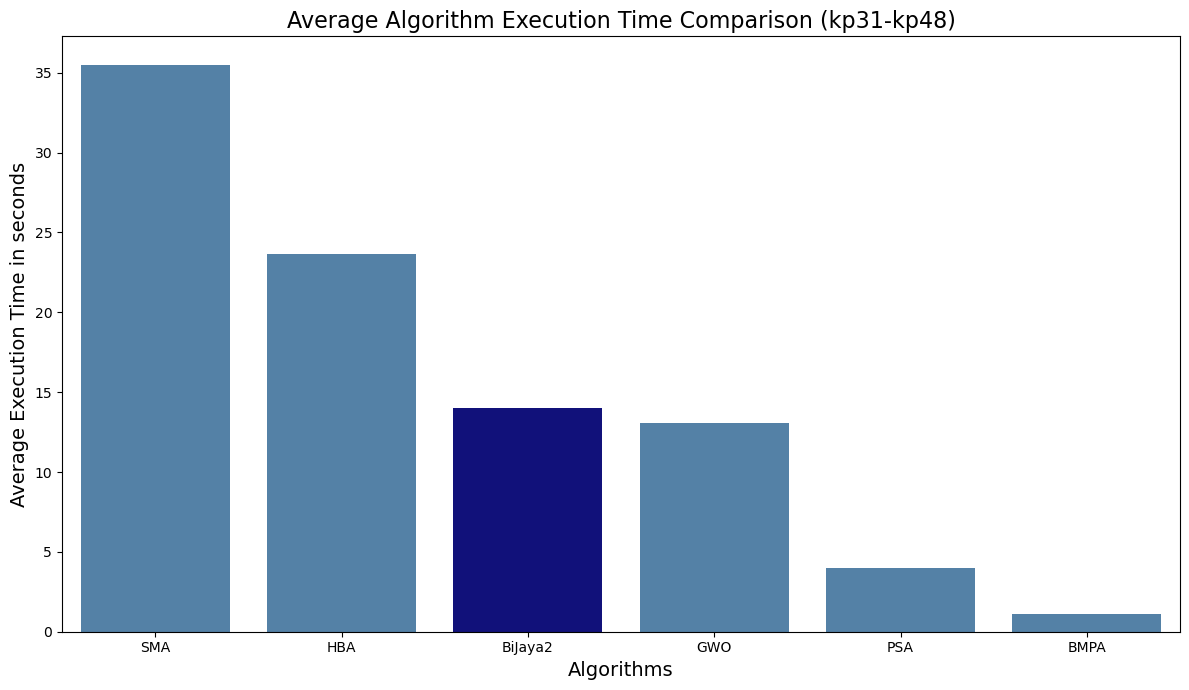

In [8]:
files = {
    'BiJaya2': '5 Algorithms (Large instances)/BiJaya2/BiJaya2_Knapsack.csv',
    'SMA': '5 Algorithms (Large instances)/SMA/SMA_Knapsack.csv',
    'PSA': '5 Algorithms (Large instances)/PSA/PSA_Knapsack.csv',
    'HBA': '5 Algorithms (Large instances)/HBA/HBA_Knapsack.csv',
    'GWO': '5 Algorithms (Large instances)/GWO/GWO_Knapsack.csv',
    'BMPA': '5 Algorithms (Large instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

mean_df = plot_mean_execution_time(
    files, 
    kp_range=(31, 48), 
    primary_algo='BiJaya2',
    numeric_order=False,
    title='Average Algorithm Execution Time Comparison (kp31-kp48)',
    xlabel='Algorithms',
    filename='avgTime_5algo_large_kp31_kp48.png'
)

<h1 style = "color:green;">Convergence Plots</h1>

<h3 style = "color:blue;">All Algorithms For BiJaya2 without RO (small instances kp1-kp30)</h3>

In [9]:
def plot_algorithm_convergence(
    files,  # Dictionary mapping algorithm names to summary file paths
    primary_algo='BiJaya2',
    instances=None,
    plots_per_figure=3,
    output_prefix=None,
    convergence_files=None):  # NEW: optional explicit dict {algo_name: convergence_csv_path}

    # Load summary data from files dictionary
    summary_data = {}
    for algo_name, file_path in files.items():
        if os.path.exists(file_path):
            summary_data[algo_name] = pd.read_csv(file_path)
        else:
            print(f"Warning: File {file_path} not found for algorithm {algo_name}")

    if primary_algo not in summary_data:
        raise ValueError(f"Primary algorithm '{primary_algo}' summary file is missing.")

    # Get all datasets from primary algorithm
    all_datasets = summary_data[primary_algo]['Dataset'].astype(str)

    if instances is None:
        datasets = all_datasets.unique().tolist()
    else:
        requested = []
        for item in instances:
            if isinstance(item, int):
                requested.append(f'kp{item}')
            else:
                requested.append(str(item).lower())

        datasets = []
        for ds in all_datasets:
            ds_lower = ds.lower()
            for req in requested:
                if req in ds_lower:
                    datasets.append(ds)
                    break
        datasets = list(dict.fromkeys(datasets))

    if not datasets:
        raise ValueError(f'No matching datasets found for {instances}')

    n_datasets = len(datasets)

    # ------------------------------------------------------------------
    # Load convergence data.
    #
    # FIX: previously this guessed the filename as f'{algo_name}_Convergence.csv',
    # built directly from the dictionary key. That guess silently fails whenever
    # the actual file on disk uses different casing, underscores vs spaces,
    # a '+' vs 'AND', or an extra '_Re_' segment (exactly what happened here).
    #
    # Now we support two ways to find the convergence file, in priority order:
    #   1. An explicit path given in `convergence_files[algo_name]`.
    #   2. Auto-discovery: look in the same folder as the summary file for
    #      any *_Convergence.csv file (there should only be one per folder).
    # ------------------------------------------------------------------
    convergence_data = {}
    for algo_name, file_path in files.items():
        base_dir = os.path.dirname(file_path)
        conv_file = None

        # 1) Explicit override takes priority
        if convergence_files and algo_name in convergence_files:
            candidate = convergence_files[algo_name]
            if os.path.exists(candidate):
                conv_file = candidate
            else:
                print(f"Warning: explicit convergence file {candidate} not found for {algo_name}")

        # 2) Auto-discover by pattern instead of guessing the exact name
        if conv_file is None:
            matches = glob.glob(os.path.join(base_dir, '*Convergence*.csv'))
            if len(matches) == 1:
                conv_file = matches[0]
            elif len(matches) > 1:
                print(f"Warning: multiple convergence files found for {algo_name} in {base_dir}: "
                      f"{matches}. Using the first one — pass `convergence_files` to disambiguate.")
                conv_file = matches[0]
            else:
                print(f"Warning: no convergence file found for {algo_name} in {base_dir}")

        if conv_file is not None:
            convergence_data[algo_name] = pd.read_csv(conv_file)

    # Determine optimal values for each dataset
    optimal_values = {}
    for dataset in datasets:
        if 'Optimal' in summary_data[primary_algo].columns:
            optimal_values[dataset] = summary_data[primary_algo][summary_data[primary_algo]['Dataset'] == dataset]['Optimal'].values[0]

    # Calculate worst algorithm for each dataset
    worst_algo_for_instance = {}
    for dataset in datasets:
        final_curve_fitness = {}
        for algo in summary_data.keys():
            if algo not in convergence_data:
                continue
            df_conv = convergence_data[algo]
            conv_subset = df_conv[df_conv['Dataset'] == dataset]
            if (not conv_subset.empty and 'AverageFitness' in conv_subset.columns):
                final_val = conv_subset.sort_values(by='nfe')['AverageFitness'].values[-1]
                final_curve_fitness[algo] = final_val

        if final_curve_fitness:
            worst_algo_for_instance[dataset] = min(final_curve_fitness, key=final_curve_fitness.get)

    # Create figures with plots_per_figure plots each
    n_figures = (n_datasets + plots_per_figure - 1) // plots_per_figure

    # Use provided prefix or default to primary_algo.lower()
    if output_prefix is None:
        output_prefix = primary_algo.lower()

    for fig_idx in range(n_figures):
        start_idx = fig_idx * plots_per_figure
        end_idx = min(start_idx + plots_per_figure, n_datasets)
        current_datasets = datasets[start_idx:end_idx]
        n_current_plots = len(current_datasets)

        # Create figure
        fig, axes = plt.subplots(1, n_current_plots, figsize=(7 * n_current_plots, 6))

        # If only one plot, make axes a list for consistency
        if n_current_plots == 1:
            axes = [axes]

        for plot_idx, dataset in enumerate(current_datasets):
            ax = axes[plot_idx]
            optimal_drawn = False

            # Plot curves
            for algo in summary_data.keys():
                if algo not in convergence_data:
                    continue
                df_conv = convergence_data[algo]
                conv_subset = df_conv[df_conv['Dataset'] == dataset]

                if (not conv_subset.empty and 'nfe' in conv_subset.columns and 'AverageFitness' in conv_subset.columns):
                    conv_subset = conv_subset.sort_values(by='nfe')

                    if algo == primary_algo:
                        color = 'darkblue'
                        linewidth = 2.5
                        zorder = 4
                        plot_label = algo
                    elif algo == worst_algo_for_instance.get(dataset):
                        color = 'red'
                        linewidth = 2
                        zorder = 3
                        plot_label = f'{algo} (Worst)'
                    else:
                        color = 'lightgray'
                        linewidth = 1.5
                        zorder = 2
                        plot_label = 'Others'

                    ax.plot(conv_subset['nfe'], conv_subset['AverageFitness'],
                           linewidth=linewidth, color=color, label=plot_label, zorder=zorder)

            # Optimal line
            if not optimal_drawn and dataset in optimal_values:
                optimal = optimal_values[dataset]
                ax.axhline(y=optimal, color='green', linestyle='--', linewidth=2,
                          label=f'Optimal: {optimal}', zorder=1)
                optimal_drawn = True

            # Get dataset label
            try:
                kp_label = f"kp{dataset.split('_')[1]}"
            except IndexError:
                kp_label = dataset

            ax.set_title(kp_label, fontsize=12, fontweight='bold')
            ax.set_xlabel('NFE', fontsize=10)
            ax.set_ylabel('Fitness', fontsize=10)
            ax.set_yscale('log')

            # Legend handling
            handles, labels = ax.get_legend_handles_labels()
            by_label = dict(zip(labels, handles))
            desired_order = ['Optimal:', primary_algo, '(Worst)', 'Others']

            def get_sort_key(label):
                for rank, keyword in enumerate(desired_order):
                    if keyword in label:
                        return rank
                return len(desired_order)

            sorted_labels = sorted(by_label.keys(), key=get_sort_key)
            sorted_handles = [by_label[label] for label in sorted_labels]
            ax.legend(sorted_handles, sorted_labels, loc='best', fontsize=8)

        # Save figure with custom or default prefix
        output_filename = f'{output_prefix}_convergence_part_{fig_idx+1}.png'
        plt.savefig(output_filename, dpi=300, bbox_inches='tight')
        plt.show()
    return convergence_data

In [10]:
def plot_algorithm_convergence_new(
    files,  # Dictionary mapping algorithm names to summary file paths
    primary_algo='BiJaya2',
    instances=None,
    plots_per_figure=3,
    output_prefix=None,
    convergence_files=None):  # NEW: optional explicit dict {algo_name: convergence_csv_path}

    # Load summary data from files dictionary
    summary_data = {}
    for algo_name, file_path in files.items():
        if os.path.exists(file_path):
            summary_data[algo_name] = pd.read_csv(file_path)
        else:
            print(f"Warning: File {file_path} not found for algorithm {algo_name}")

    if primary_algo not in summary_data:
        raise ValueError(f"Primary algorithm '{primary_algo}' summary file is missing.")

    # Get all datasets from primary algorithm
    all_datasets = summary_data[primary_algo]['Dataset'].astype(str)

    if instances is None:
        datasets = all_datasets.unique().tolist()
    else:
        requested = []
        for item in instances:
            if isinstance(item, int):
                requested.append(f'kp{item}')
            else:
                requested.append(str(item).lower())

        datasets = []
        for ds in all_datasets:
            ds_lower = ds.lower()
            for req in requested:
                if req in ds_lower:
                    datasets.append(ds)
                    break
        datasets = list(dict.fromkeys(datasets))

    if not datasets:
        raise ValueError(f'No matching datasets found for {instances}')

    n_datasets = len(datasets)

    # ------------------------------------------------------------------
    # Load convergence data.
    #
    # FIX: previously this guessed the filename as f'{algo_name}_Convergence.csv',
    # built directly from the dictionary key. That guess silently fails whenever
    # the actual file on disk uses different casing, underscores vs spaces,
    # a '+' vs 'AND', or an extra '_Re_' segment (exactly what happened here).
    #
    # Now we support two ways to find the convergence file, in priority order:
    #   1. An explicit path given in `convergence_files[algo_name]`.
    #   2. Auto-discovery: look in the same folder as the summary file for
    #      any *_Convergence.csv file (there should only be one per folder).
    # ------------------------------------------------------------------
    convergence_data = {}
    for algo_name, file_path in files.items():
        base_dir = os.path.dirname(file_path)
        conv_file = None

        # 1) Explicit override takes priority
        if convergence_files and algo_name in convergence_files:
            candidate = convergence_files[algo_name]
            if os.path.exists(candidate):
                conv_file = candidate
            else:
                print(f"Warning: explicit convergence file {candidate} not found for {algo_name}")

        # 2) Auto-discover by pattern instead of guessing the exact name
        if conv_file is None:
            matches = glob.glob(os.path.join(base_dir, '*Convergence*.csv'))
            if len(matches) == 1:
                conv_file = matches[0]
            elif len(matches) > 1:
                print(f"Warning: multiple convergence files found for {algo_name} in {base_dir}: "
                      f"{matches}. Using the first one — pass `convergence_files` to disambiguate.")
                conv_file = matches[0]
            else:
                print(f"Warning: no convergence file found for {algo_name} in {base_dir}")

        if conv_file is not None:
            convergence_data[algo_name] = pd.read_csv(conv_file)

    # Determine optimal values for each dataset
    optimal_values = {}
    for dataset in datasets:
        if 'Optimal' in summary_data[primary_algo].columns:
            optimal_values[dataset] = summary_data[primary_algo][summary_data[primary_algo]['Dataset'] == dataset]['Optimal'].values[0]

    # Calculate best and worst algorithm for each dataset
    best_algo_for_instance = {}
    worst_algo_for_instance = {}
    for dataset in datasets:
        final_curve_fitness = {}
        for algo in summary_data.keys():
            if algo not in convergence_data:
                continue
            df_conv = convergence_data[algo]
            conv_subset = df_conv[df_conv['Dataset'] == dataset]
            if (not conv_subset.empty and 'AverageFitness' in conv_subset.columns):
                final_val = conv_subset.sort_values(by='nfe')['AverageFitness'].values[-1]
                final_curve_fitness[algo] = final_val

        if final_curve_fitness:
            best_algo_for_instance[dataset] = max(final_curve_fitness, key=final_curve_fitness.get)
            worst_algo_for_instance[dataset] = min(final_curve_fitness, key=final_curve_fitness.get)

    # Create figures with plots_per_figure plots each
    n_figures = (n_datasets + plots_per_figure - 1) // plots_per_figure

    # Use provided prefix or default to primary_algo.lower()
    if output_prefix is None:
        output_prefix = primary_algo.lower()

    for fig_idx in range(n_figures):
        start_idx = fig_idx * plots_per_figure
        end_idx = min(start_idx + plots_per_figure, n_datasets)
        current_datasets = datasets[start_idx:end_idx]
        n_current_plots = len(current_datasets)

        # Create figure
        fig, axes = plt.subplots(1, n_current_plots, figsize=(7 * n_current_plots, 6))

        # If only one plot, make axes a list for consistency
        if n_current_plots == 1:
            axes = [axes]

        for plot_idx, dataset in enumerate(current_datasets):
            ax = axes[plot_idx]
            optimal_drawn = False

            # Plot curves
            for algo in summary_data.keys():
                if algo not in convergence_data:
                    continue
                df_conv = convergence_data[algo]
                conv_subset = df_conv[df_conv['Dataset'] == dataset]

                if (not conv_subset.empty and 'nfe' in conv_subset.columns and 'AverageFitness' in conv_subset.columns):
                    conv_subset = conv_subset.sort_values(by='nfe')

                    if algo == primary_algo:
                        color = 'darkblue'
                        linewidth = 2.5
                        zorder = 4
                        plot_label = algo
                    elif algo == best_algo_for_instance.get(dataset):
                        color = 'green'
                        linewidth = 2
                        zorder = 3
                        plot_label = f'{algo} (Best)'
                    elif algo == worst_algo_for_instance.get(dataset):
                        color = 'red'
                        linewidth = 2
                        zorder = 3
                        plot_label = f'{algo} (Worst)'
                    else:
                        color = 'lightgray'
                        linewidth = 1.5
                        zorder = 2
                        plot_label = 'Others'

                    ax.plot(conv_subset['nfe'], conv_subset['AverageFitness'],
                           linewidth=linewidth, color=color, label=plot_label, zorder=zorder)

            # Optimal line
            if not optimal_drawn and dataset in optimal_values:
                optimal = optimal_values[dataset]
                ax.axhline(y=optimal, color='black', linestyle='--', linewidth=2,
                          label=f'Optimal: {optimal}', zorder=1)
                optimal_drawn = True

            # Get dataset label
            try:
                kp_label = f"kp{dataset.split('_')[1]}"
            except IndexError:
                kp_label = dataset

            ax.set_title(kp_label, fontsize=12, fontweight='bold')
            ax.set_xlabel('NFE', fontsize=10)
            ax.set_ylabel('Fitness', fontsize=10)
            ax.set_yscale('log')

            # Legend handling
            handles, labels = ax.get_legend_handles_labels()
            by_label = dict(zip(labels, handles))
            desired_order = ['Optimal:', primary_algo, '(Best)', '(Worst)', 'Others']

            def get_sort_key(label):
                for rank, keyword in enumerate(desired_order):
                    if keyword in label:
                        return rank
                return len(desired_order)

            sorted_labels = sorted(by_label.keys(), key=get_sort_key)
            sorted_handles = [by_label[label] for label in sorted_labels]
            ax.legend(sorted_handles, sorted_labels, loc='best', fontsize=8)

        # Save figure with custom or default prefix
        output_filename = f'{output_prefix}_convergence_part_{fig_idx+1}.png'
        plt.savefig(output_filename, dpi=300, bbox_inches='tight')
        plt.show()
    return convergence_data

<h3 style = "color:blue;">Reinitialization Convergence Plots Experiment</h3>

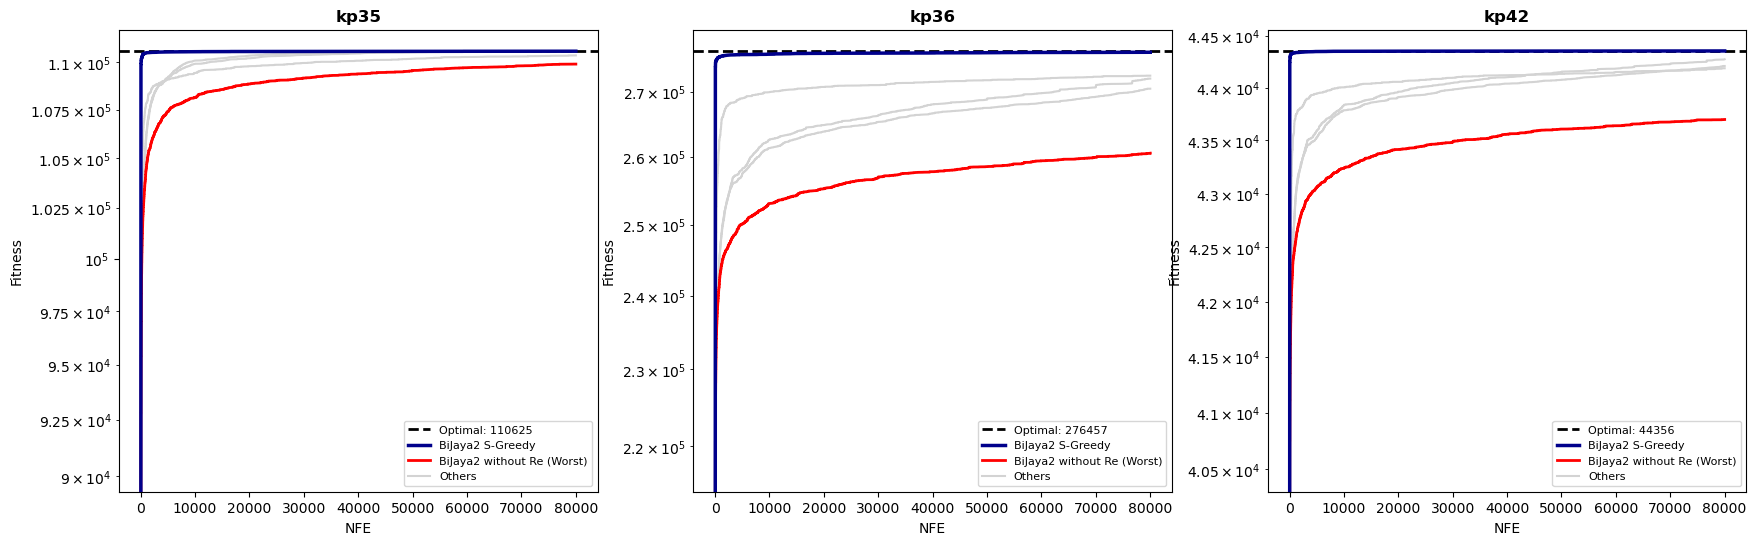

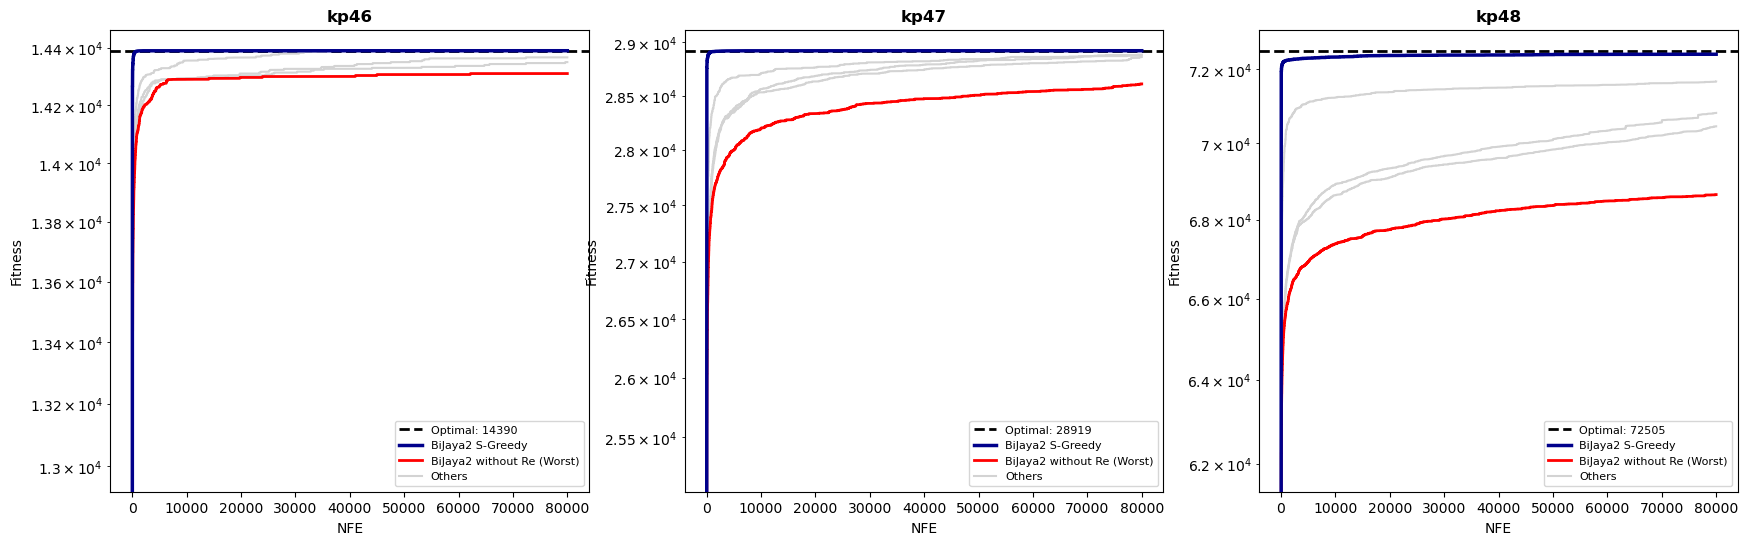

In [11]:
files = {
    'BiJaya2 S-Greedy': 'reinitialization (with SRO2)/BiJaya2_greedy/BiJaya2_Greedy_Re_Knapsack.csv',
    'BiJaya2 OBL': 'reinitialization (with SRO2)/BiJaya2_OBL/BiJaya2_OBL_Re_Knapsack.csv',
    'BiJaya2 Best+Random': 'reinitialization (with SRO2)/BiJaya2_best_AND_random/BiJaya2_best_random_Re_Knapsack.csv',
    'BiJaya2 Random': 'reinitialization (with SRO2)/BiJaya2_random/BiJaya2_Random_Re_Knapsack.csv',
    'BiJaya2 without Re': 'reinitialization (with SRO2)/BiJaya2_without_Re/BiJaya2_without_Re_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2 S-Greedy', 
    instances=['kp_35', 'kp_36', 'kp_42', 'kp_46', 'kp_47', 'kp_48'], 
    plots_per_figure=3, 
    output_prefix='reinitialization_kp31_kp48_convergence' )

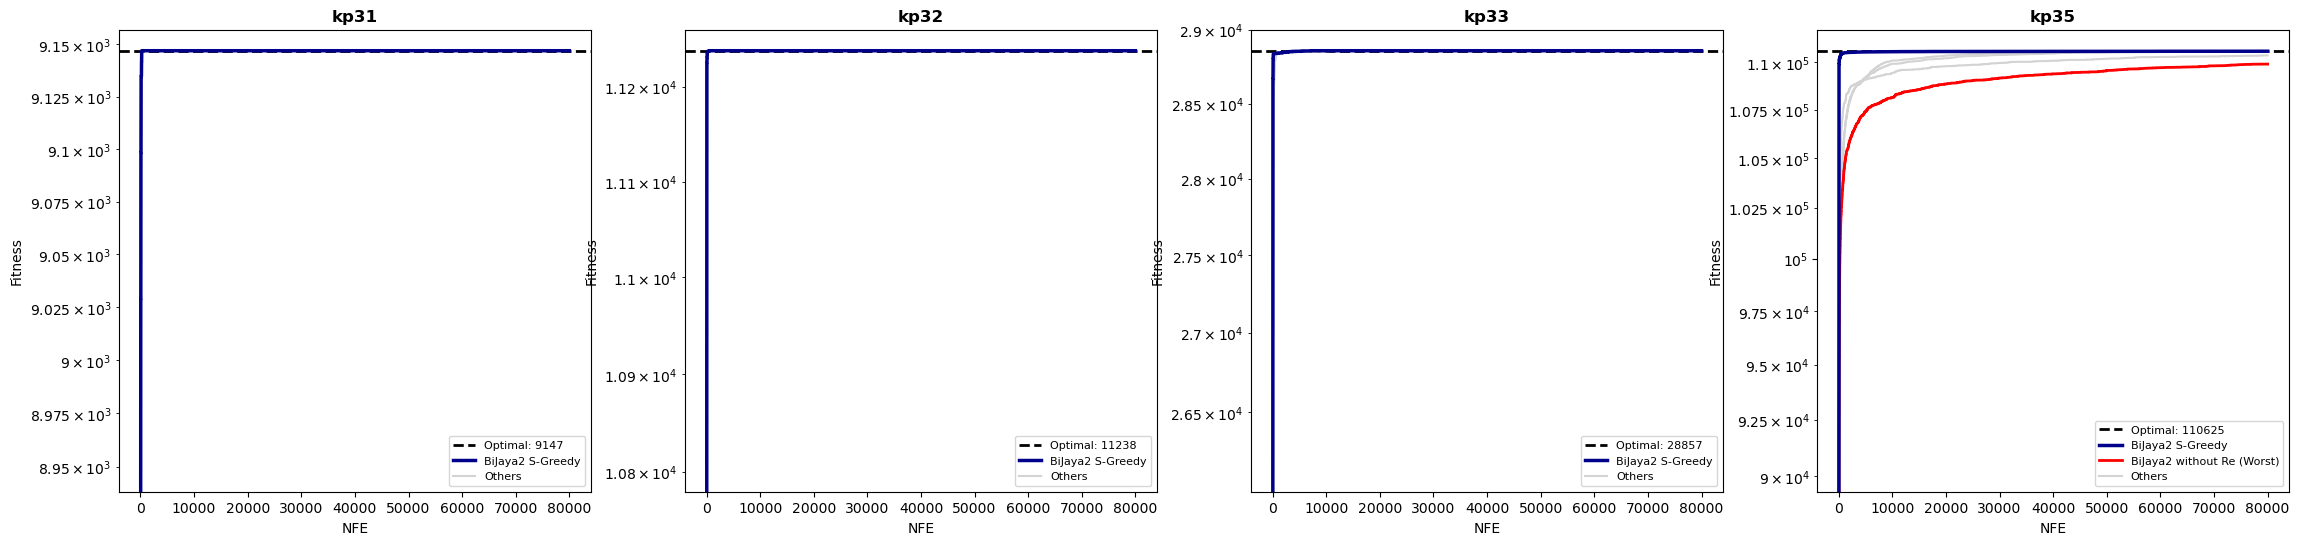

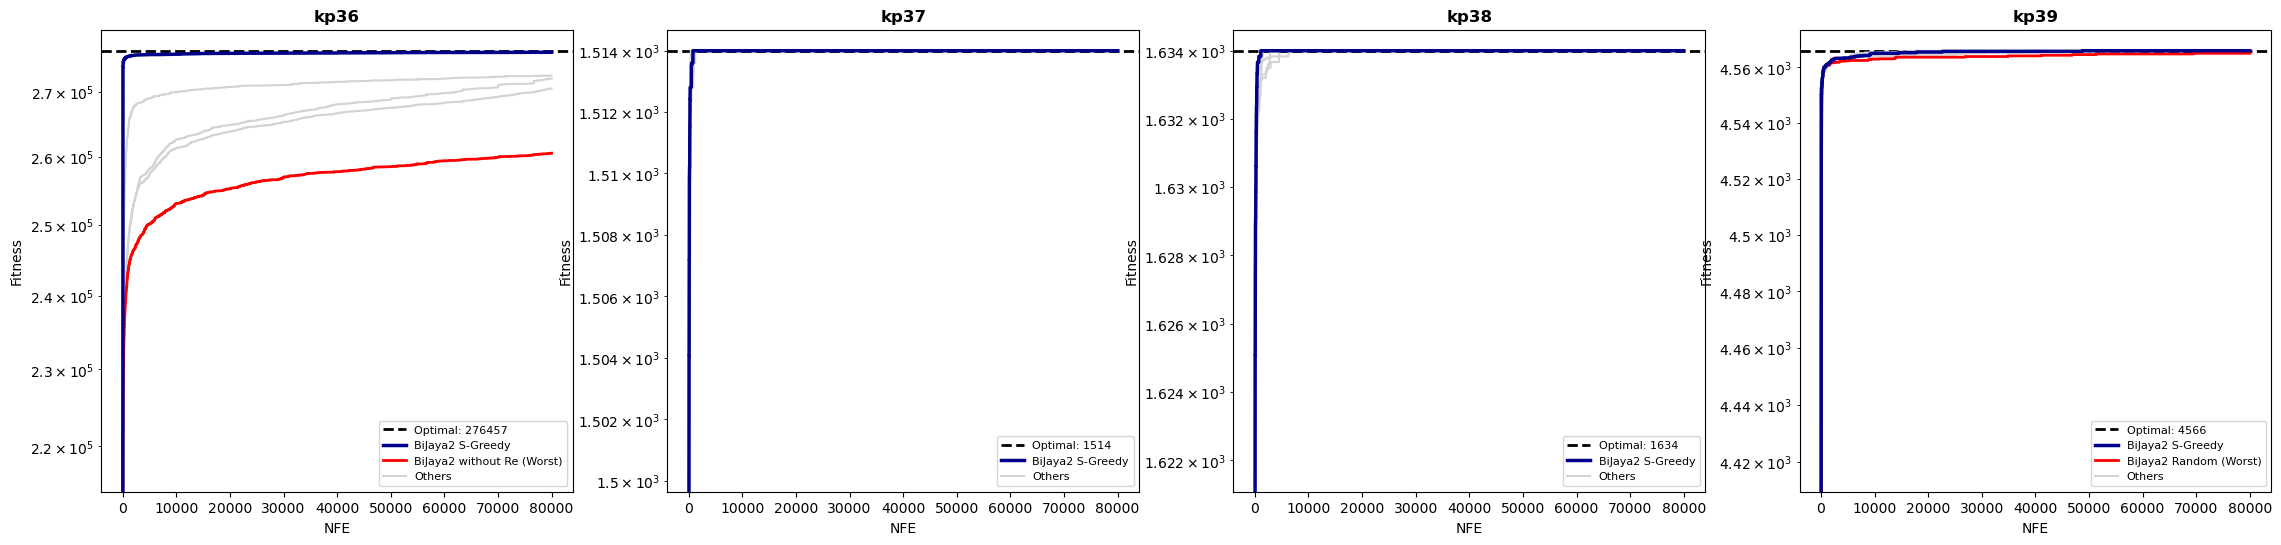

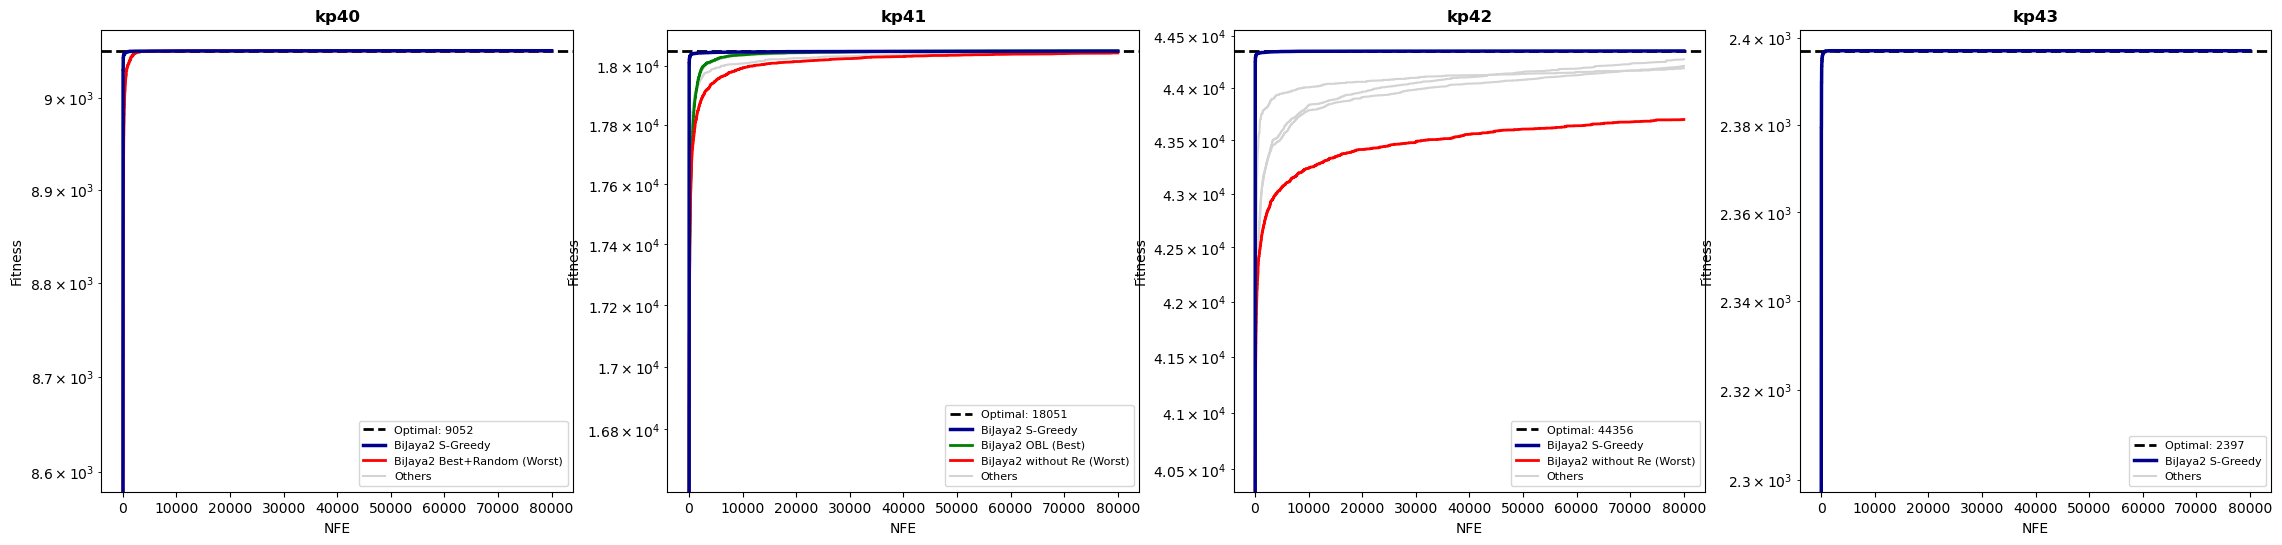

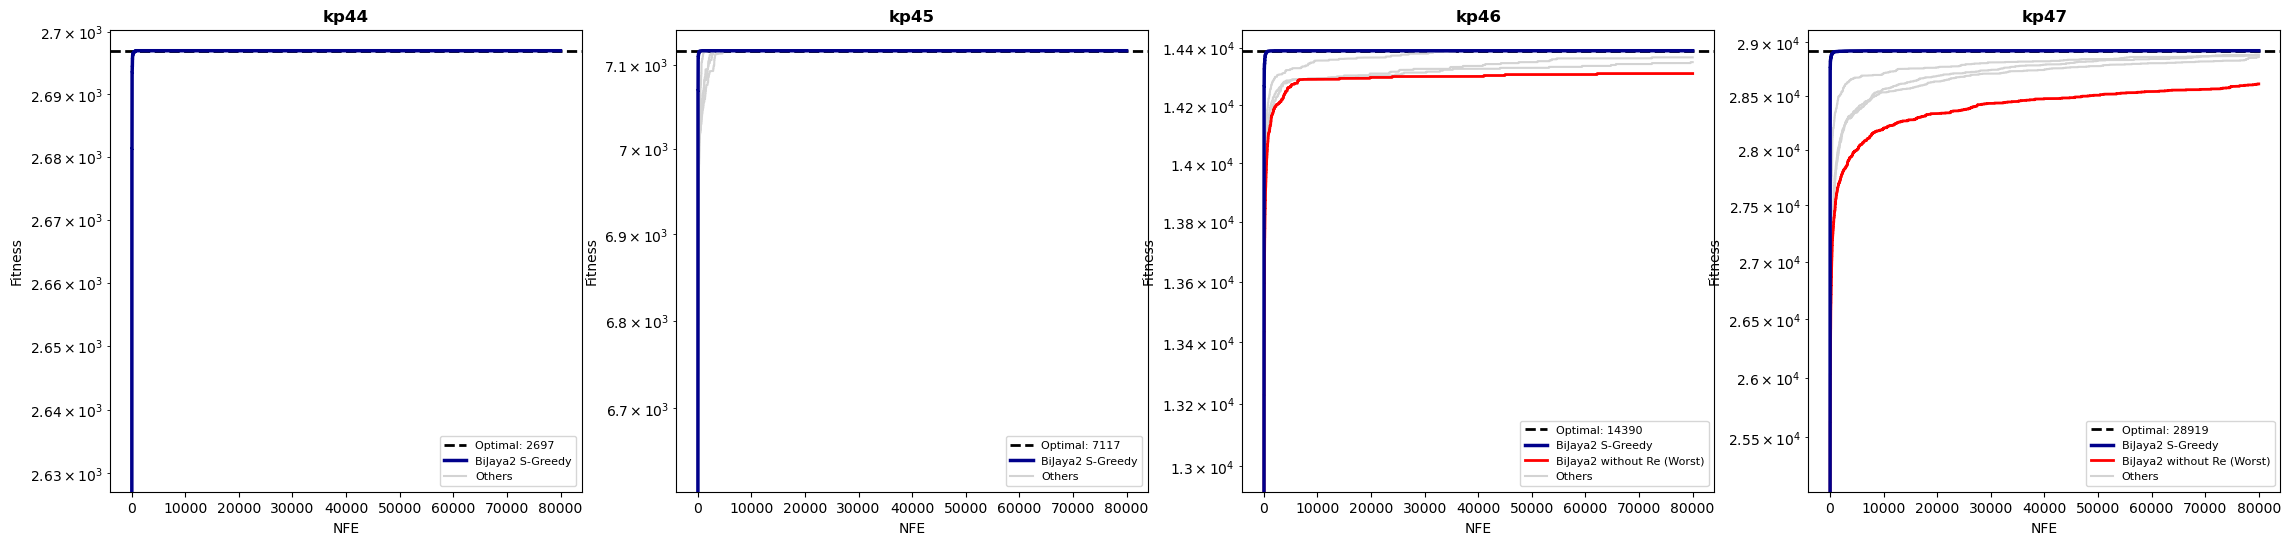

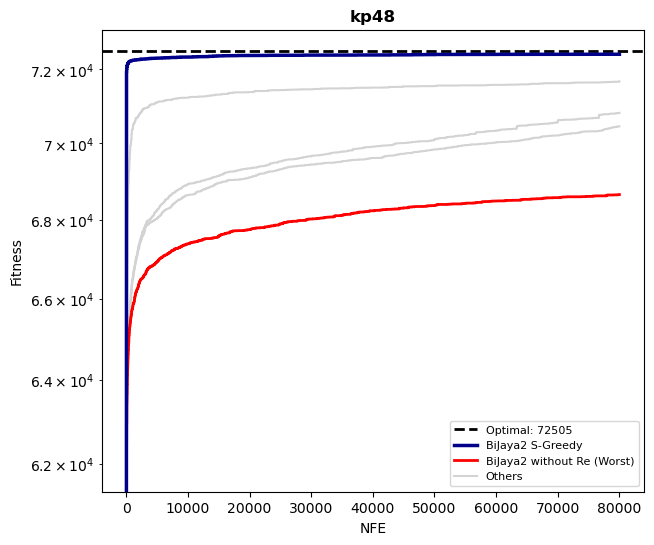

In [12]:
files = {
    'BiJaya2 S-Greedy': 'reinitialization (with SRO2)/BiJaya2_greedy/BiJaya2_Greedy_Re_Knapsack.csv',
    'BiJaya2 OBL': 'reinitialization (with SRO2)/BiJaya2_OBL/BiJaya2_OBL_Re_Knapsack.csv',
    'BiJaya2 Best+Random': 'reinitialization (with SRO2)/BiJaya2_best_AND_random/BiJaya2_best_random_Re_Knapsack.csv',
    'BiJaya2 Random': 'reinitialization (with SRO2)/BiJaya2_random/BiJaya2_Random_Re_Knapsack.csv',
    'BiJaya2 without Re': 'reinitialization (with SRO2)/BiJaya2_without_Re/BiJaya2_without_Re_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2 S-Greedy', 
    instances=['kp_31', 'kp_32', 'kp_33', 'kp34', 'kp_35', 'kp_36', 'kp_37', 'kp_38', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_43', 'kp_44', 'kp_45', 'kp_46', 'kp_47', 'kp_48'],
    plots_per_figure=4,  
    output_prefix='test_reinitialization_kp31_kp48_convergence' )

<h3 style = "color:blue;">r1 Convergence Plots Experiment (kp31-kp48)</h3>

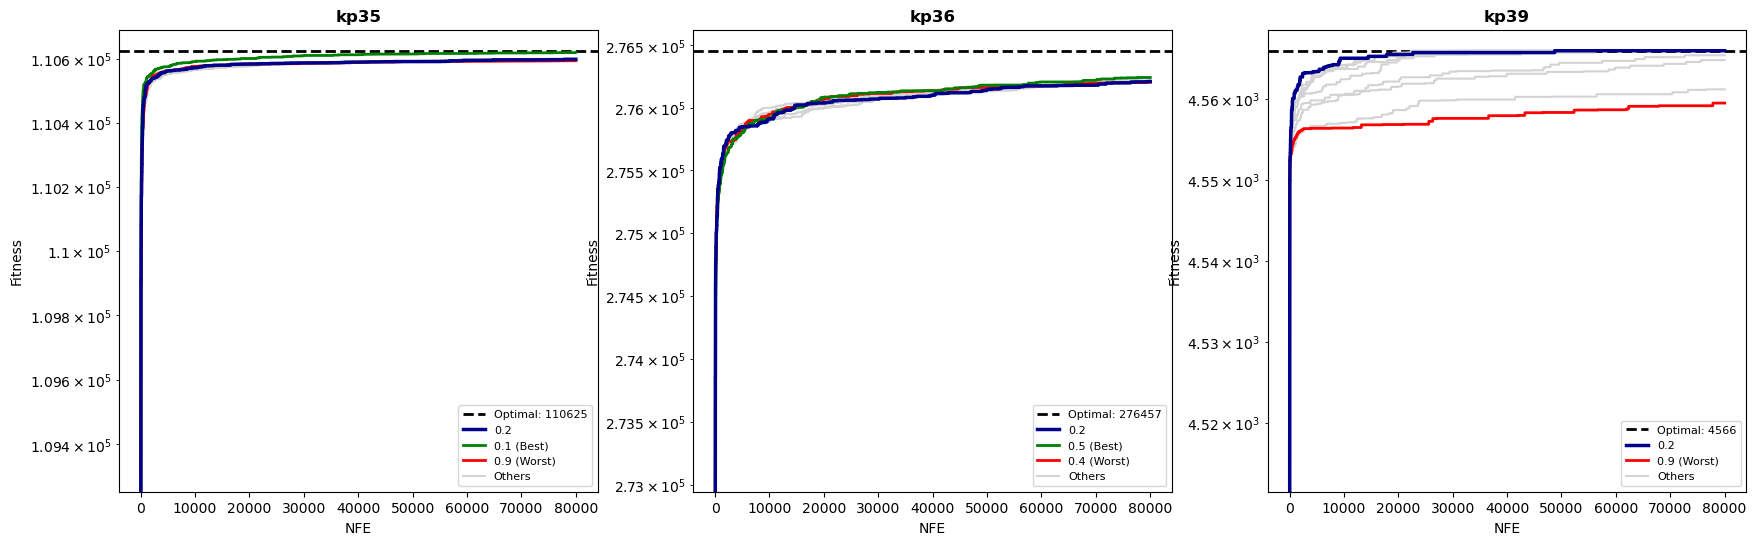

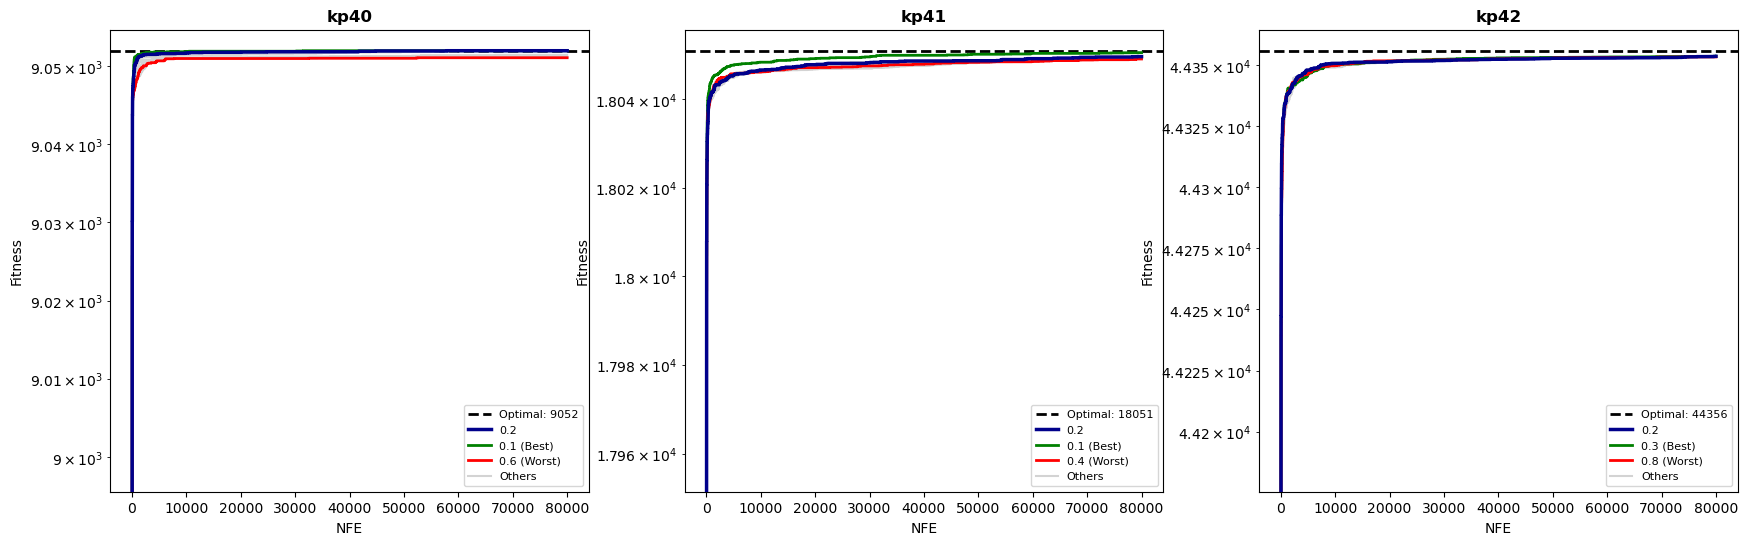

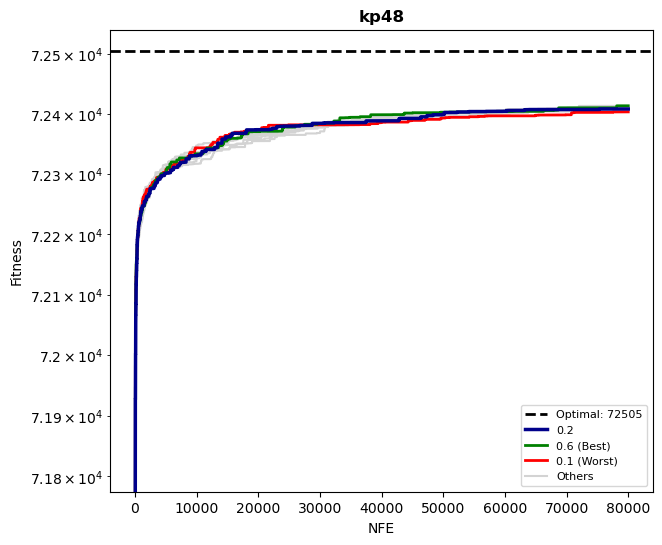

In [13]:
files = {
    '0.1': 'BiJaya2_r1/BiJaya2_r1_0.1/BiJaya2_r1_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r1/BiJaya2_r1_0.2/BiJaya2_r1_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r1/BiJaya2_r1_0.3/BiJaya2_r1_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r1/BiJaya2_r1_0.4/BiJaya2_r1_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r1/BiJaya2_r1_0.5/BiJaya2_r1_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r1/BiJaya2_r1_0.6/BiJaya2_r1_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r1/BiJaya2_r1_0.7/BiJaya2_r1_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r1/BiJaya2_r1_0.8/BiJaya2_r1_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r1/BiJaya2_r1_0.9/BiJaya2_r1_0.9_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='0.2', 
    instances=['kp_35', 'kp_36', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_48'], 
    plots_per_figure=3, 
    output_prefix='r1_kp31_kp48_convergence' )

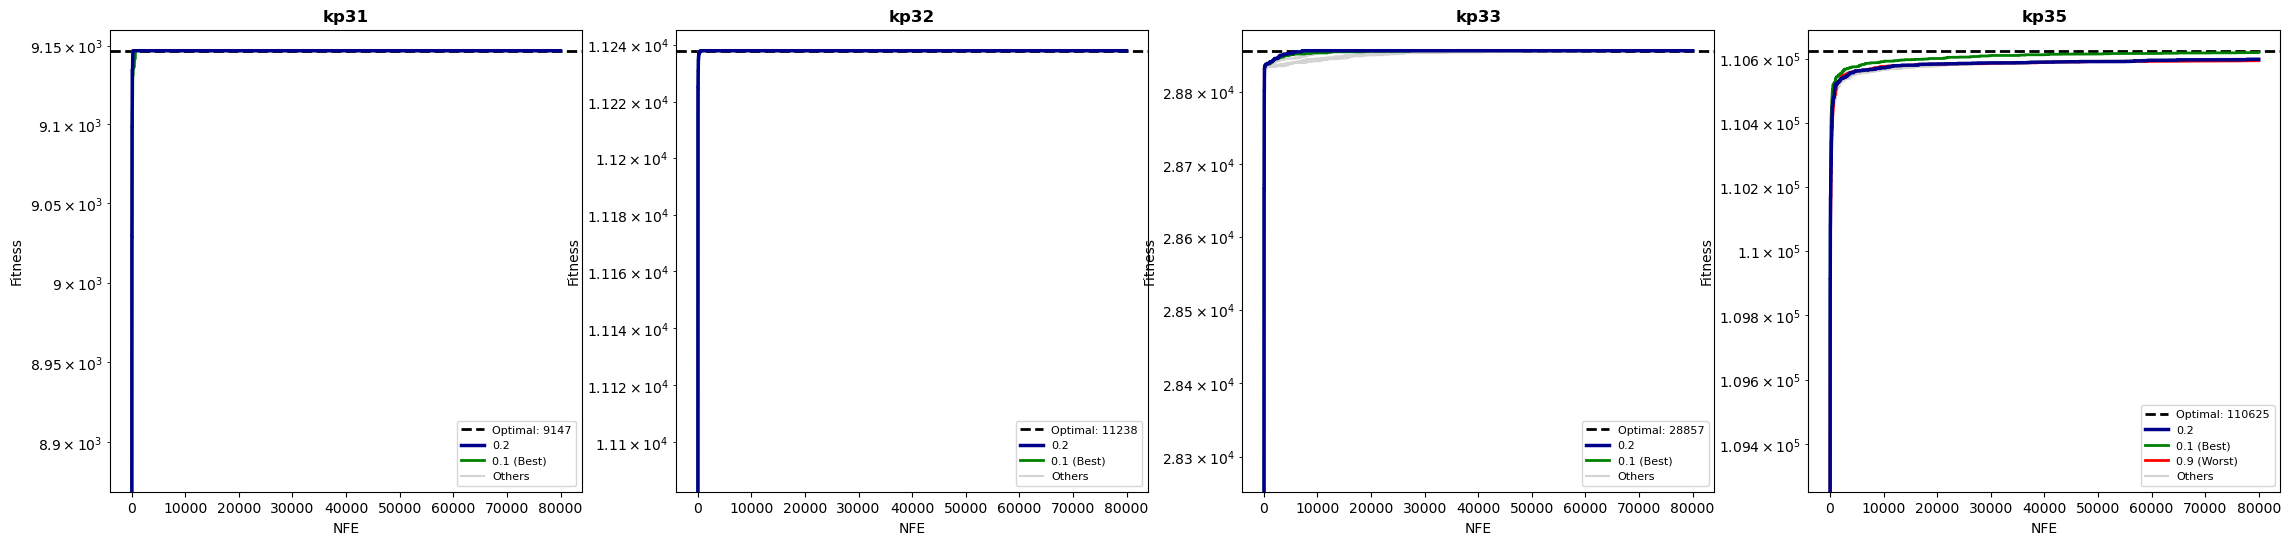

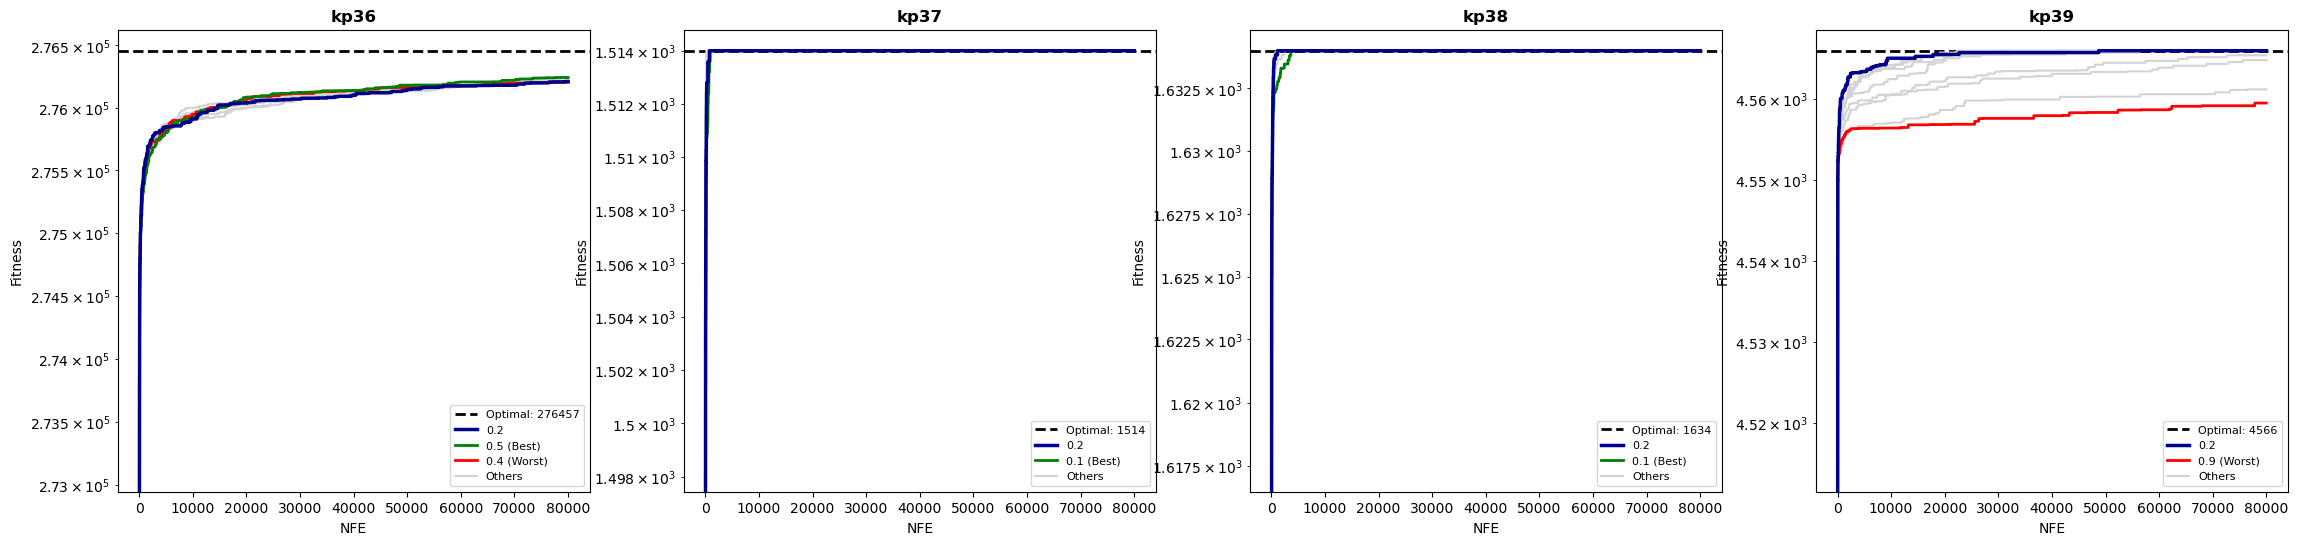

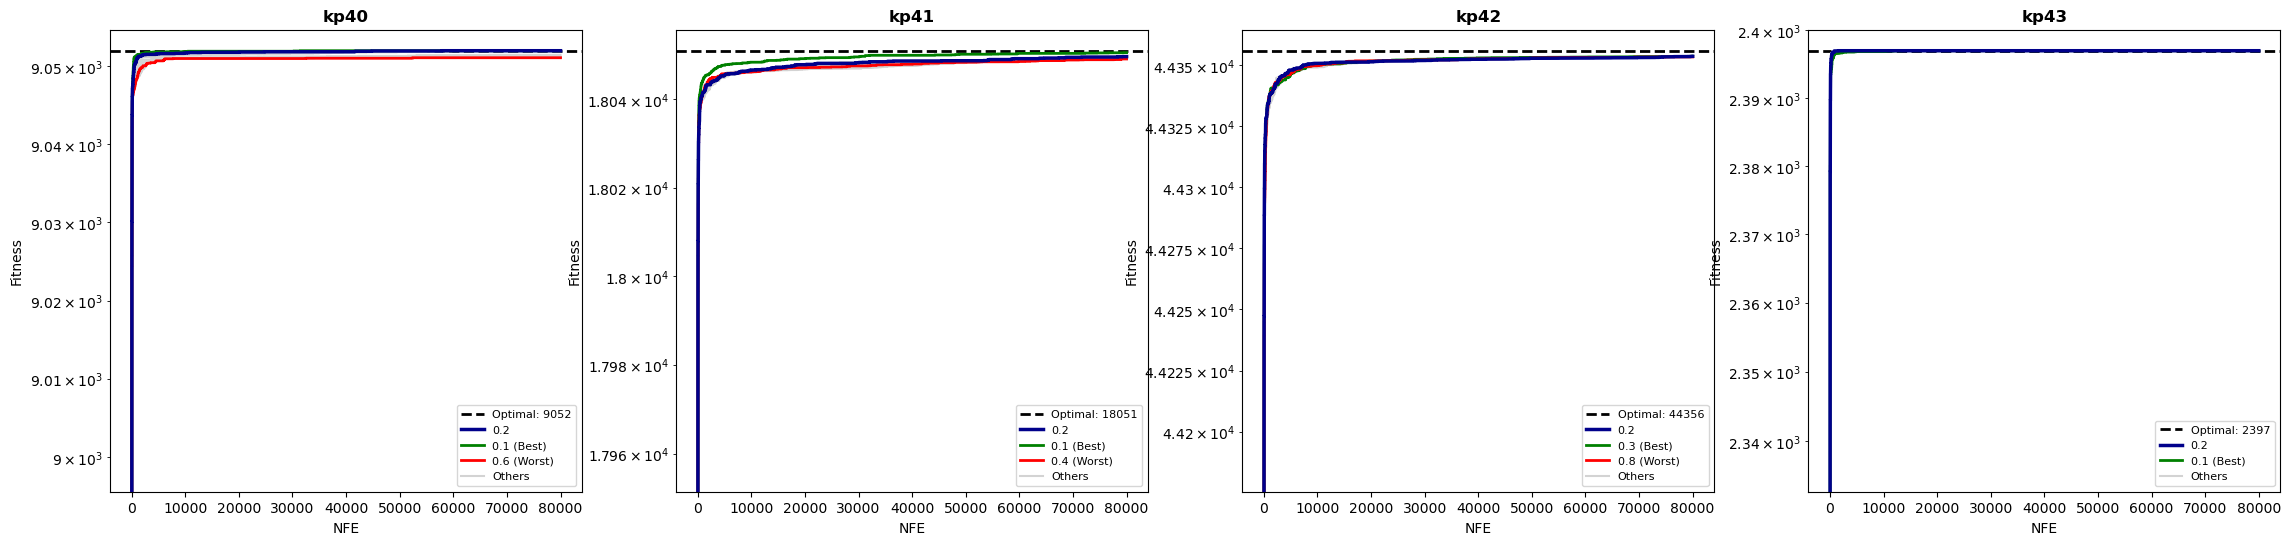

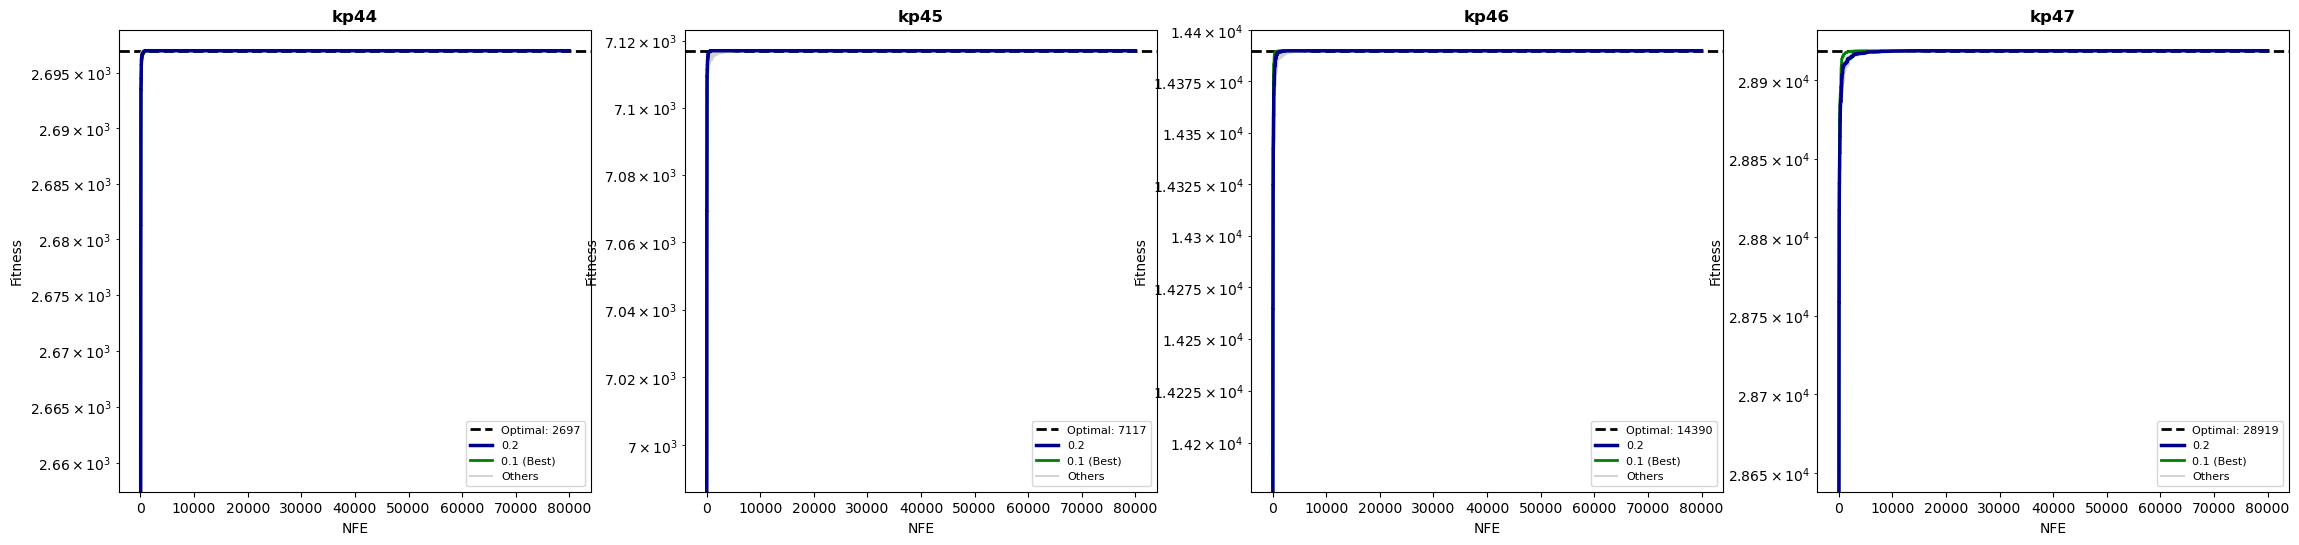

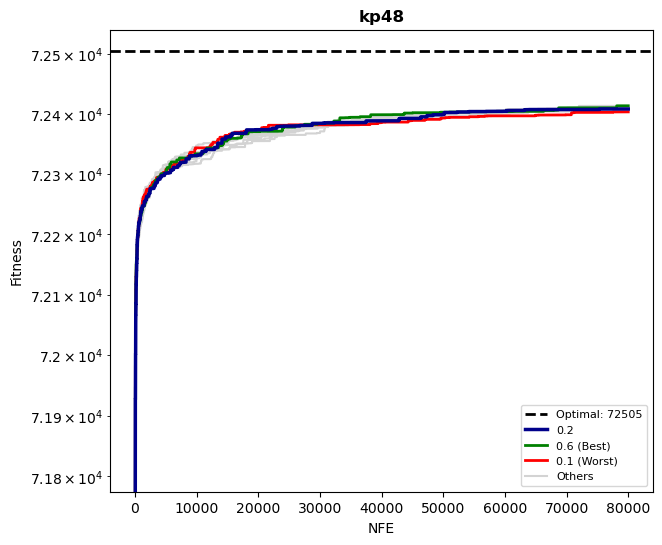

In [14]:
files = {
    '0.1': 'BiJaya2_r1/BiJaya2_r1_0.1/BiJaya2_r1_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r1/BiJaya2_r1_0.2/BiJaya2_r1_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r1/BiJaya2_r1_0.3/BiJaya2_r1_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r1/BiJaya2_r1_0.4/BiJaya2_r1_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r1/BiJaya2_r1_0.5/BiJaya2_r1_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r1/BiJaya2_r1_0.6/BiJaya2_r1_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r1/BiJaya2_r1_0.7/BiJaya2_r1_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r1/BiJaya2_r1_0.8/BiJaya2_r1_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r1/BiJaya2_r1_0.9/BiJaya2_r1_0.9_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='0.2', 
    instances=['kp_31', 'kp_32', 'kp_33', 'kp34', 'kp_35', 'kp_36', 'kp_37', 'kp_38', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_43', 'kp_44', 'kp_45', 'kp_46', 'kp_47', 'kp_48'],
    plots_per_figure=4, 
    output_prefix='test_r1_kp31_kp48_convergence' )

<h3 style = "color:blue;">r2 Convergence Plots Experiment (kp31-kp48)</h3>

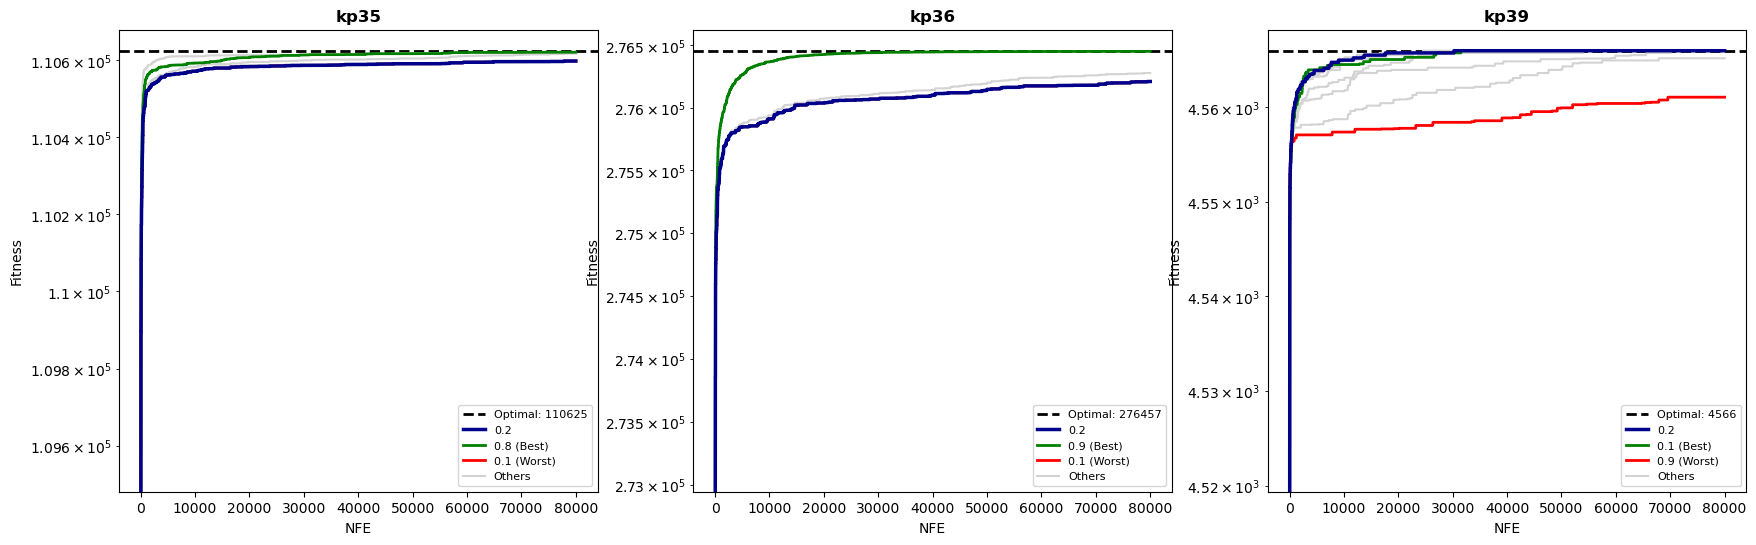

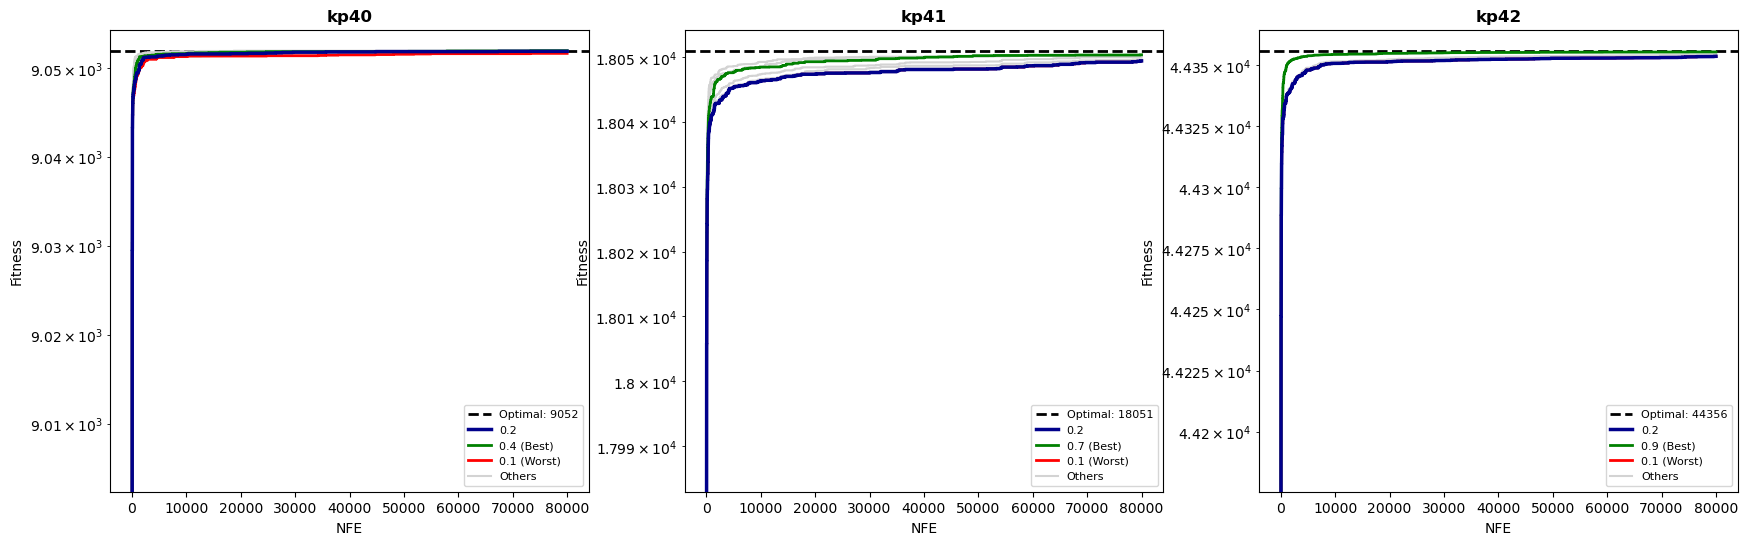

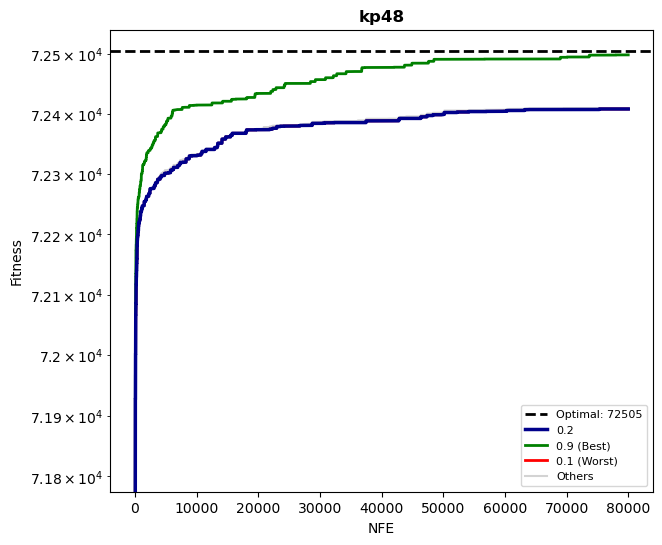

In [15]:
files = {
    '0.1': 'BiJaya2_r2/BiJaya2_r2_0.1/BiJaya2_r2_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r2/BiJaya2_r2_0.2/BiJaya2_r2_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r2/BiJaya2_r2_0.3/BiJaya2_r2_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r2/BiJaya2_r2_0.4/BiJaya2_r2_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r2/BiJaya2_r2_0.5/BiJaya2_r2_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r2/BiJaya2_r2_0.6/BiJaya2_r2_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r2/BiJaya2_r2_0.7/BiJaya2_r2_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r2/BiJaya2_r2_0.8/BiJaya2_r2_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r2/BiJaya2_r2_0.9/BiJaya2_r2_0.9_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='0.2', 
    instances=['kp_35', 'kp_36', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_48'], 
    plots_per_figure=3, 
    output_prefix='r2_kp31_kp48_convergence' )

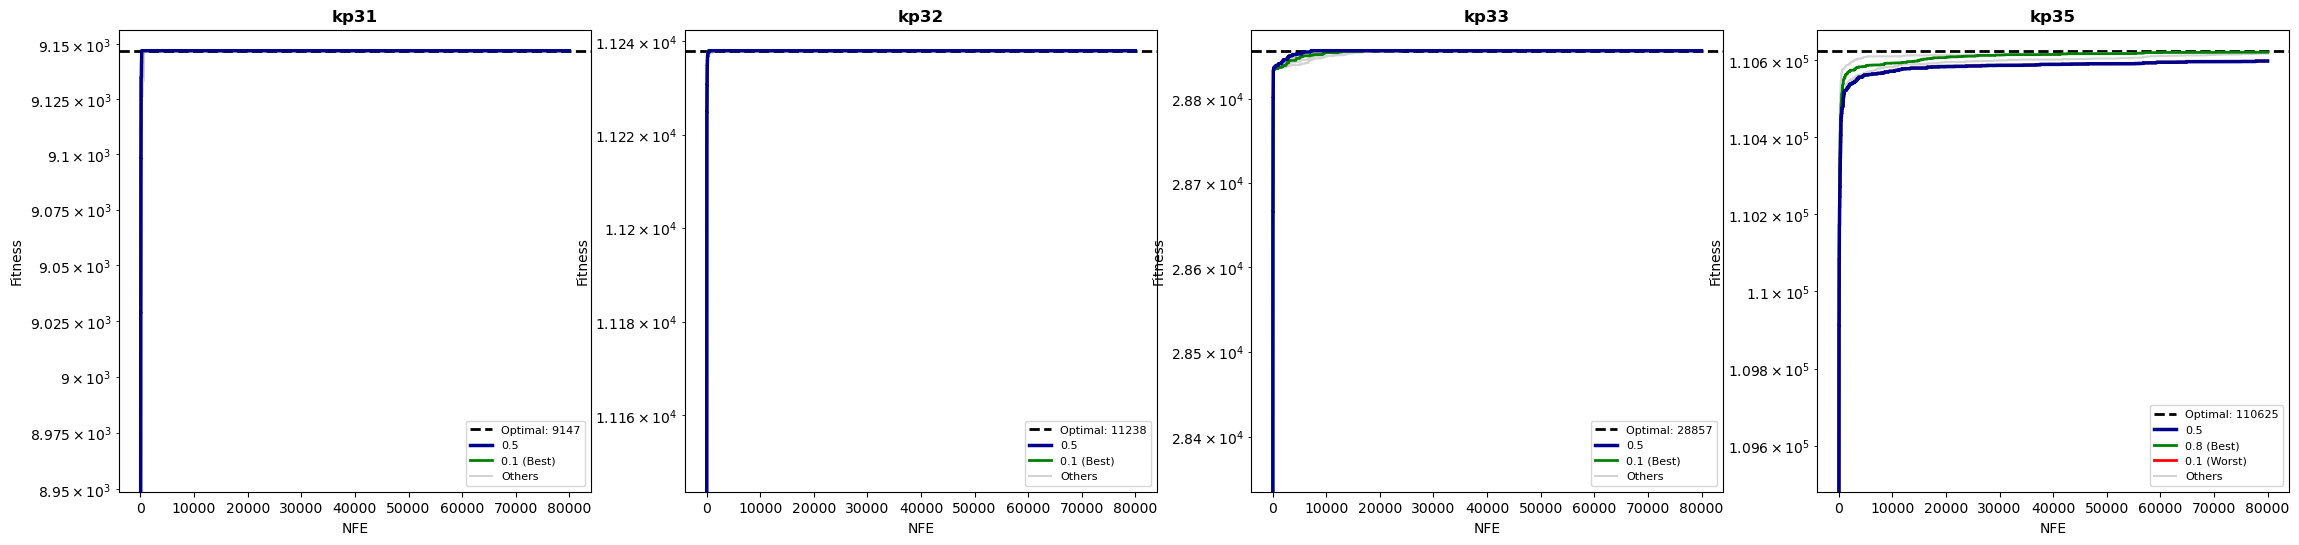

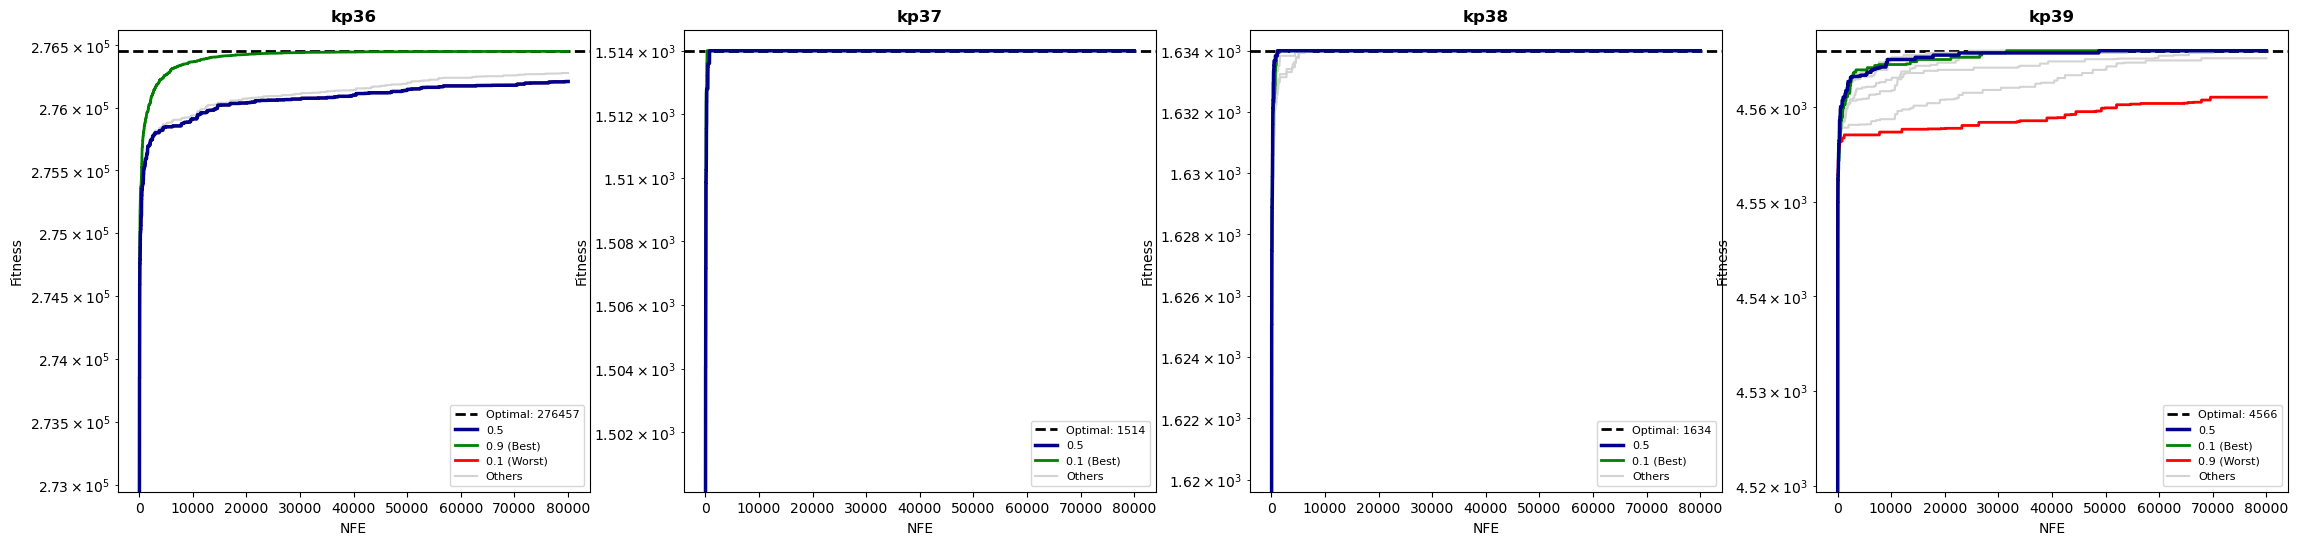

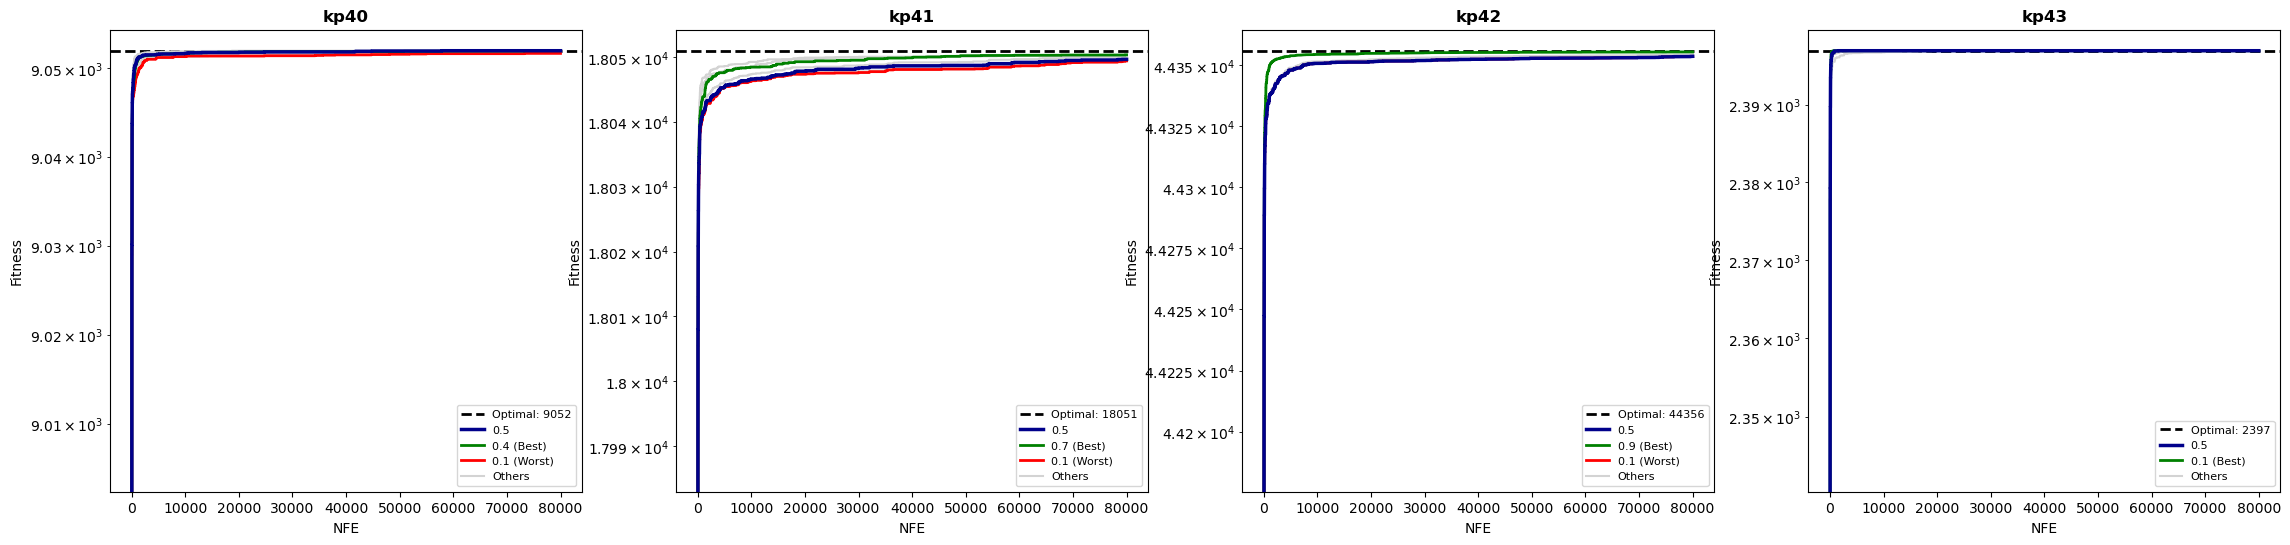

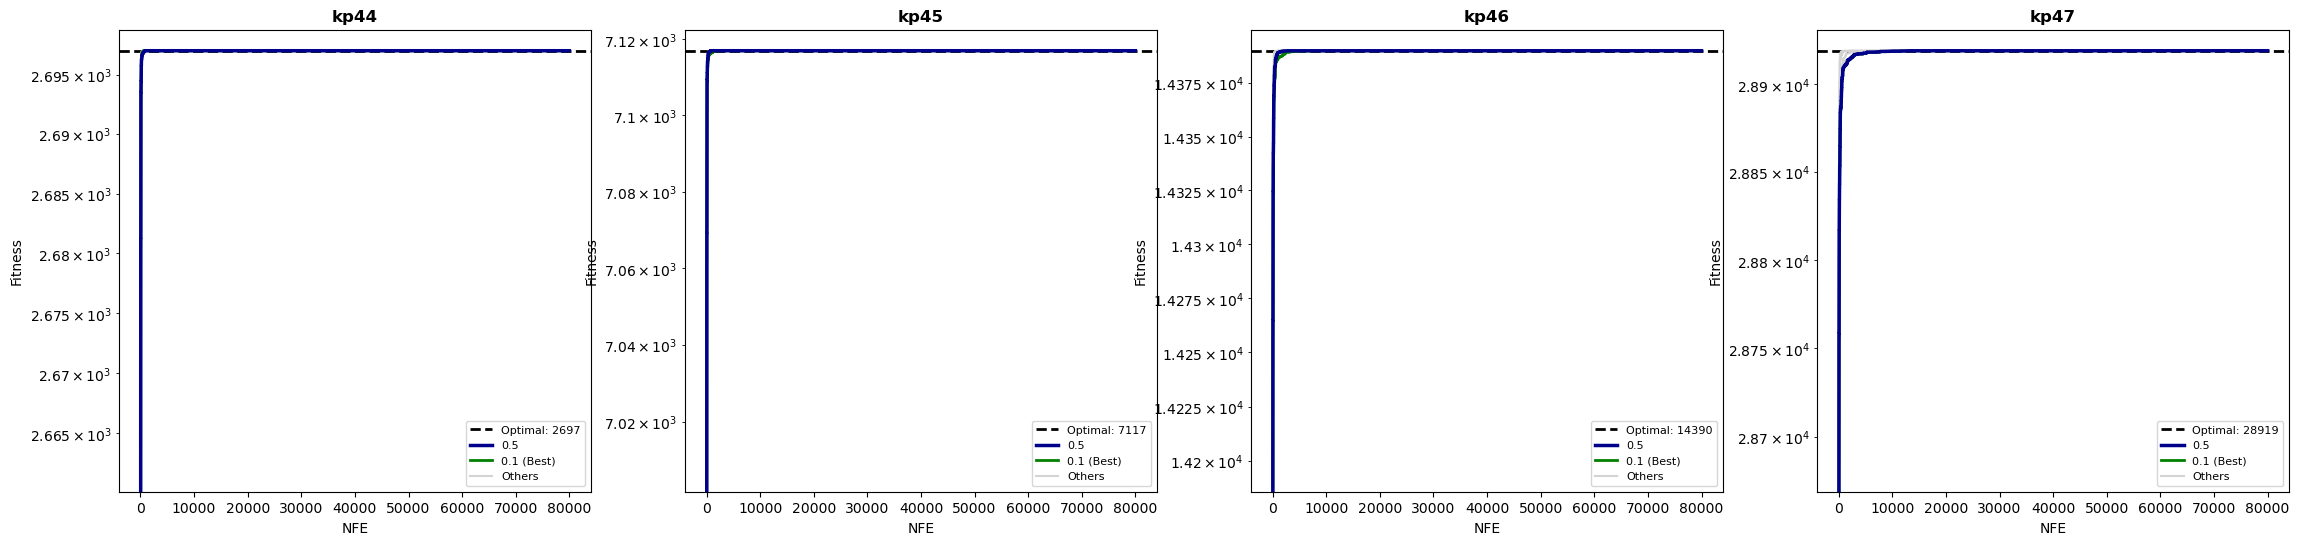

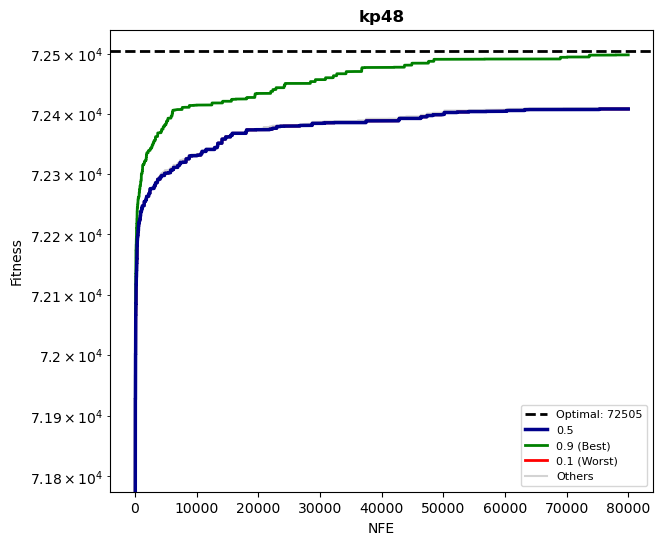

In [16]:
files = {
    '0.1': 'BiJaya2_r2/BiJaya2_r2_0.1/BiJaya2_r2_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r2/BiJaya2_r2_0.2/BiJaya2_r2_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r2/BiJaya2_r2_0.3/BiJaya2_r2_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r2/BiJaya2_r2_0.4/BiJaya2_r2_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r2/BiJaya2_r2_0.5/BiJaya2_r2_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r2/BiJaya2_r2_0.6/BiJaya2_r2_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r2/BiJaya2_r2_0.7/BiJaya2_r2_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r2/BiJaya2_r2_0.8/BiJaya2_r2_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r2/BiJaya2_r2_0.9/BiJaya2_r2_0.9_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='0.5', 
    instances=['kp_31', 'kp_32', 'kp_33', 'kp34', 'kp_35', 'kp_36', 'kp_37', 'kp_38', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_43', 'kp_44', 'kp_45', 'kp_46', 'kp_47', 'kp_48'],
    plots_per_figure=4, 
    output_prefix='test_r2_kp31_kp48_convergence' )

<h3 style = "color:blue;">Jaya Variants Convergence Plots Experiment (kp31-kp48)</h3>

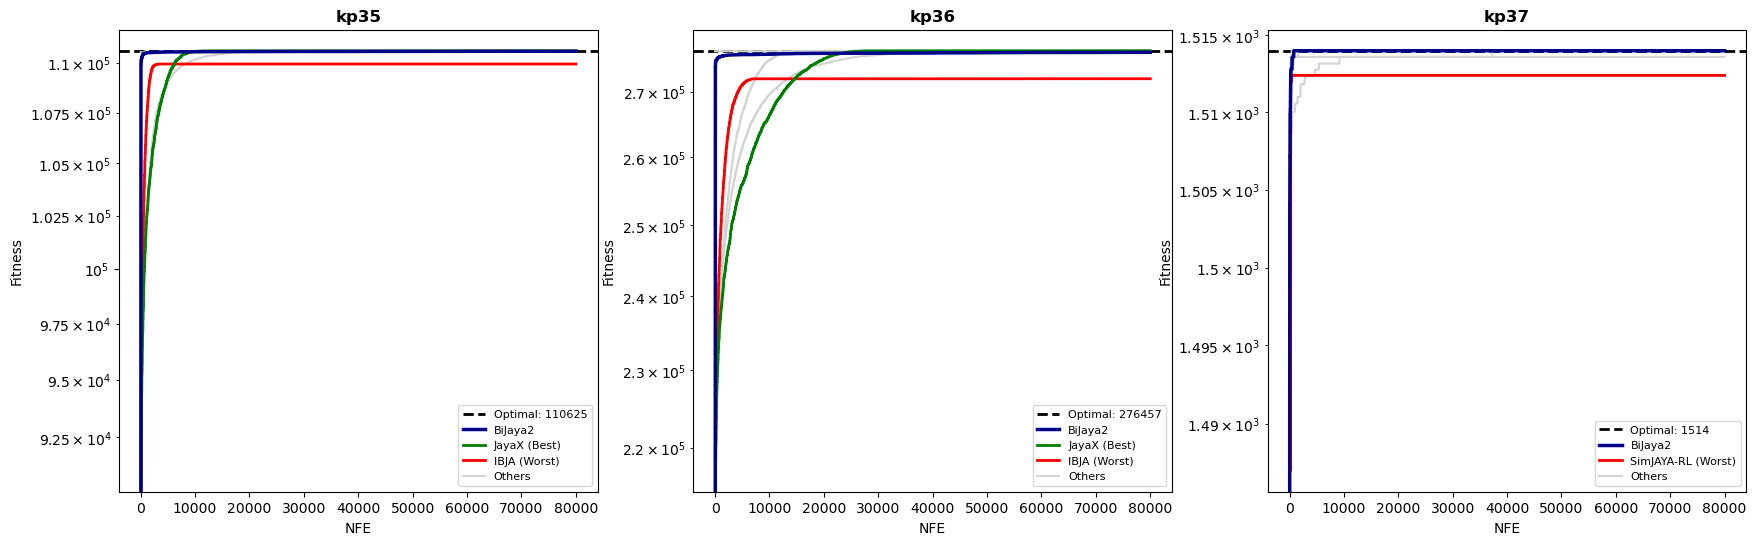

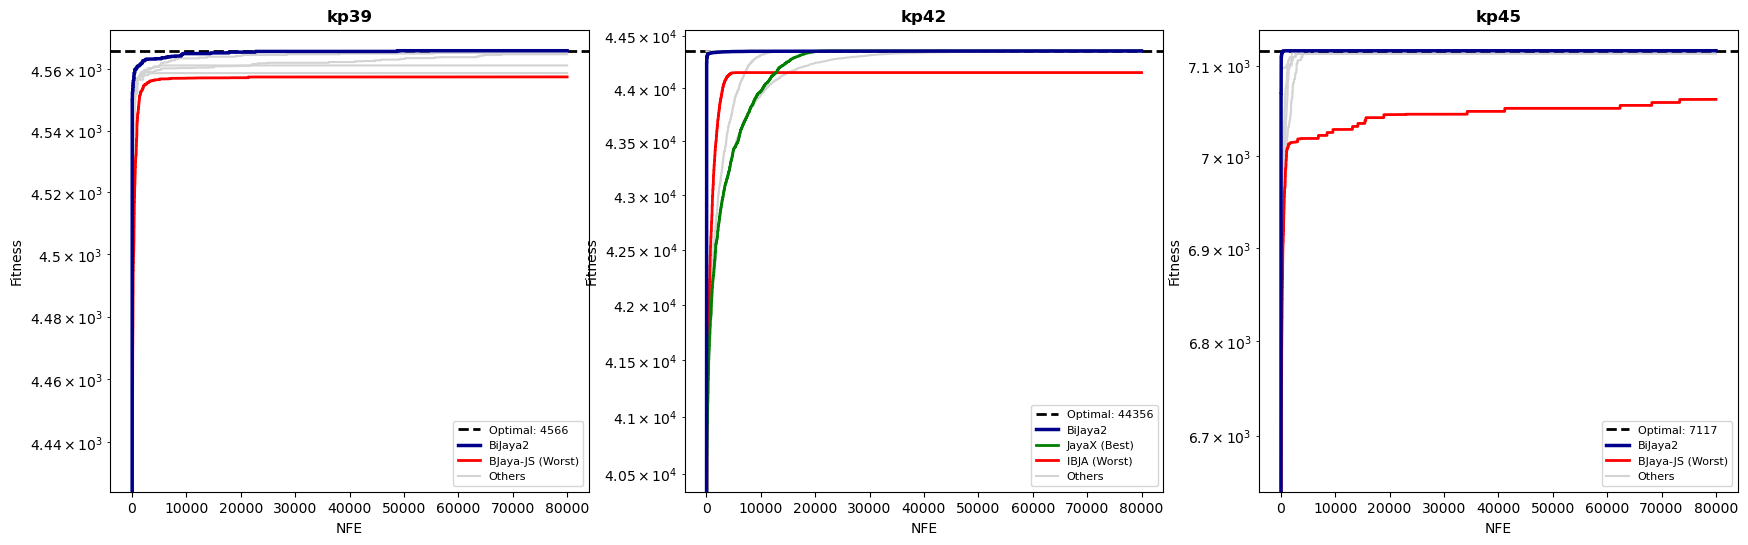

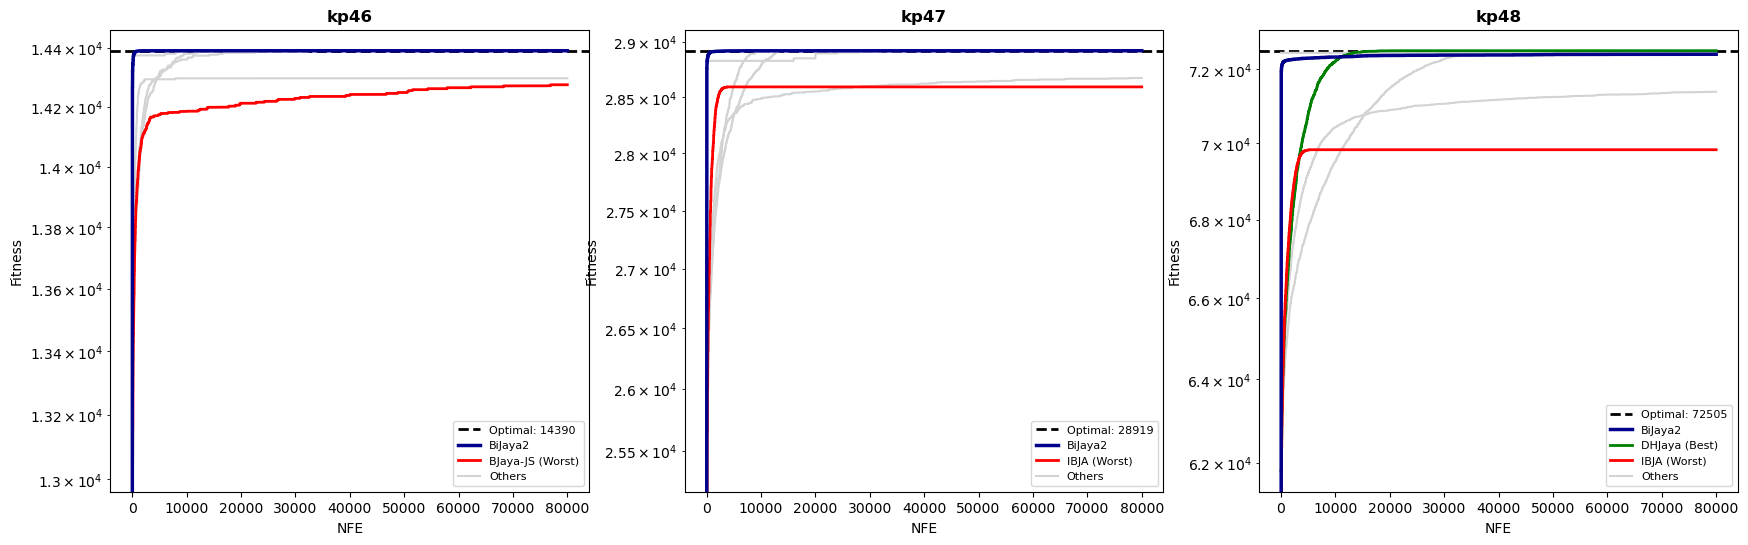

In [17]:
files = {
    'BiJaya2': 'Jaya variants/Jaya2_SRO/BiJaya2_Knapsack.csv',
    'BJaya-JS': 'Jaya variants/Jaya-JS RO/BJayaJS_Knapsack.csv',
    'DHJaya': 'Jaya variants/DHJaya RO/DHJaya_Knapsack.csv',
    'IBJA': 'Jaya variants/IBJaya/IBJaya_Knapsack.csv',
    'JayaX': 'Jaya variants/JayaX RO/JayaX_Knapsack.csv',
    'SimJAYA-RL': 'Jaya variants/SimBJAYA-RL RO/SimJAYA_RL_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2', 
    instances=['kp_35', 'kp_36', 'kp_37', 'kp_39', 'kp_42', 'kp_45', 'kp_46', 'kp_47', 'kp_48'],
    plots_per_figure=3, 
    output_prefix='test1_Jaya_Varaints_large_kp31_kp48_convergence' )

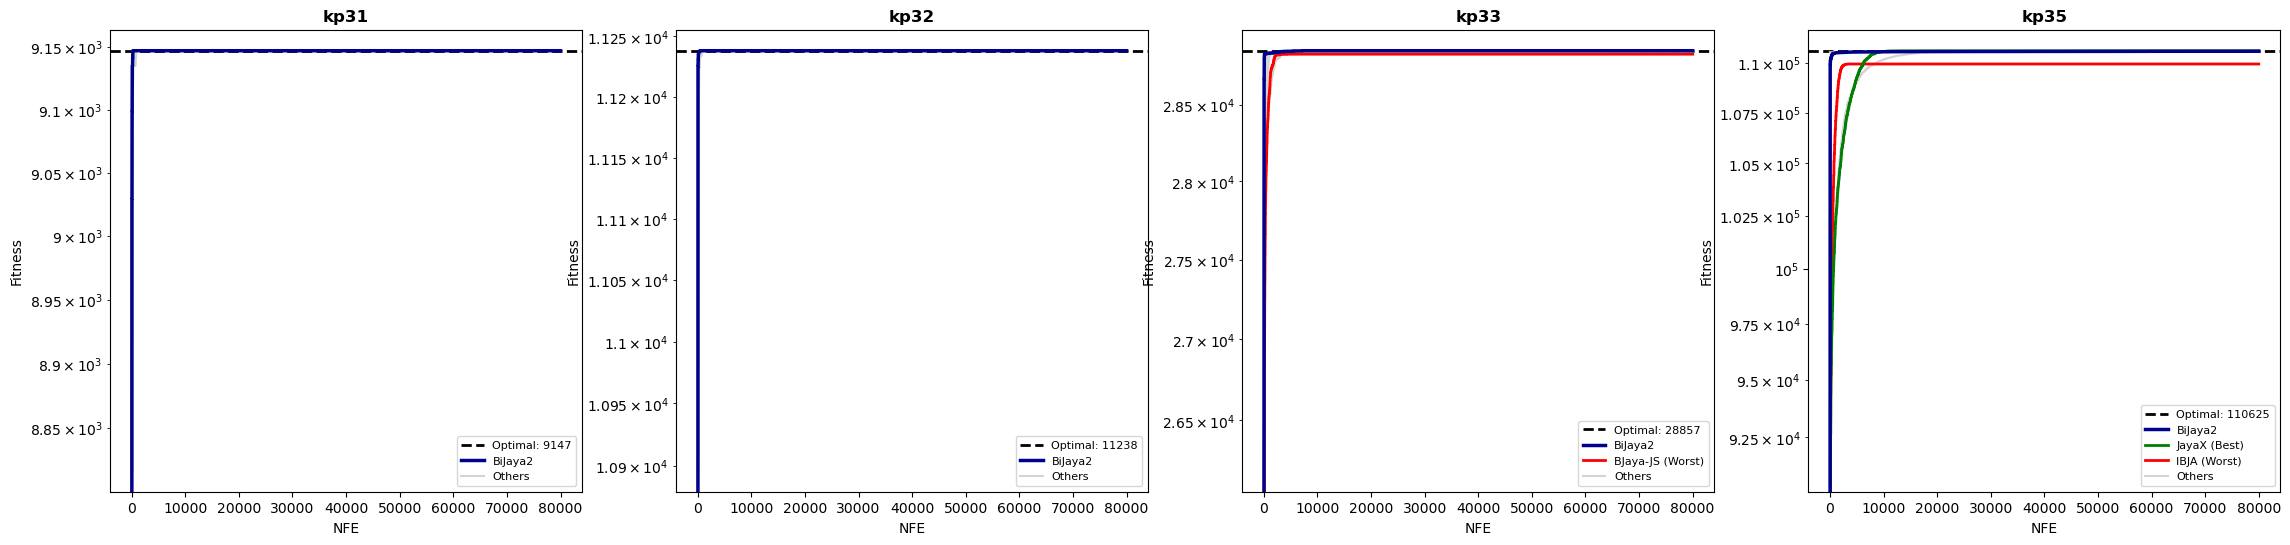

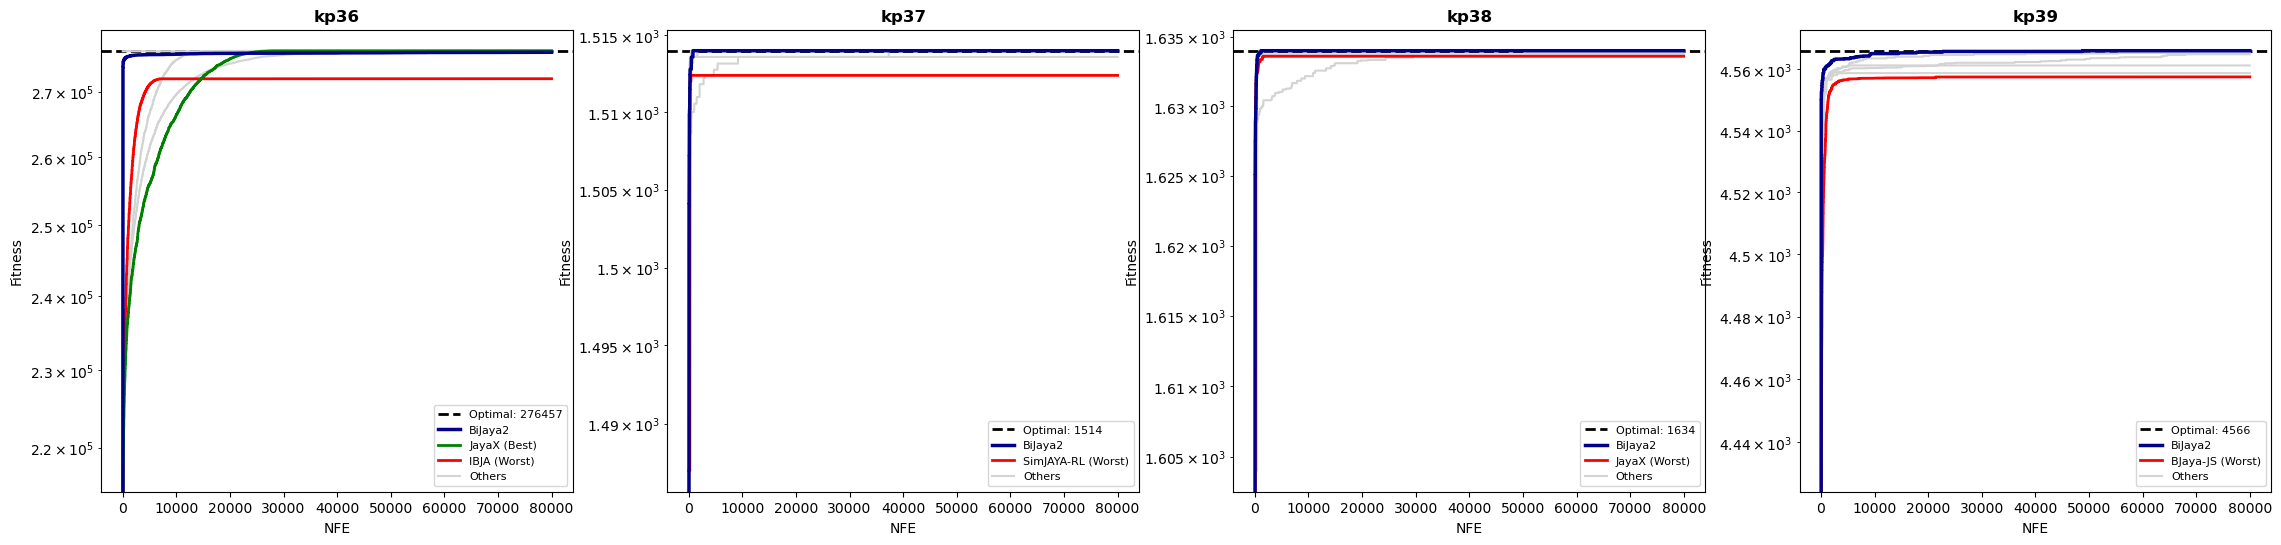

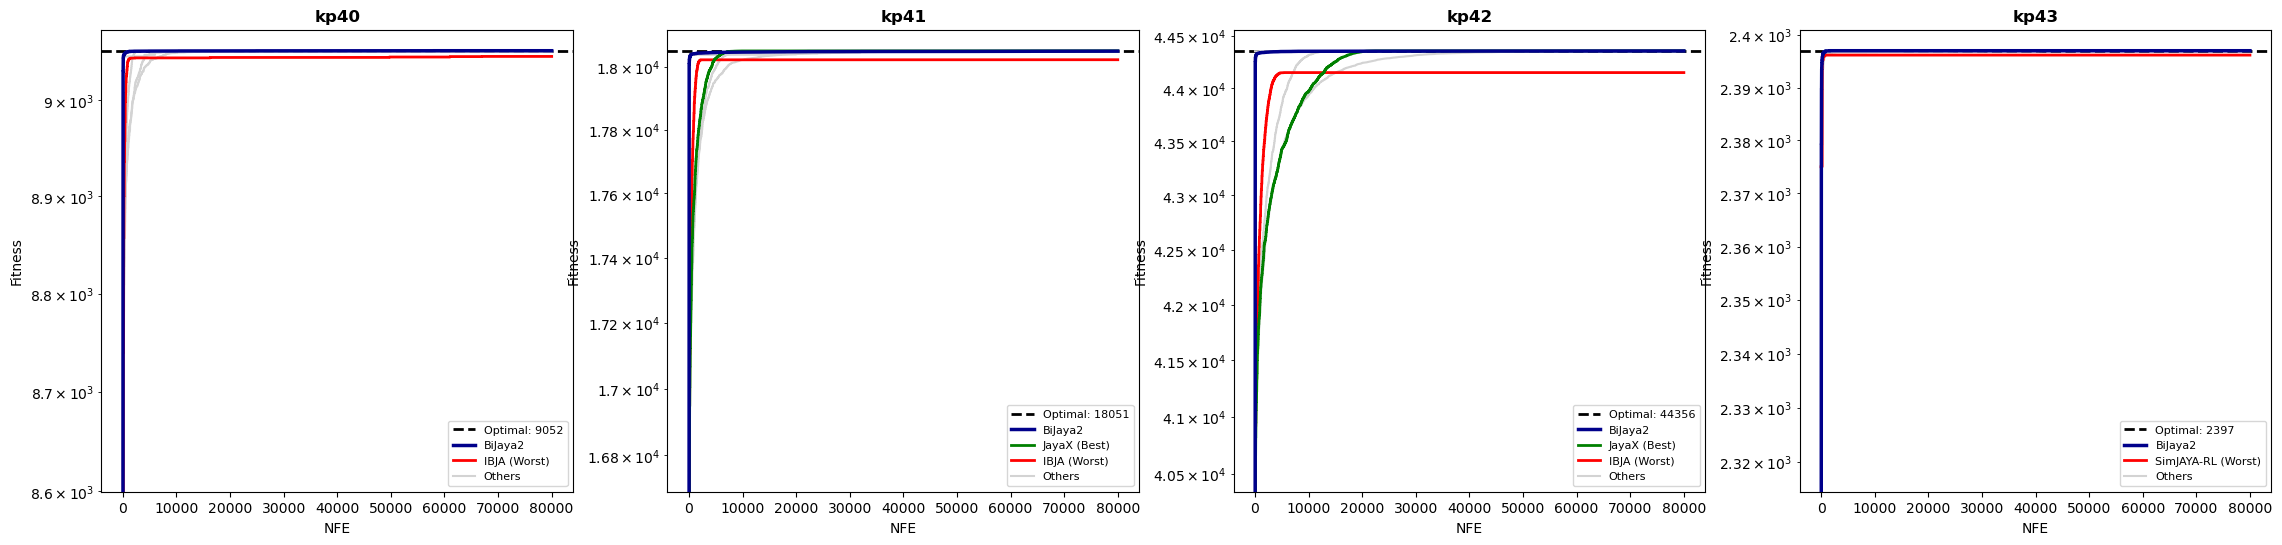

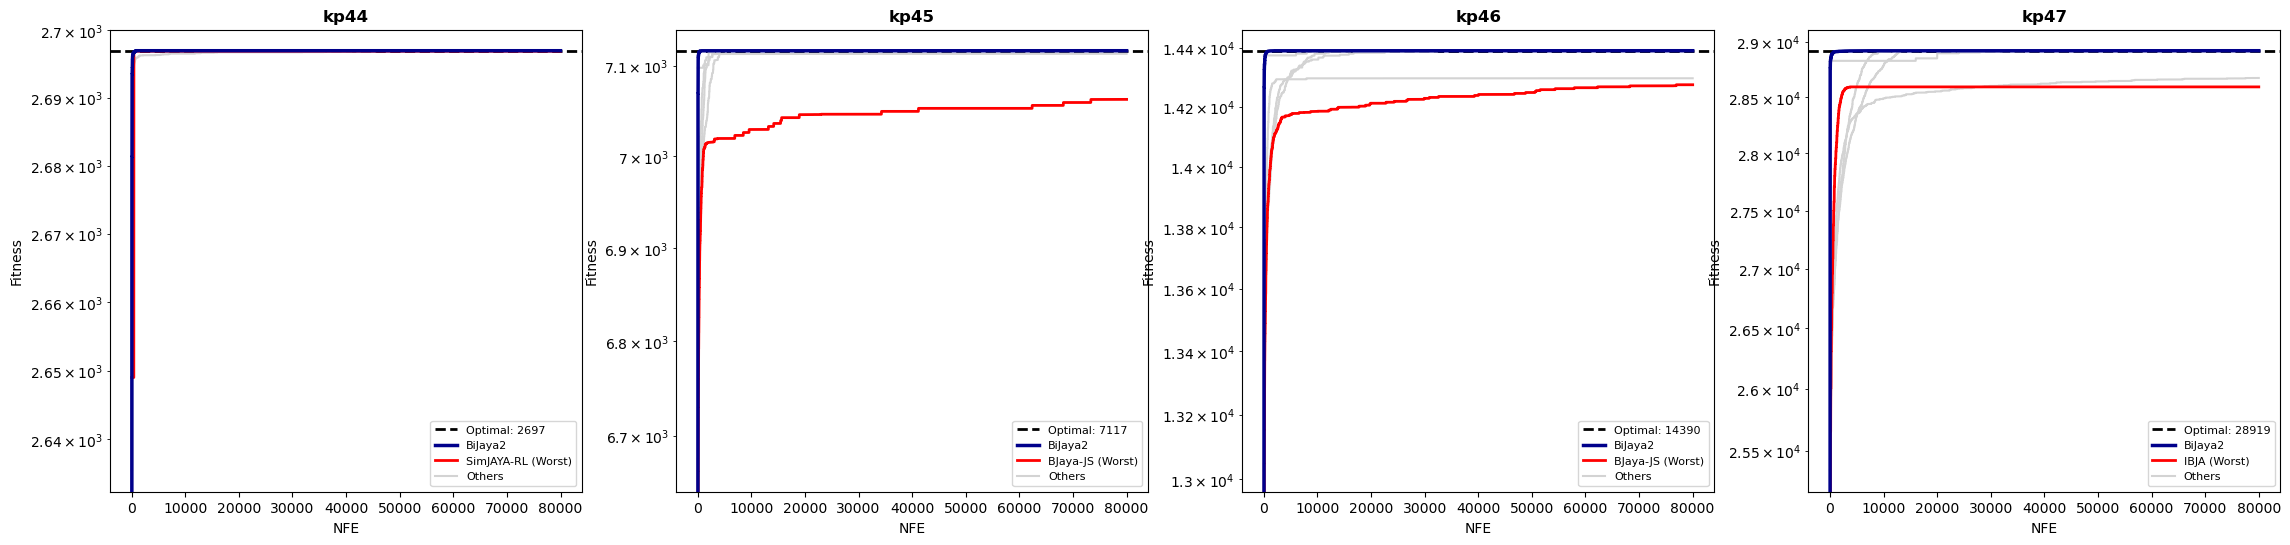

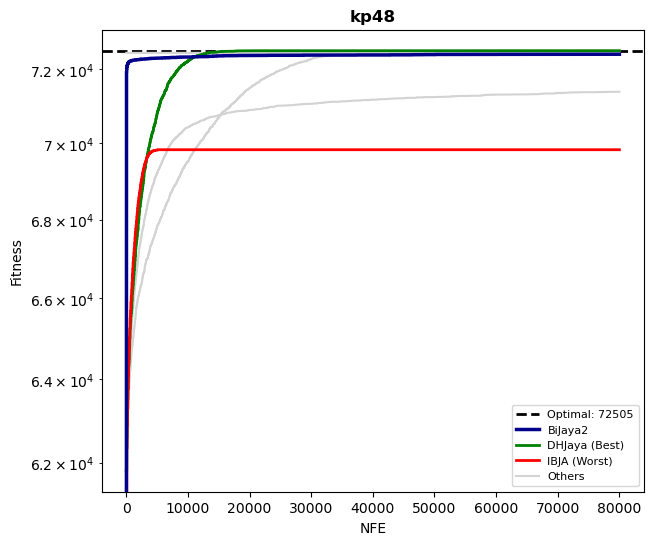

In [18]:
files = {
    'BiJaya2': 'Jaya variants/Jaya2_SRO/BiJaya2_Knapsack.csv',
    'BJaya-JS': 'Jaya variants/Jaya-JS RO/BJayaJS_Knapsack.csv',
    'DHJaya': 'Jaya variants/DHJaya RO/DHJaya_Knapsack.csv',
    'IBJA': 'Jaya variants/IBJaya/IBJaya_Knapsack.csv',
    'JayaX': 'Jaya variants/JayaX RO/JayaX_Knapsack.csv',
    'SimJAYA-RL': 'Jaya variants/SimBJAYA-RL RO/SimJAYA_RL_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2', 
    instances=['kp_31', 'kp_32', 'kp_33', 'kp34', 'kp_35', 'kp_36', 'kp_37', 'kp_38', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_43', 'kp_44', 'kp_45', 'kp_46', 'kp_47', 'kp_48'],
    plots_per_figure=4, 
    output_prefix='Jaya_Varaints_large_kp31_kp48_convergence' )

<h3 style = "color:blue;">6 Algorithm Convergence Plots Experiment (kp1-kp30)</h3>

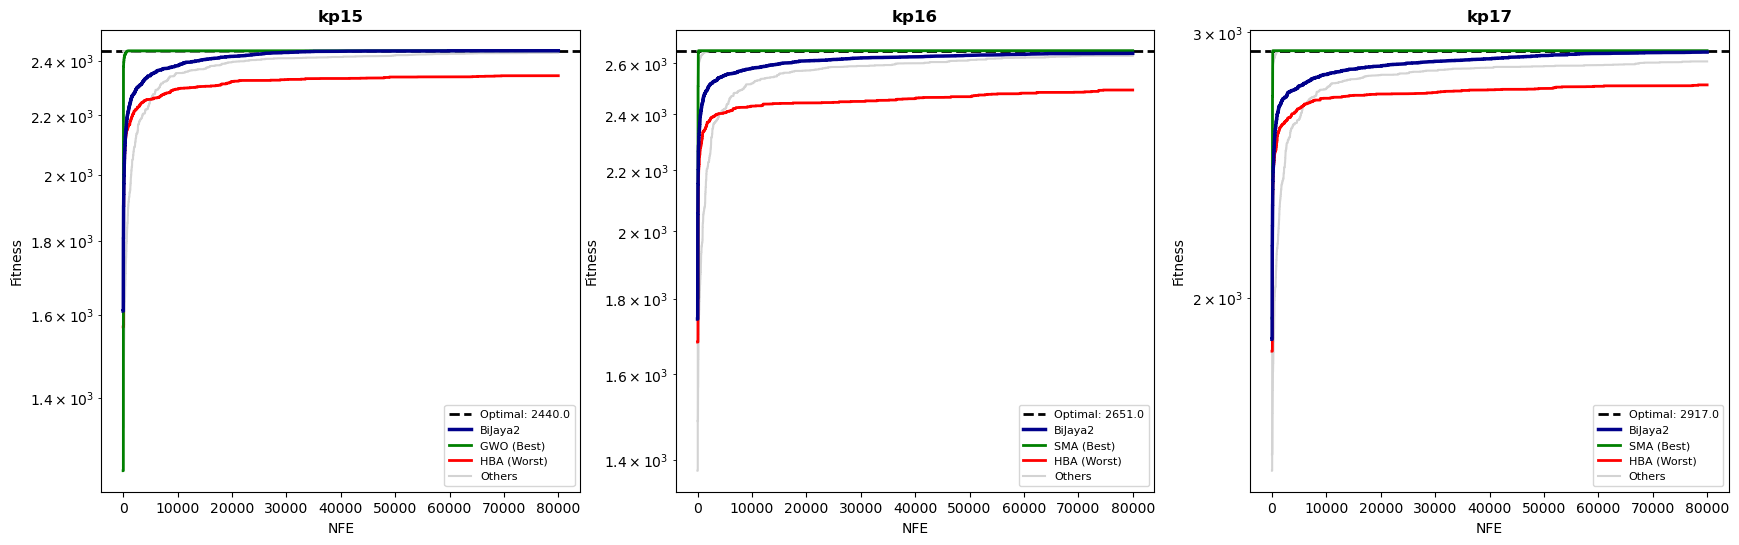

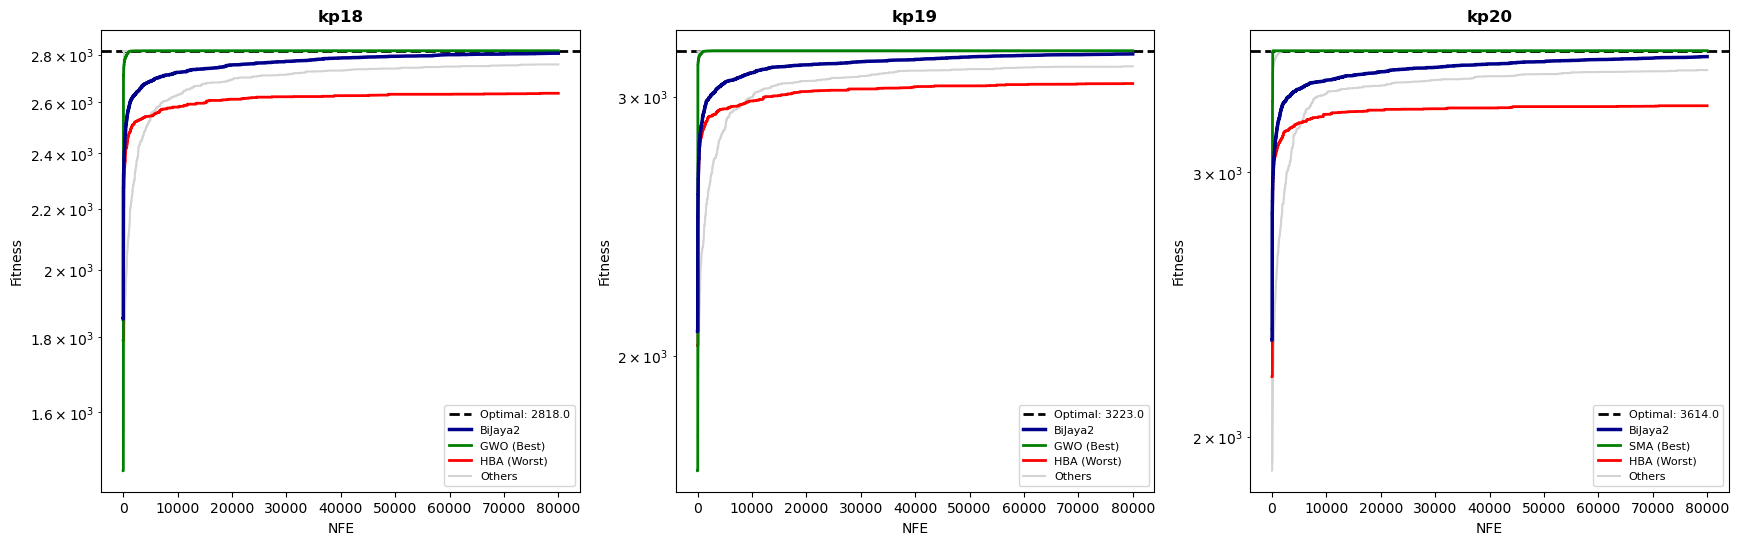

In [19]:
files = {
    'BiJaya2': '6 Algorithms (small instances)/BiJaya (without SRO2)/BiJaya2_withoutSRO2_small_Knapsack.csv',
    'SMA': '6 Algorithms (small instances)/SMA/SMA_Knapsack.csv',
    'PSA': '6 Algorithms (small instances)/PSA/PSA_Knapsack.csv',
    #'SCA': '6 Algorithms (small instances)/SCA/SCA_Knapsack.csv',
    'HBA': '6 Algorithms (small instances)/HBA (without RO)/HBA_Knapsack.csv',
    'GWO': '6 Algorithms (small instances)/GWO/GWO_Knapsack.csv',
    'BMPA': '6 Algorithms (small instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2', 
    instances=['kp_15', 'kp_16', 'kp_17', 'kp_18', 'kp_19', 'kp_20'],
    plots_per_figure=3, 
    output_prefix='6algo_small_kp1_kp30_convergence' )

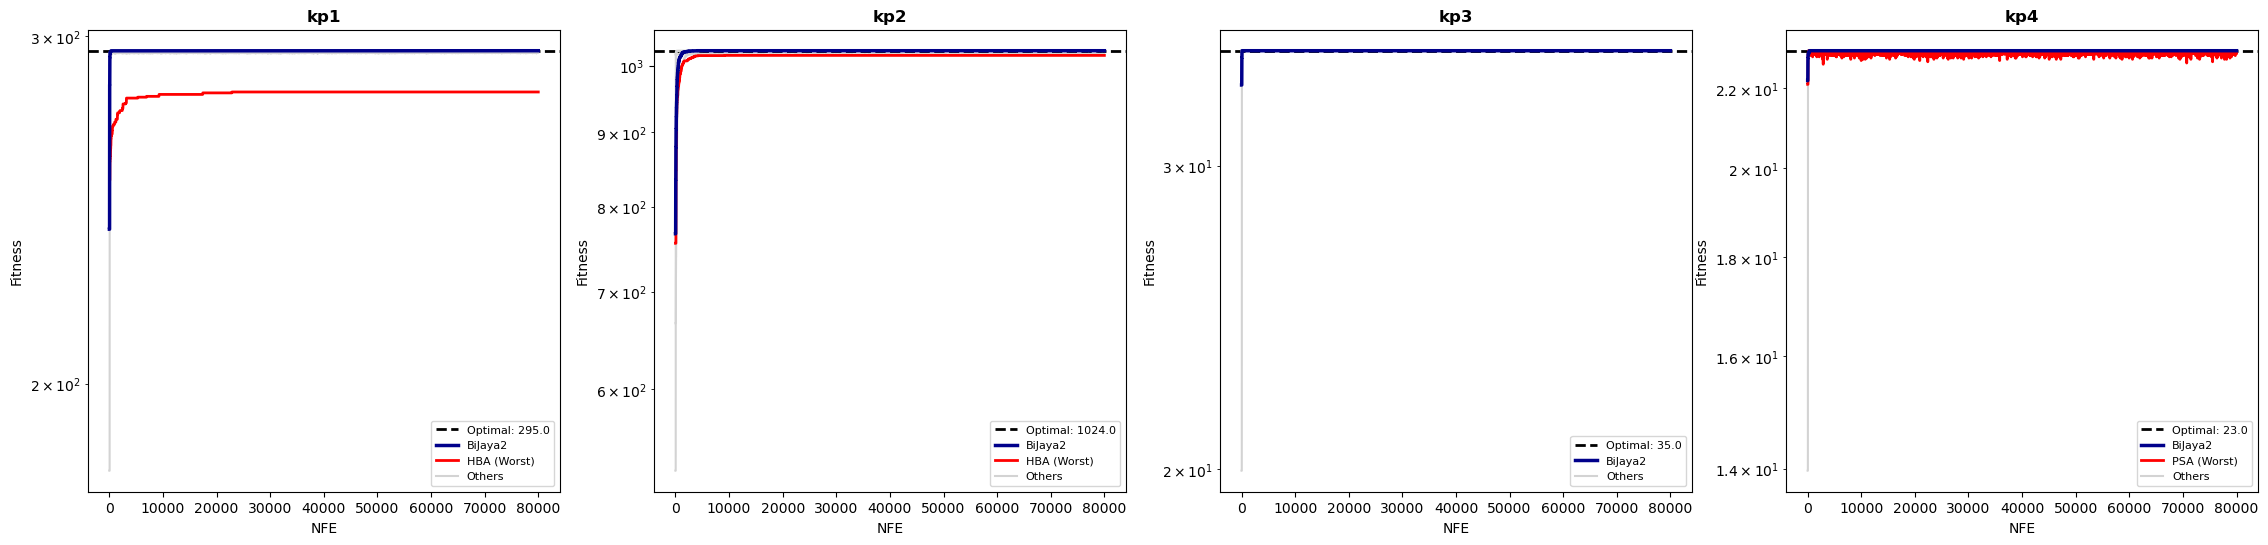

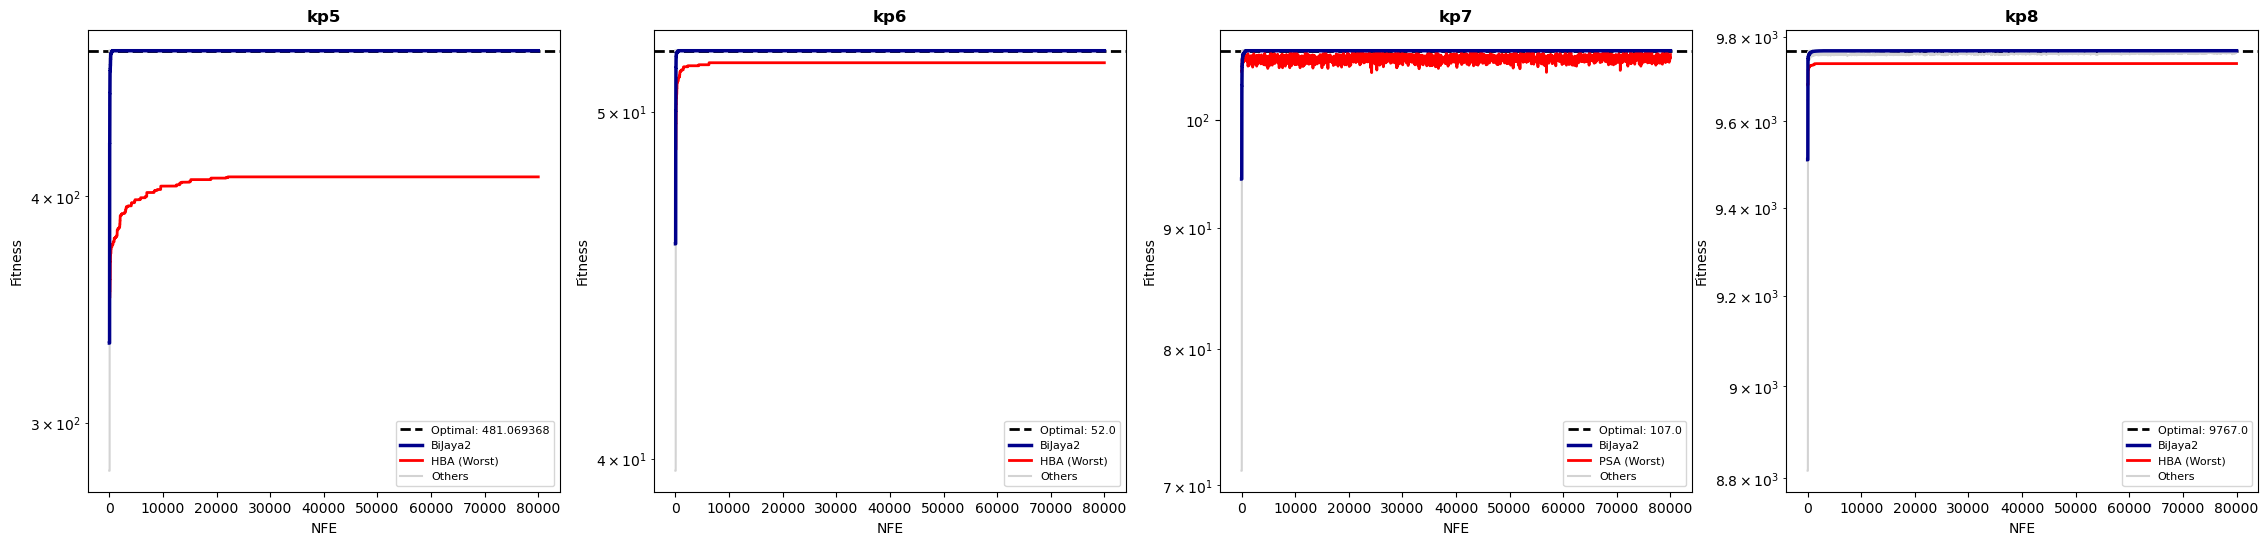

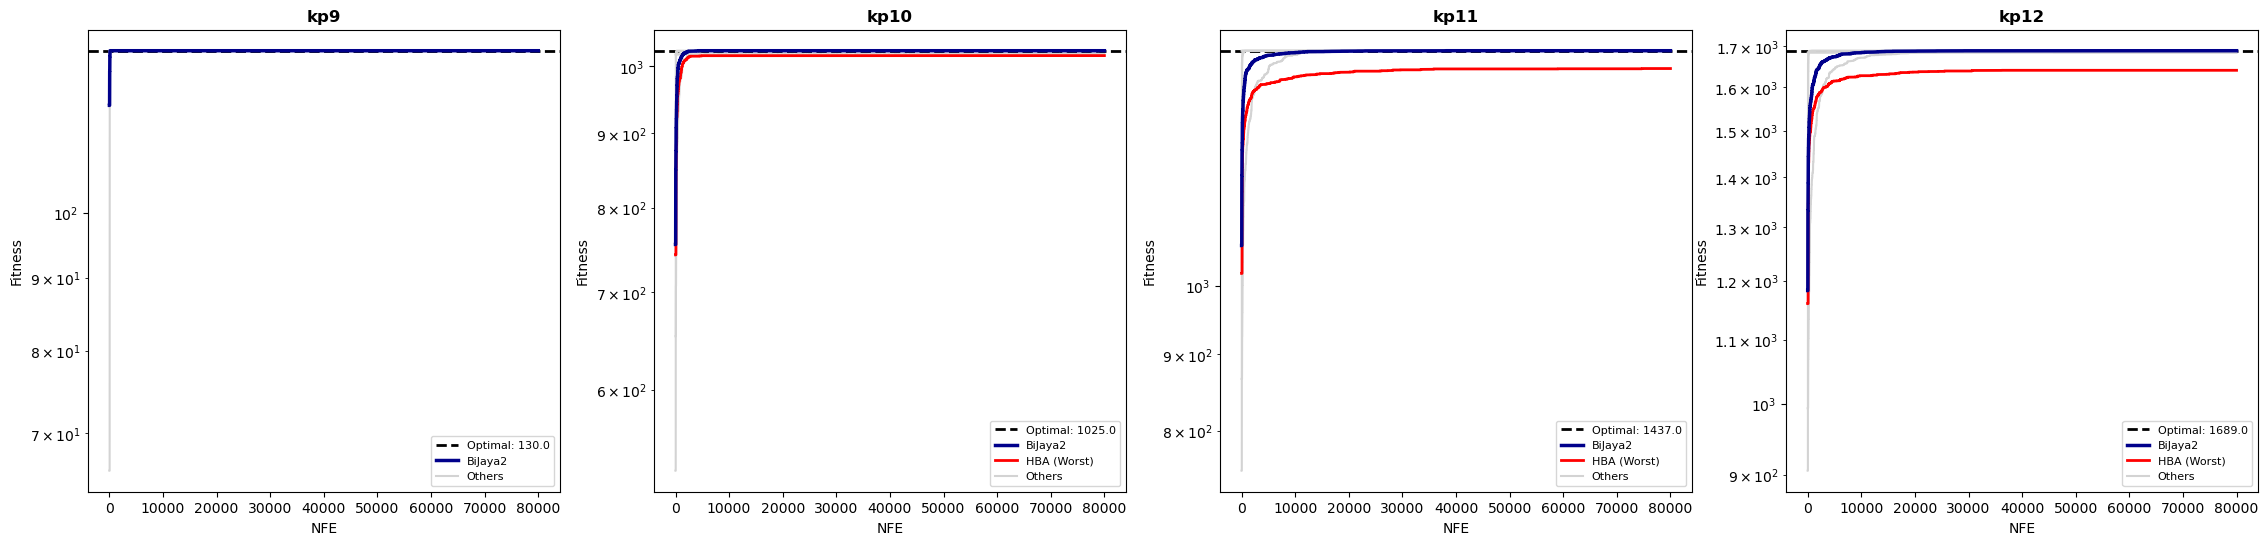

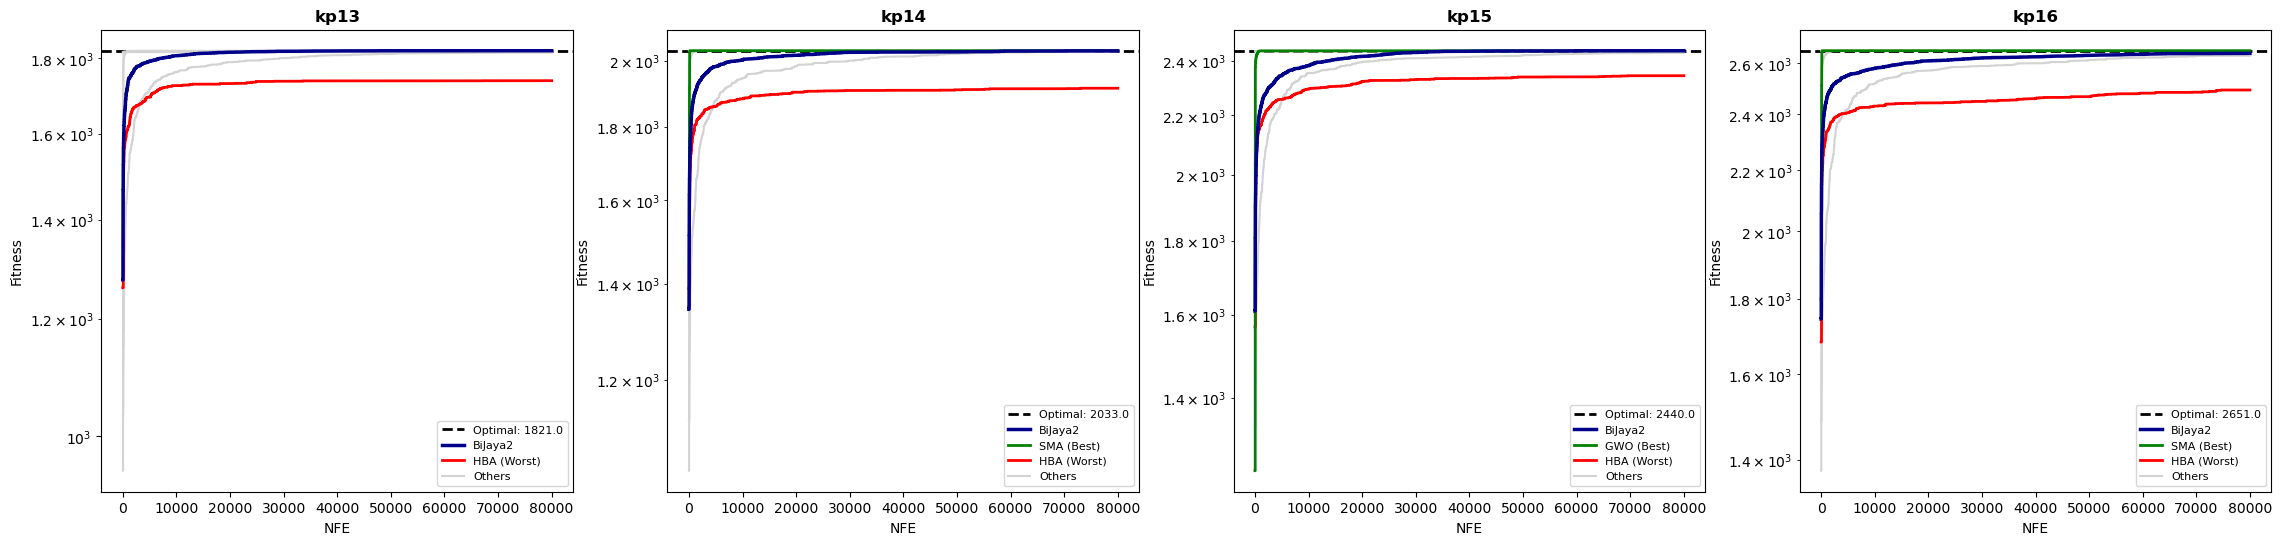

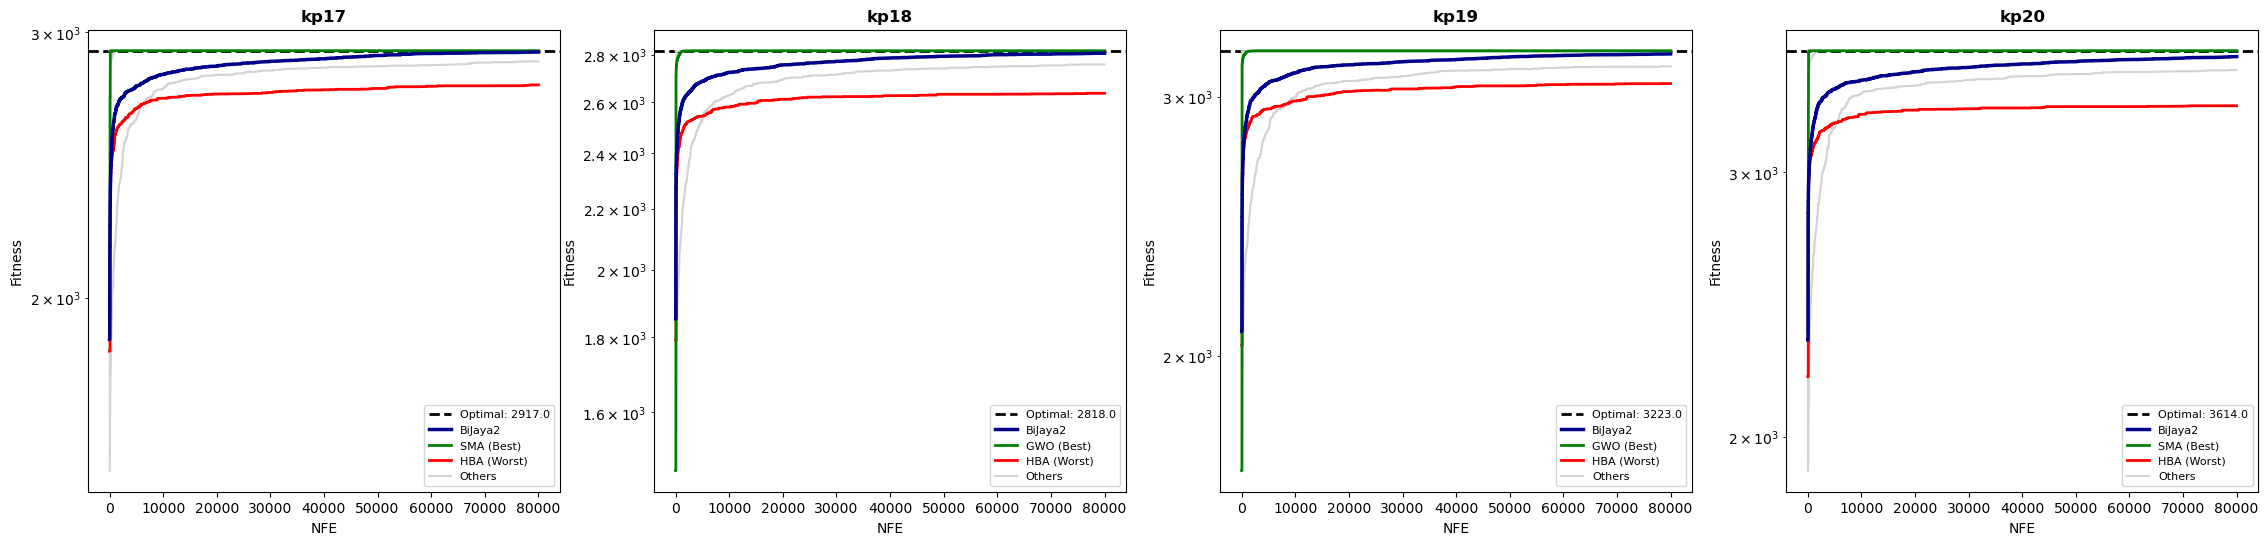

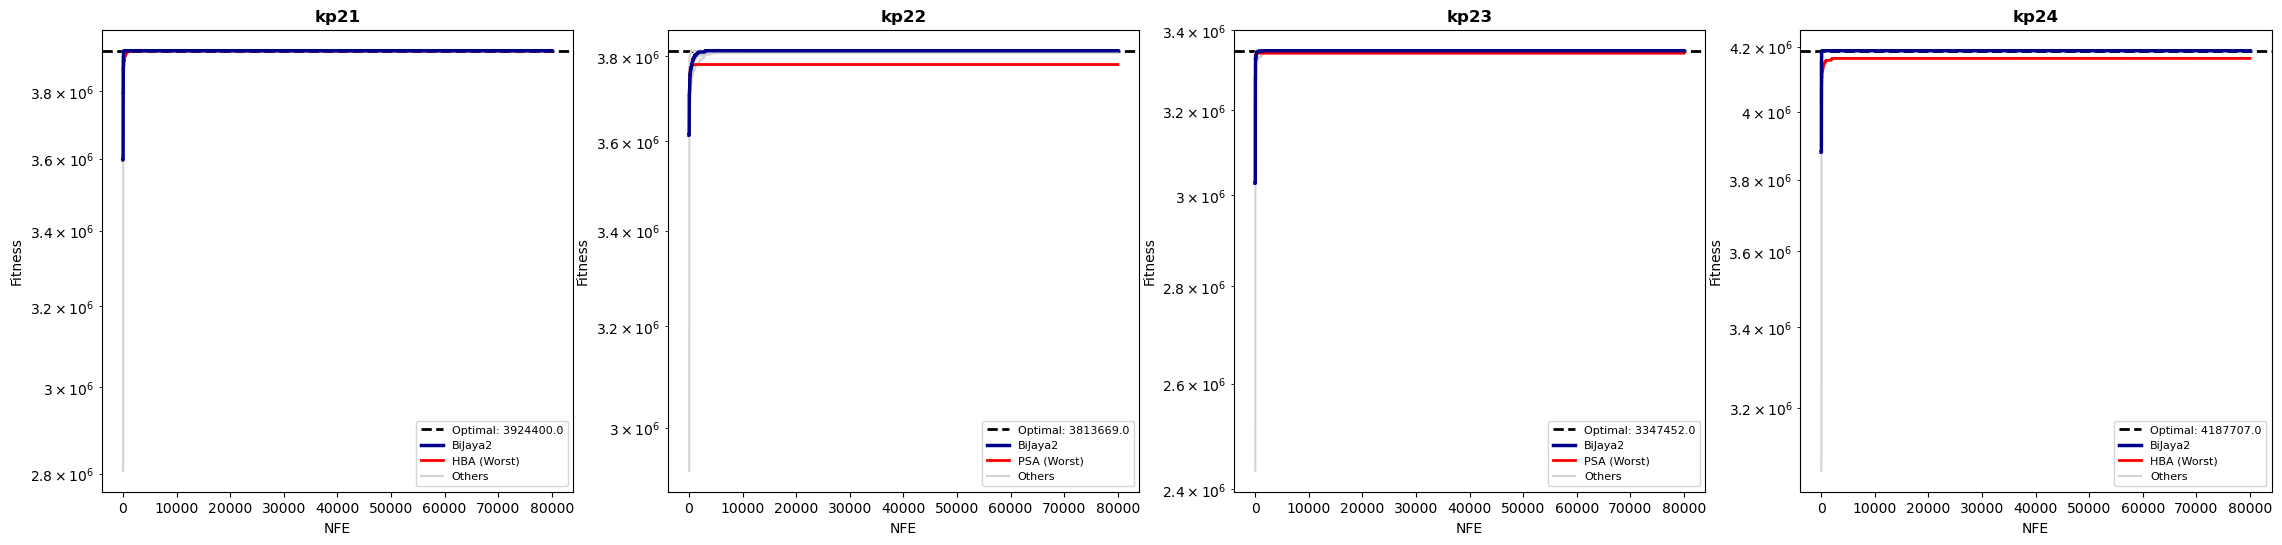

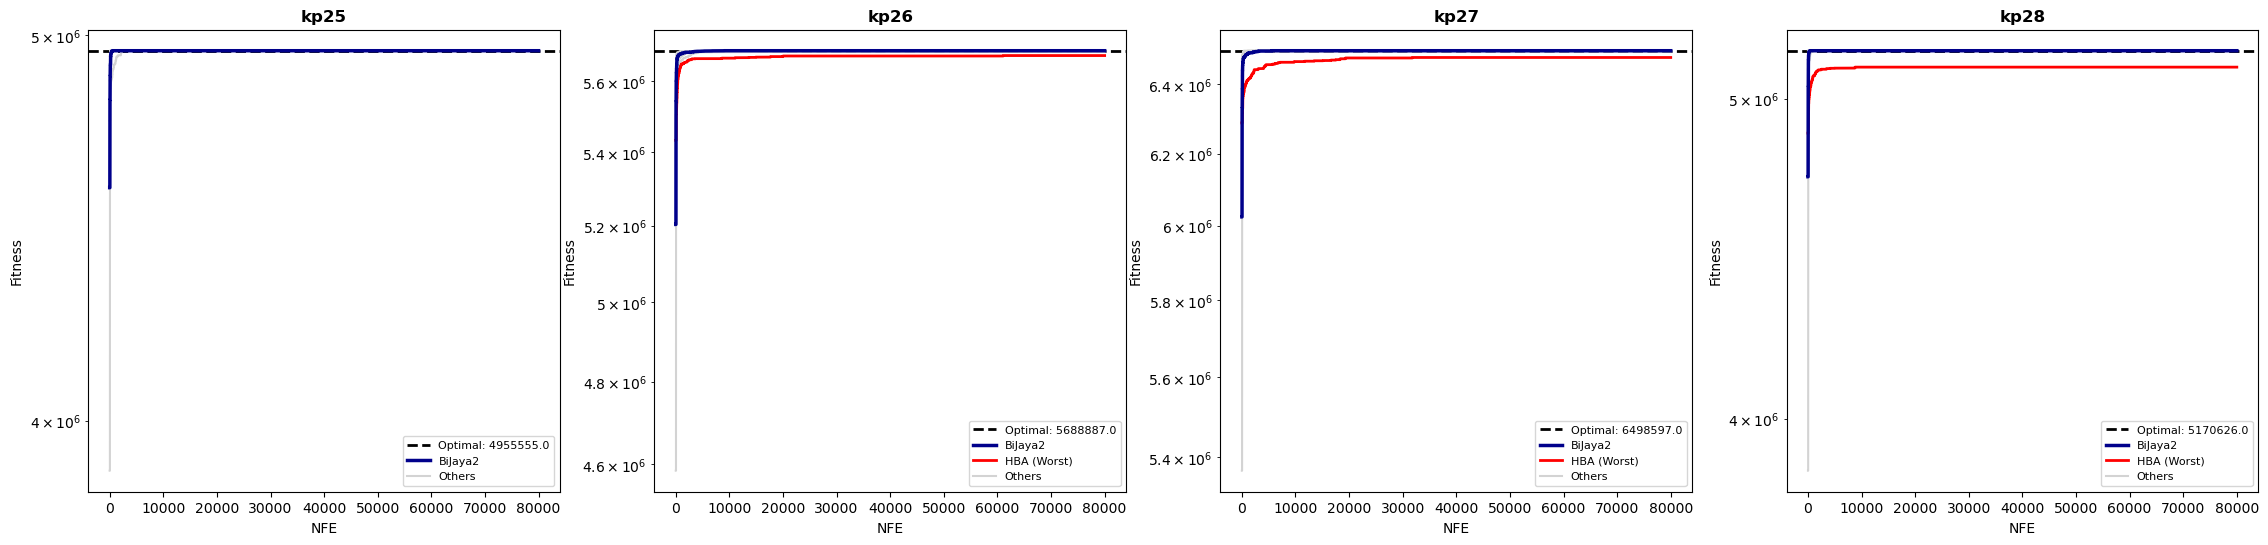

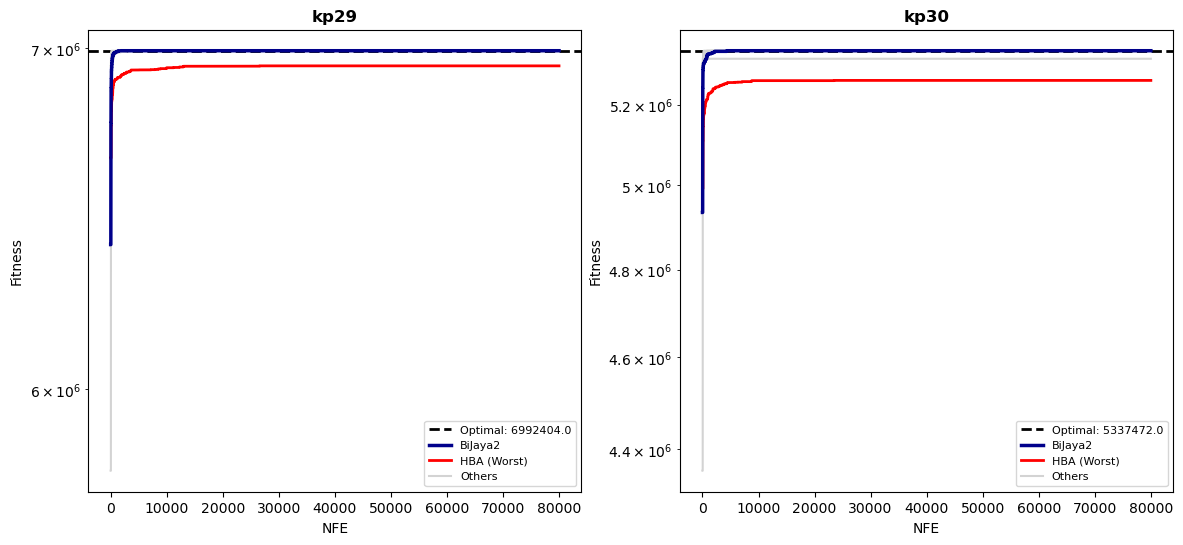

In [20]:
files = {
    'BiJaya2': '6 Algorithms (small instances)/BiJaya (without SRO2)/BiJaya2_withoutSRO2_small_Knapsack.csv',
    'SMA': '6 Algorithms (small instances)/SMA/SMA_Knapsack.csv',
    'PSA': '6 Algorithms (small instances)/PSA/PSA_Knapsack.csv',
    #'SCA': '6 Algorithms (small instances)/SCA/SCA_Knapsack.csv',
    'HBA': '6 Algorithms (small instances)/HBA (without RO)/HBA_Knapsack.csv',
    'GWO': '6 Algorithms (small instances)/GWO/GWO_Knapsack.csv',
    'BMPA': '6 Algorithms (small instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2', 
    instances=['kp_1', 'kp_2', 'kp_3', 'kp_4', 'kp_5', 'kp_6', 'kp_7', 'kp_8', 'kp_9', 'kp_10', 'kp_11', 'kp_12', 'kp_13', 'kp_14', 'kp_15', 'kp_16', 'kp_17', 'kp_18', 'kp_19', 'kp_20', 'kp_21', 'kp_22', 'kp_23', 'kp_24', 'kp_25', 'kp_26', 'kp_27', 'kp_28', 'kp_29', 'kp_30'],
    plots_per_figure=4, 
    output_prefix='test1_6algo_small_kp1_kp30_convergence' )

<h3 style = "color:blue;">5 Algorithm Convergence Plots Experiment (kp31-kp48)</h3>

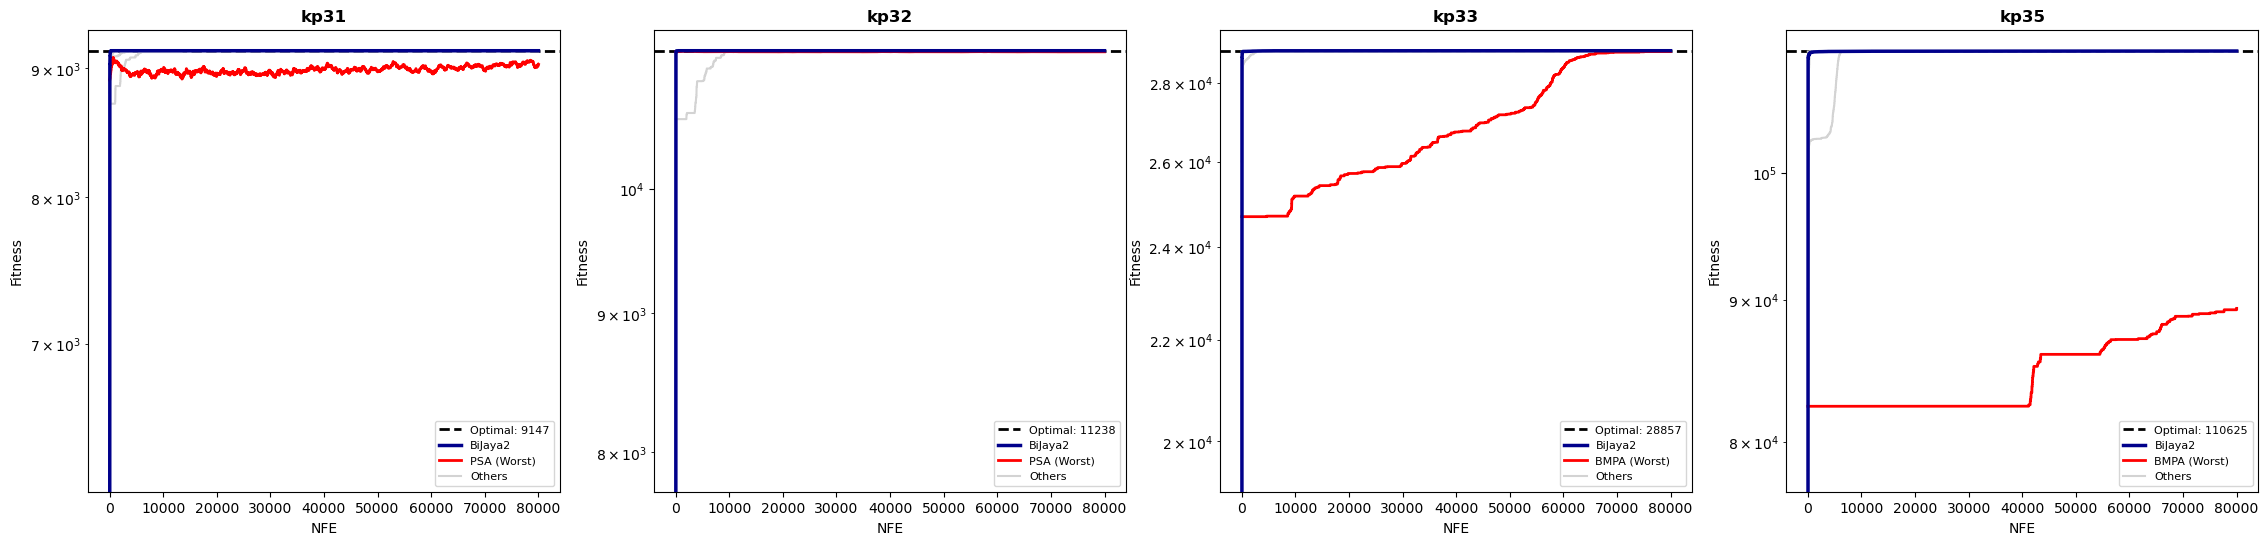

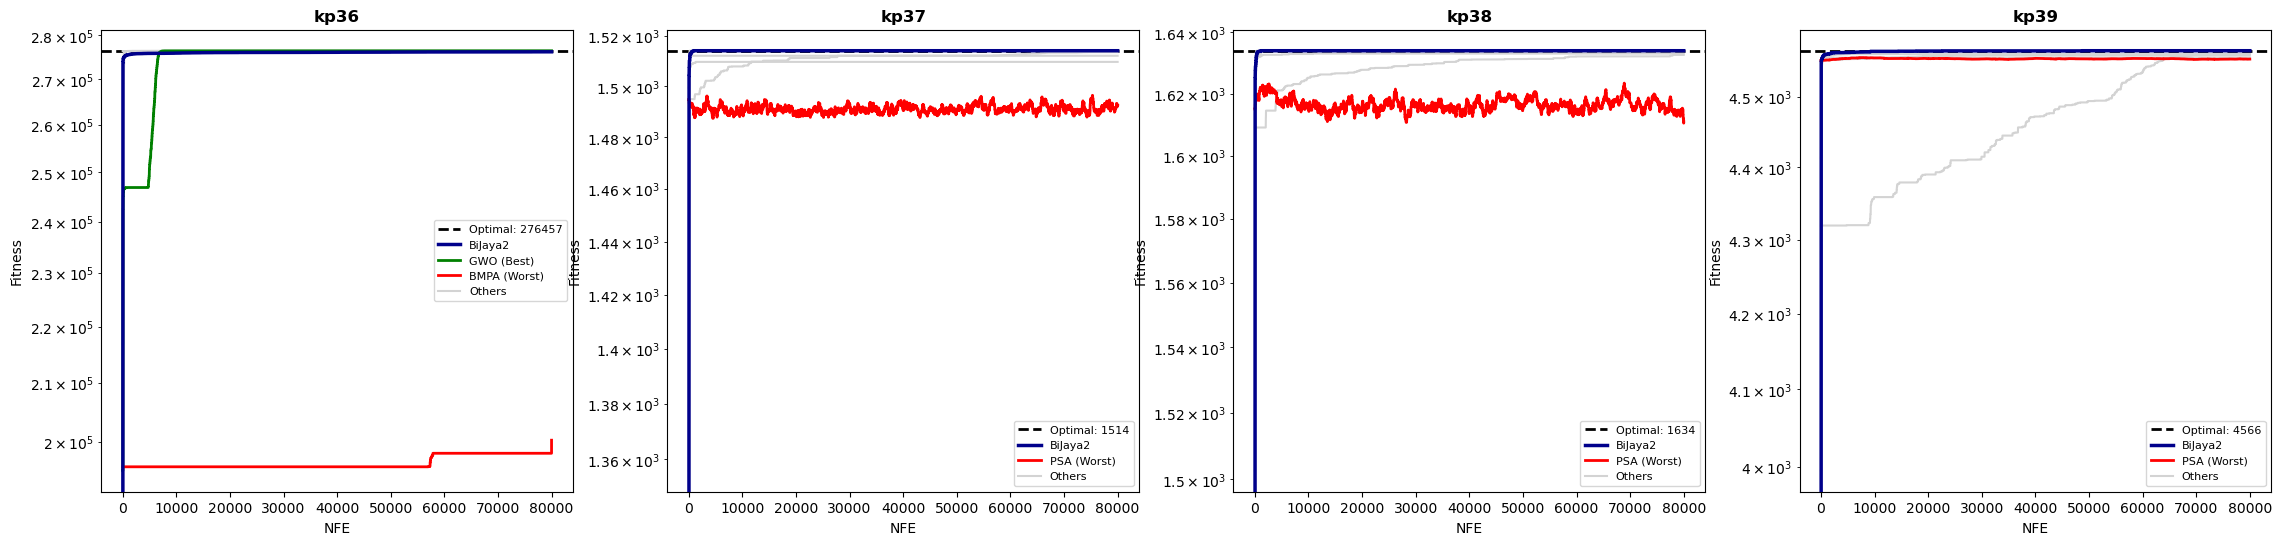

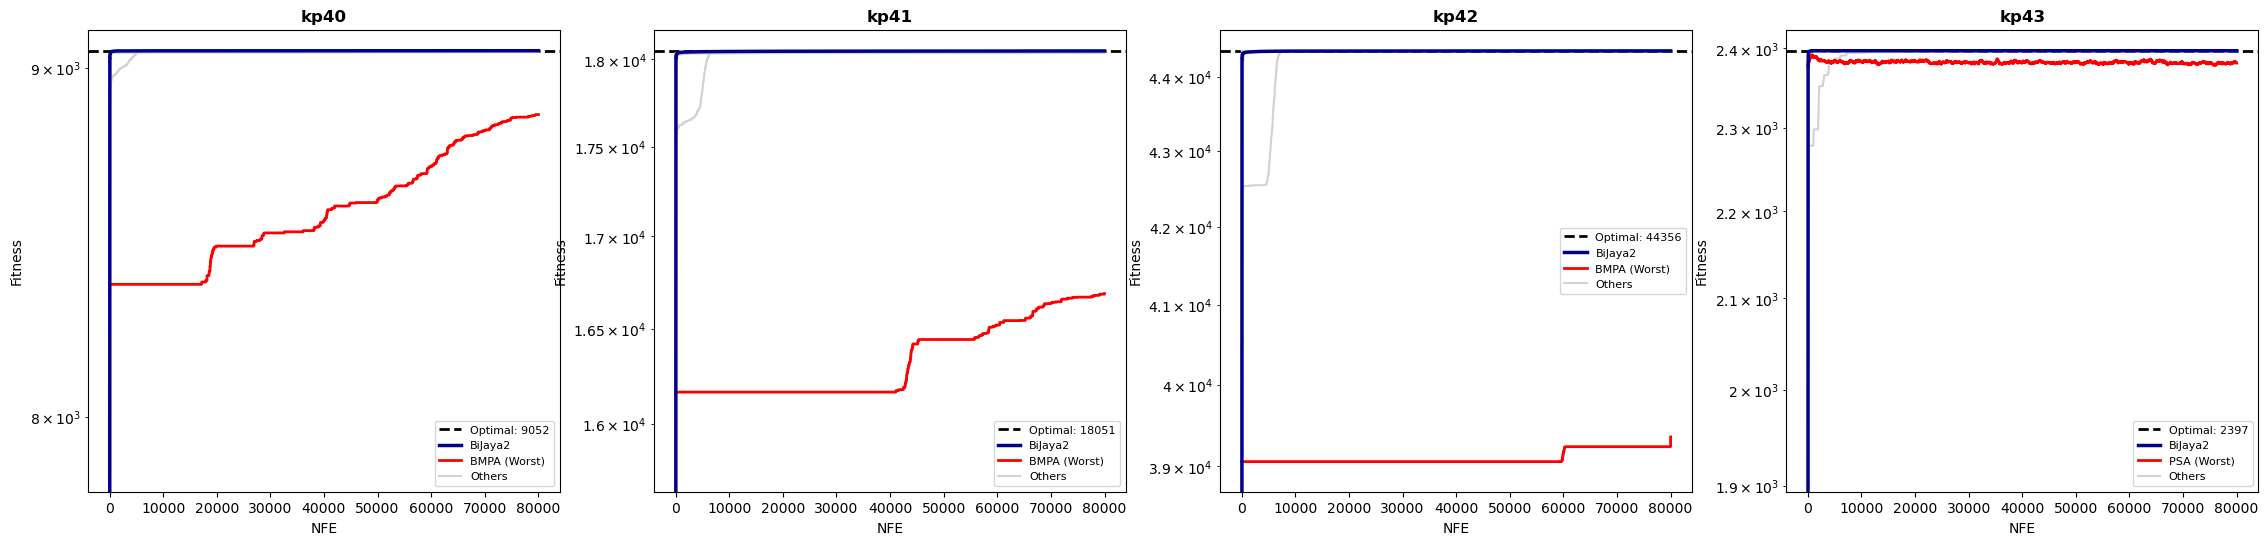

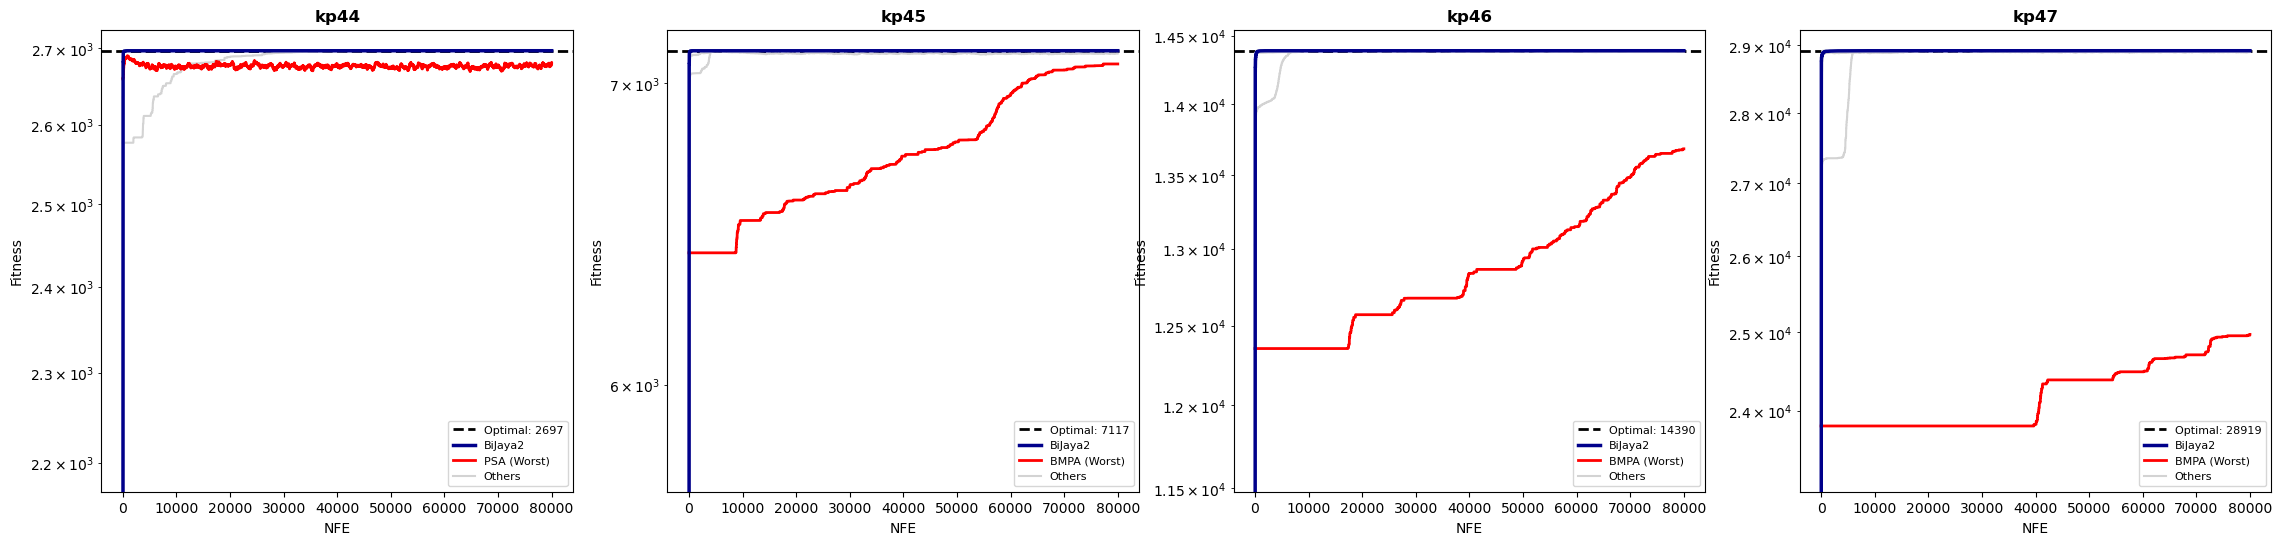

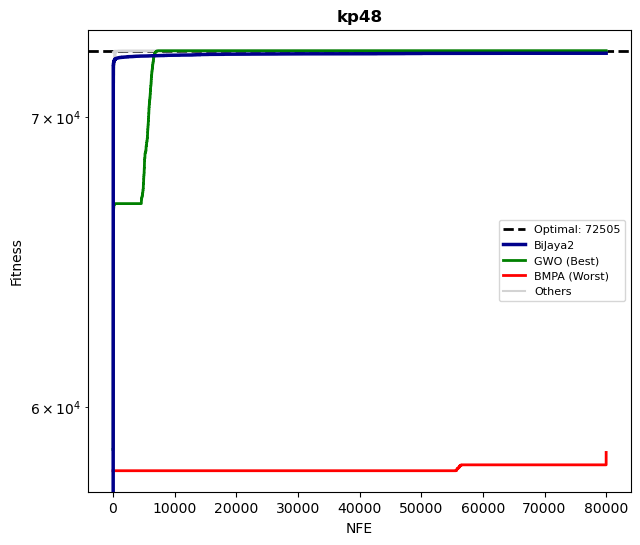

In [21]:
files = {
    'BiJaya2': '5 Algorithms (Large instances)/BiJaya2/BiJaya2_Knapsack.csv',
    'SMA': '5 Algorithms (Large instances)/SMA/SMA_Knapsack.csv',
    'PSA': '5 Algorithms (Large instances)/PSA/PSA_Knapsack.csv',
    'HBA': '5 Algorithms (Large instances)/HBA/HBA_Knapsack.csv',
    'GWO': '5 Algorithms (Large instances)/GWO/GWO_Knapsack.csv',
    'BMPA': '5 Algorithms (Large instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2', 
    instances=['kp_31', 'kp_32', 'kp_33', 'kp34', 'kp_35', 'kp_36', 'kp_37', 'kp_38', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_43', 'kp_44', 'kp_45', 'kp_46', 'kp_47', 'kp_48'],
    plots_per_figure=4, 
    output_prefix='5algo_large_kp31_kp48_convergence' )

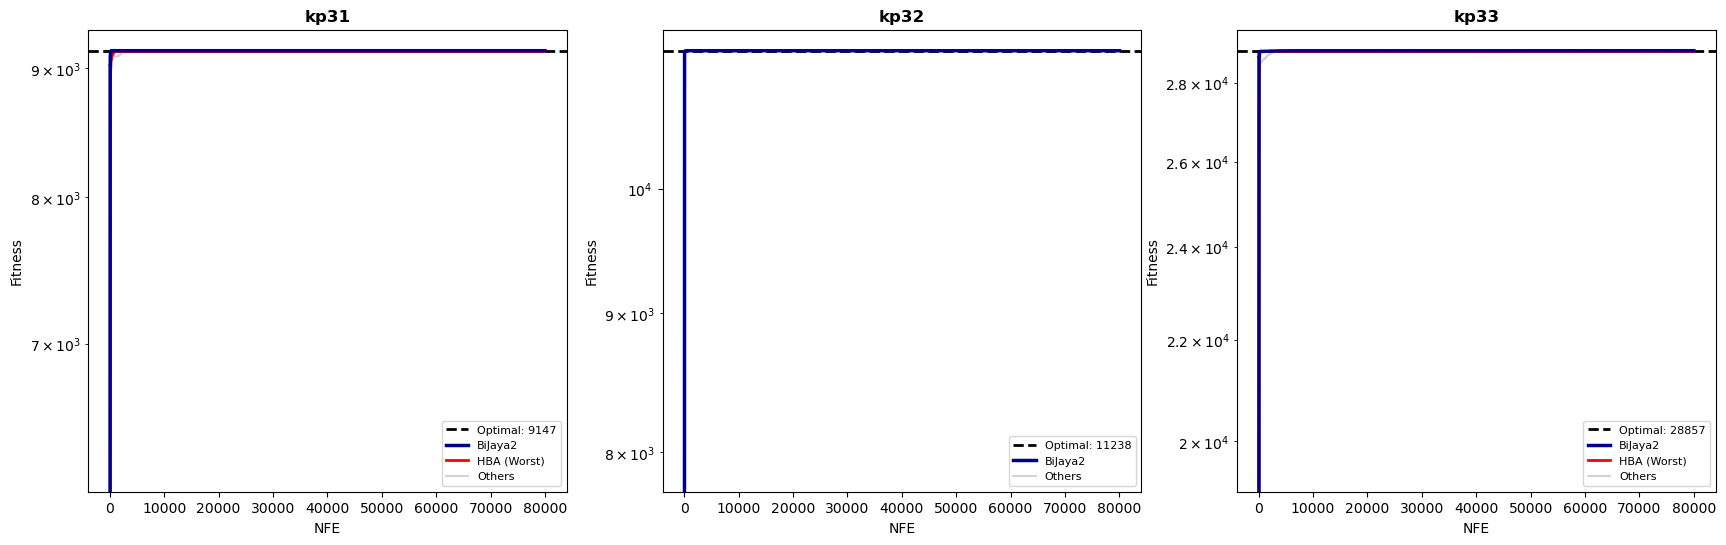

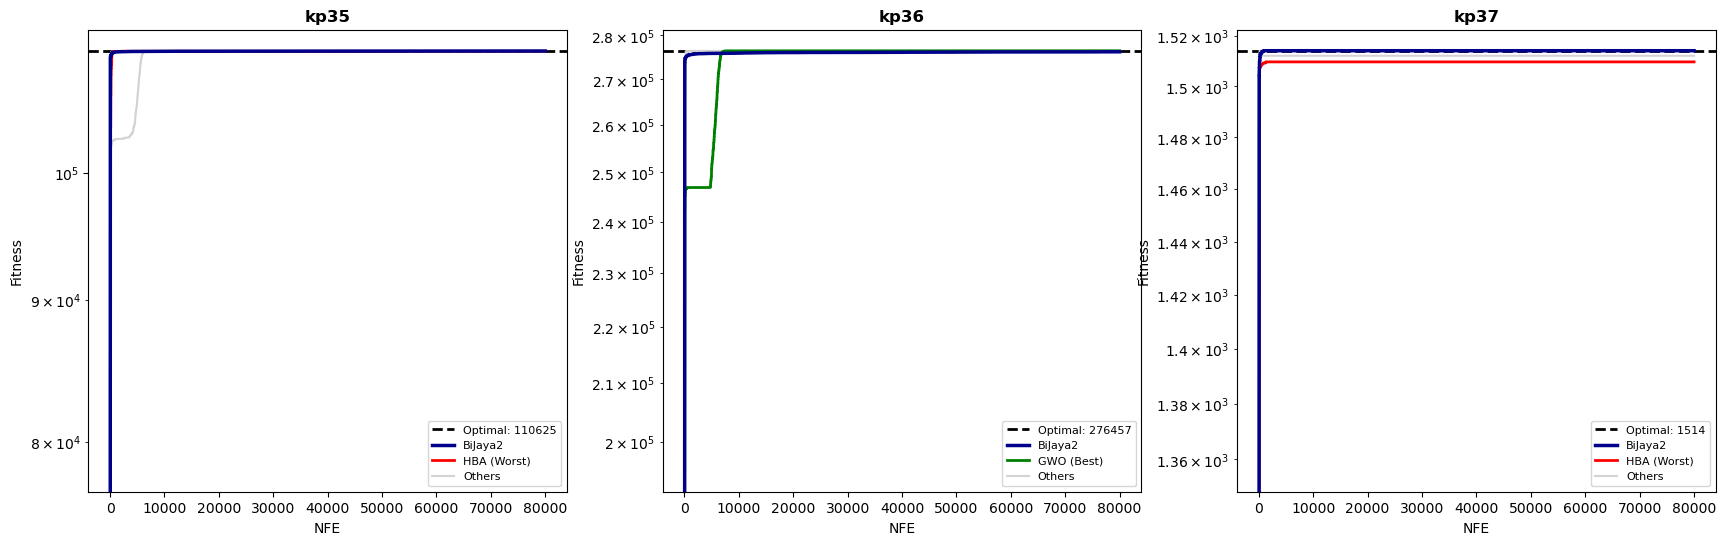

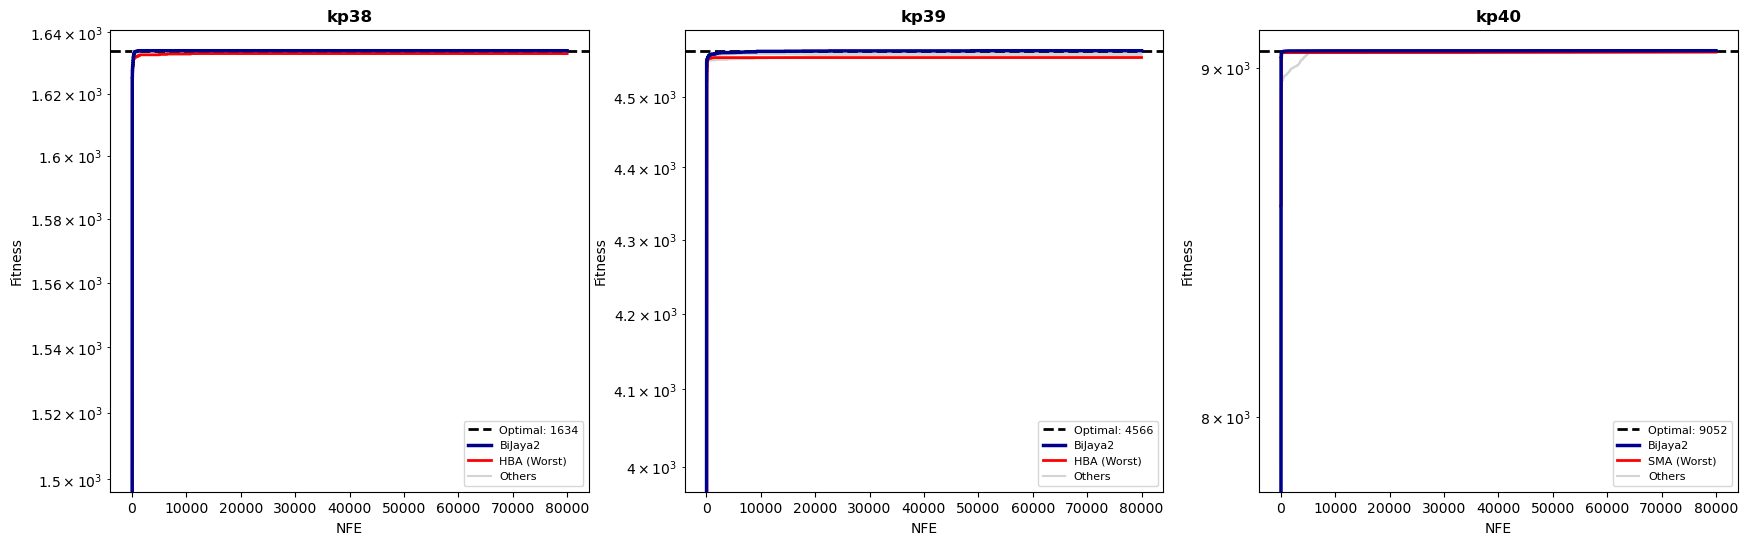

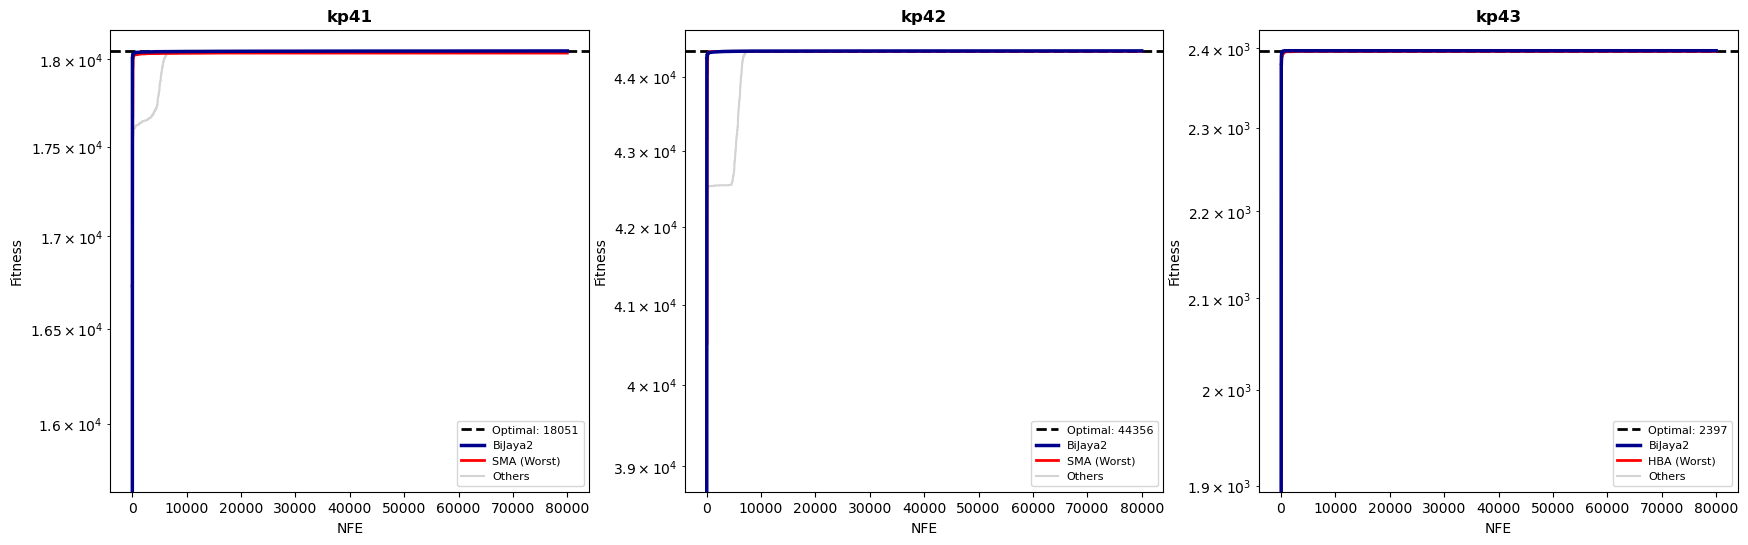

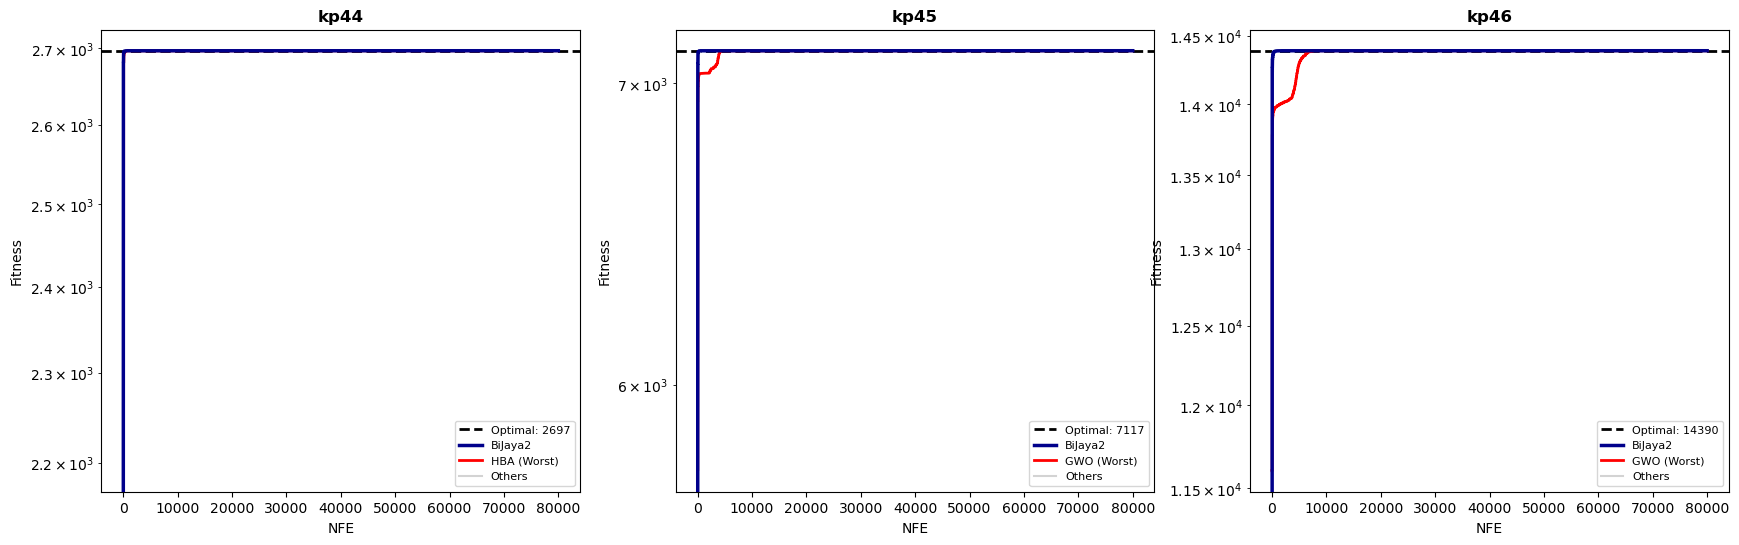

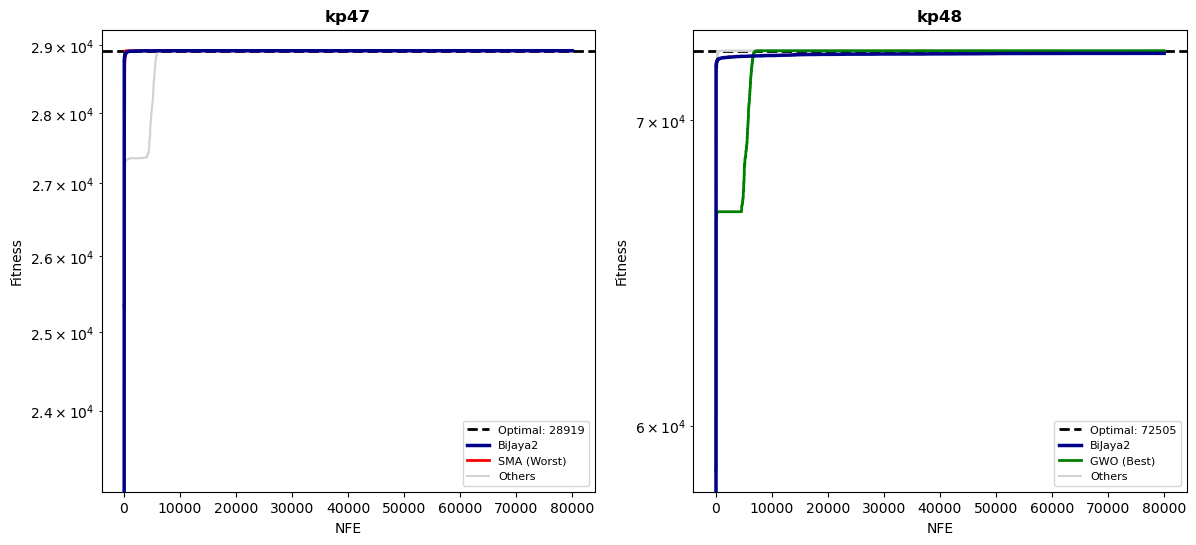

In [22]:
files = {
    'BiJaya2': '5 Algorithms (Large instances)/BiJaya2/BiJaya2_Knapsack.csv',
    'SMA': '5 Algorithms (Large instances)/SMA/SMA_Knapsack.csv',
    #'PSA': '5 Algorithms (Large instances)/PSA/PSA_Knapsack.csv',
    'HBA': '5 Algorithms (Large instances)/HBA/HBA_Knapsack.csv',
    'GWO': '5 Algorithms (Large instances)/GWO/GWO_Knapsack.csv',
    #'BMPA': '5 Algorithms (Large instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

convergence_data = plot_algorithm_convergence_new( 
    files=files, 
    primary_algo='BiJaya2', 
    instances=['kp_31', 'kp_32', 'kp_33', 'kp34', 'kp_35', 'kp_36', 'kp_37', 'kp_38', 'kp_39', 'kp_40', 'kp_41', 'kp_42', 'kp_43', 'kp_44', 'kp_45', 'kp_46', 'kp_47', 'kp_48'],
    plots_per_figure=3, 
    output_prefix='test1_5algo_large_kp31_kp48_convergence' )

<h1 style = "color:green;">Friedman Statistical Analysis Using the Mean Fitness Values</h1>

What does a large statistic mean? (chi-square statistic)
- Small statistic (close to 0): the algorithms have very similar rankings across datasets.
- Large statistic: the rankings differ substantially, indicating that some algorithms consistently outperform others.

In [23]:
def friedman_analysis(files):
    data = {}

    for algo, path in files.items():
        df = pd.read_csv(path)

        if 'Mean' not in df.columns:
            raise ValueError(f"{algo}: column 'Mean' not found.")

        data[algo] = df['Mean'].values

    results = pd.DataFrame(data)

    # Compute ranks (Lower fitness: better rank)
    rank_df = results.rank(axis=1,  method='average', ascending=False)
    average_ranks = rank_df.mean().sort_values()

    # Friedman Test
    statistic, pvalue = friedmanchisquare(
        *[results[col].values for col in results.columns]
    )

    print("Average Friedman Ranks")
    print(average_ranks)

    print("\n\nFriedman Test")
    print(f"Statistic = {statistic:.6f}")
    print(f"P-value   = {pvalue:.10f}")

    alpha = 0.05
    if pvalue < alpha:
        print("\nResult:")
        print("The differences between algorithms are statistically significant.")
        print(f"(Reject H0 at α = {alpha})")
    else:
        print("\nResult:")
        print("No statistically significant difference was found.")
        print(f"(Fail to reject H0 at α = {alpha})")

    return rank_df, average_ranks, statistic, pvalue

<h3 style = "color:blue;">Reinitialization Experiment</h3>

In [24]:
files = {
    'BiJaya2 S-Greedy': 'reinitialization (with SRO2)/BiJaya2_greedy/BiJaya2_Greedy_Re_Knapsack.csv',
    'BiJaya2 OBL': 'reinitialization (with SRO2)/BiJaya2_OBL/BiJaya2_OBL_Re_Knapsack.csv',
    'BiJaya2 Best+Random': 'reinitialization (with SRO2)/BiJaya2_best_AND_random/BiJaya2_best_random_Re_Knapsack.csv',
    'BiJaya2 Random': 'reinitialization (with SRO2)/BiJaya2_random/BiJaya2_Random_Re_Knapsack.csv',
    'BiJaya2 without Re': 'reinitialization (with SRO2)/BiJaya2_without_Re/BiJaya2_without_Re_Knapsack.csv'
}

rank_df, average_ranks, statistic, pvalue = friedman_analysis(files)

Average Friedman Ranks
BiJaya2 S-Greedy       2.194444
BiJaya2 OBL            2.611111
BiJaya2 Best+Random    3.027778
BiJaya2 Random         3.388889
BiJaya2 without Re     3.777778
dtype: float64


Friedman Test
Statistic = 23.062857
P-value   = 0.0001230169

Result:
The differences between algorithms are statistically significant.
(Reject H0 at α = 0.05)


<h3 style = "color:blue;">r1 Experiment (kp31-kp48)</h3>

In [25]:
files = {
    '0.1': 'BiJaya2_r1/BiJaya2_r1_0.1/BiJaya2_r1_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r1/BiJaya2_r1_0.2/BiJaya2_r1_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r1/BiJaya2_r1_0.3/BiJaya2_r1_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r1/BiJaya2_r1_0.4/BiJaya2_r1_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r1/BiJaya2_r1_0.5/BiJaya2_r1_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r1/BiJaya2_r1_0.6/BiJaya2_r1_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r1/BiJaya2_r1_0.7/BiJaya2_r1_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r1/BiJaya2_r1_0.8/BiJaya2_r1_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r1/BiJaya2_r1_0.9/BiJaya2_r1_0.9_Knapsack.csv'
}

rank_df, average_ranks, statistic, pvalue = friedman_analysis(files)

Average Friedman Ranks
0.3    4.250000
0.1    4.527778
0.2    4.527778
0.5    5.083333
0.6    5.166667
0.7    5.194444
0.9    5.250000
0.4    5.416667
0.8    5.583333
dtype: float64


Friedman Test
Statistic = 10.542331
P-value   = 0.2290032456

Result:
No statistically significant difference was found.
(Fail to reject H0 at α = 0.05)


<h3 style = "color:blue;">r2 Experiment (kp31-kp48)</h3>

In [26]:
files = {
    '0.1': 'BiJaya2_r2/BiJaya2_r2_0.1/BiJaya2_r2_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r2/BiJaya2_r2_0.2/BiJaya2_r2_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r2/BiJaya2_r2_0.3/BiJaya2_r2_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r2/BiJaya2_r2_0.4/BiJaya2_r2_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r2/BiJaya2_r2_0.5/BiJaya2_r2_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r2/BiJaya2_r2_0.6/BiJaya2_r2_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r2/BiJaya2_r2_0.7/BiJaya2_r2_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r2/BiJaya2_r2_0.8/BiJaya2_r2_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r2/BiJaya2_r2_0.9/BiJaya2_r2_0.9_Knapsack.csv'
}

rank_df, average_ranks, statistic, pvalue = friedman_analysis(files)

Average Friedman Ranks
0.8    4.138889
0.7    4.361111
0.9    4.444444
0.6    4.944444
0.5    5.166667
0.4    5.222222
0.2    5.527778
0.3    5.527778
0.1    5.666667
dtype: float64


Friedman Test
Statistic = 21.516340
P-value   = 0.0058952167

Result:
The differences between algorithms are statistically significant.
(Reject H0 at α = 0.05)


<h3 style = "color:blue;">Jaya Variants Experiment (kp31-kp48)</h3>

In [27]:
files = {
    'BiJaya2': 'Jaya variants/Jaya2_SRO/BiJaya2_Knapsack.csv',
    'BJaya-JS': 'Jaya variants/Jaya-JS RO/BJayaJS_Knapsack.csv',
    'DHJaya': 'Jaya variants/DHJaya RO/DHJaya_Knapsack.csv',
    'IBJA': 'Jaya variants/IBJaya/IBJaya_Knapsack.csv',
    'JayaX': 'Jaya variants/JayaX RO/JayaX_Knapsack.csv',
    'SimJAYA-RL': 'Jaya variants/SimBJAYA-RL RO/SimJAYA_RL_Knapsack.csv'
}

rank_df, average_ranks, statistic, pvalue = friedman_analysis(files)

Average Friedman Ranks
BiJaya2       2.555556
JayaX         2.861111
DHJaya        2.916667
BJaya-JS      4.027778
SimJAYA-RL    4.166667
IBJA          4.472222
dtype: float64


Friedman Test
Statistic = 21.788618
P-value   = 0.0005743223

Result:
The differences between algorithms are statistically significant.
(Reject H0 at α = 0.05)


<h3 style = "color:blue;">6 Algorithm Experiment (kp1-kp30)</h3>

In [28]:
files = {
    'BiJaya2': '6 Algorithms (small instances)/BiJaya (without SRO2)/BiJaya2_withoutSRO2_small_Knapsack.csv',
    'SMA': '6 Algorithms (small instances)/SMA/SMA_Knapsack.csv',
    'PSA': '6 Algorithms (small instances)/PSA/PSA_Knapsack.csv',
    'SCA': '6 Algorithms (small instances)/SCA (without RO)/SCA_Knapsack.csv',
    'HBA': '6 Algorithms (small instances)/HBA (without RO)/HBA_Knapsack.csv',
    'GWO': '6 Algorithms (small instances)/GWO/GWO_Knapsack.csv',
    'BMPA': '6 Algorithms (small instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

rank_df, average_ranks, statistic, pvalue = friedman_analysis(files)

Average Friedman Ranks
GWO        2.933333
SMA        3.050000
BiJaya2    3.233333
BMPA       3.650000
PSA        4.183333
SCA        5.033333
HBA        5.916667
dtype: float64


Friedman Test
Statistic = 76.893094
P-value   = 0.0000000000

Result:
The differences between algorithms are statistically significant.
(Reject H0 at α = 0.05)


<h3 style = "color:blue;">5 Algorithm Experiment (kp31-kp48)</h3>

In [29]:
files = {
    'BiJaya2': '5 Algorithms (Large instances)/BiJaya2/BiJaya2_Knapsack.csv',
    'SMA': '5 Algorithms (Large instances)/SMA/SMA_Knapsack.csv',
    'PSA': '5 Algorithms (Large instances)/PSA/PSA_Knapsack.csv',
    'HBA': '5 Algorithms (Large instances)/HBA/HBA_Knapsack.csv',
    'GWO': '5 Algorithms (Large instances)/GWO/GWO_Knapsack.csv',
    'BMPA': '5 Algorithms (Large instances)/BMPA - from MPA/BMPA_Knapsack.csv'
}

rank_df, average_ranks, statistic, pvalue = friedman_analysis(files)

Average Friedman Ranks
BiJaya2    1.972222
GWO        2.555556
SMA        3.222222
HBA        3.472222
PSA        4.833333
BMPA       4.944444
dtype: float64


Friedman Test
Statistic = 40.461672
P-value   = 0.0000001205

Result:
The differences between algorithms are statistically significant.
(Reject H0 at α = 0.05)


<h1 style = "color:green;">Post-hoc Nemenyi Test (Wilcoxon-Nemenyi-McDonald-Thompson Test)</h1>

The black horizontal bars are the important part: they connect groups of algorithms whose average-rank difference is less than CD => meaning they are statistically indistinguishable (a "clique").

The long black bar spanning Bijaya2 => GA covers the four leftmost methods (Bijaya2, SMA, IHBA, GA), meaning none of those four are significantly different from each other even though Bijaya2 has the best rank.

In [ ]:
def nemenyi_analysis(files, kp_range=None, alpha=0.05, title="Critical Difference Diagram", filename=None):

    data = {}
    # Load data
    for algo, path in files.items():
        df = pd.read_csv(path)

        if 'Mean' not in df.columns:
            raise ValueError(f"{algo}: 'Mean' column not found.")
        values = df["Mean"]

        if kp_range is not None:
            start, end = kp_range
            values = values.iloc[start-1:end]
        data[algo] = values.reset_index(drop=True)

    results = pd.DataFrame(data)

    # Ranking
    N, k = results.shape

    # Higher Mean = Better rank
    rank_df = results.rank(axis=1, method='average', ascending=False)
    avg_ranks = rank_df.mean().sort_values()

    # Nemenyi Test
    nemenyi_p = sp.posthoc_nemenyi_friedman(results.values)
    nemenyi_p.columns = results.columns
    nemenyi_p.index = results.columns

    # Critical Distance
    q_alpha = {
        2:1.960,
        3:2.343,
        4:2.569,
        5:2.728,
        6:2.850,
        7:2.949,
        8:3.031,
        9:3.102,
        10:3.164
    }[k]

    CD = q_alpha * np.sqrt(k*(k+1)/(6.0*N))

    print("\nAverage Ranks:")
    print(avg_ranks)
    print(f"\nCritical Distance (CD) = {CD:.4f}\n")

    print("All Pairwise Rank Differences:")
    algos = avg_ranks.index.tolist()

    for i in range(len(algos)):
        for j in range(i+1, len(algos)):
            algo1 = algos[i]
            algo2 = algos[j]
            diff = abs(avg_ranks[algo1] - avg_ranks[algo2])

            if diff >= CD:
                result = "Significant"
            else:
                result = "Not Significant"

            print(
                f"{algo1:10s} vs {algo2:10s}: "
                f"rank diff = {diff:.3f} --> {result}"
            )

    # Critical Difference Diagram
    avg_rank_dict = avg_ranks.to_dict()
    plt.figure(figsize=(10,3))
    sp.critical_difference_diagram(avg_rank_dict, nemenyi_p)
    ax = plt.gca()

    # Change colors:
    # Text labels
    for text in ax.texts:
        if "BiJaya2" in text.get_text():
            text.set_color("darkblue")
        else:
            text.set_color("gray")
            
    # Lines
    for line in ax.lines:
        xdata = line.get_xdata()
        ydata = line.get_ydata()

        # Horizontal clique bars
        if len(set(ydata)) == 1:
            line.set_color("black")
            line.set_linewidth(1.5)
        # Vertical rank lines
        else:
            line.set_color("gray")
            line.set_linewidth(1.0)

    # Highlight BiJaya2 marker and vertical line
    # BiJaya2 rank position
    bijaya_rank = avg_ranks["BiJaya2"]

    # Highlight BiJaya2 vertical line
    for line in ax.lines:
        xdata = line.get_xdata()
        ydata = line.get_ydata()
        
        # Ensure the line has data and varies in the y-axis (connector line)
        if len(xdata) > 0 and len(set(ydata)) > 1:
            # Check if BiJaya2's rank is anywhere along this line's x-coordinates
            if any(abs(x - bijaya_rank) < 1e-3 for x in xdata):
                line.set_color("darkblue")
                line.set_linewidth(1.0)
                line.set_zorder(10)  # Bring to front

    # Change marker dots
    for collection in ax.collections:
        offsets = collection.get_offsets()
        
        if len(offsets) == 0:
            continue
        new_colors = []
        
        for x, y in offsets:
            # Match BiJaya2 x coordinate
            if abs(x - bijaya_rank) < 1e-5:
                new_colors.append("darkblue")
            else:
                new_colors.append("gray")
        
        collection.set_color(new_colors)
        collection.set_zorder(10)  # Bring to front

    plt.title(title)
    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    return avg_ranks, nemenyi_p, CD

<h3 style = "color:blue;">Reinitialization Experiment</h3>

In [ ]:
files = {
    'BiJaya2 S-Greedy': 'reinitialization (with SRO2)/BiJaya2_greedy/BiJaya2_Greedy_Re_Knapsack.csv',
    'BiJaya2 OBL': 'reinitialization (with SRO2)/BiJaya2_OBL/BiJaya2_OBL_Re_Knapsack.csv',
    'BiJaya2 Best+Random': 'reinitialization (with SRO2)/BiJaya2_best_AND_random/BiJaya2_best_random_Re_Knapsack.csv',
    'BiJaya2 Random': 'reinitialization (with SRO2)/BiJaya2_random/BiJaya2_Random_Re_Knapsack.csv',
    'BiJaya2 without Re': 'reinitialization (with SRO2)\BiJaya2_without_Re/BiJaya2_without_Re_Knapsack.csv'
}

avg_ranks, nemenyi_p, CD = nemenyi_analysis(
    files,
    kp_range=(31, 48),
    title="Critical Difference Diagram for Reinitialization BiJaya2 Variants (kp31-kp48)",
    filename="CD_Re_kp31_kp48.png"
)

<h3 style = "color:blue;">r1 Experiment (kp31-kp48)</h3>

In [ ]:
files = {
    '0.1': 'BiJaya2_r1/BiJaya2_r1_0.1/BiJaya2_r1_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r1/BiJaya2_r1_0.2/BiJaya2_r1_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r1/BiJaya2_r1_0.3/BiJaya2_r1_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r1/BiJaya2_r1_0.4/BiJaya2_r1_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r1/BiJaya2_r1_0.5/BiJaya2_r1_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r1/BiJaya2_r1_0.6/BiJaya2_r1_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r1/BiJaya2_r1_0.7/BiJaya2_r1_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r1/BiJaya2_r1_0.8/BiJaya2_r1_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r1/BiJaya2_r1_0.9/BiJaya2_r1_0.9_Knapsack.csv'
}

avg_ranks, nemenyi_p, CD = nemenyi_analysis(
    files,
    kp_range=(31, 48),
    title="Critical Difference Diagram for r1 (kp31-kp48)",
    filename="CD_r1_kp31_kp48.png"
)

<h3 style = "color:blue;">r2 Experiment (kp31-kp48)</h3>

In [ ]:
files = {
    '0.1': 'BiJaya2_r1/BiJaya2_r1_0.1/BiJaya2_r1_0.1_Knapsack.csv',
    '0.2': 'BiJaya2_r1/BiJaya2_r1_0.2/BiJaya2_r1_0.2_Knapsack.csv',
    '0.3': 'BiJaya2_r1/BiJaya2_r1_0.3/BiJaya2_r1_0.3_Knapsack.csv',
    '0.4': 'BiJaya2_r1/BiJaya2_r1_0.4/BiJaya2_r1_0.4_Knapsack.csv',
    '0.5': 'BiJaya2_r1/BiJaya2_r1_0.5/BiJaya2_r1_0.5_Knapsack.csv',
    '0.6': 'BiJaya2_r1/BiJaya2_r1_0.6/BiJaya2_r1_0.6_Knapsack.csv',
    '0.7': 'BiJaya2_r1/BiJaya2_r1_0.7/BiJaya2_r1_0.7_Knapsack.csv',
    '0.8': 'BiJaya2_r1/BiJaya2_r1_0.8/BiJaya2_r1_0.8_Knapsack.csv',
    '0.9': 'BiJaya2_r1/BiJaya2_r1_0.9/BiJaya2_r1_0.9_Knapsack.csv'
}

avg_ranks, nemenyi_p, CD = nemenyi_analysis(
    files,
    kp_range=(31, 48),
    title="Critical Difference Diagram for r2 (kp31-kp48)",
    filename="CD_r2_kp31_kp48.png"
)

<h3 style = "color:blue;">6 Algorithm Experiment (kp1-kp30)</h3>

In [ ]:
files = {
    'BiJaya2': '6 Algorithms (small instances)/BiJaya2_withoutSRO2_small_Knapsack.csv',
    'SMA': '6 Algorithms (small instances)/SMA_Knapsack.csv',
    'PSA': '6 Algorithms (small instances)/PSA_Knapsack.csv',
    'SCA': '6 Algorithms (small instances)/SCA_Knapsack.csv',
    'HBA': '6 Algorithms (small instances)/HBA_Knapsack.csv',
    'GWO': '6 Algorithms (small instances)/GWO_Knapsack.csv',
    'BMPA': '6 Algorithms (small instances)/BMPA_Knapsack.csv'
}

avg_ranks, nemenyi_p, CD = nemenyi_analysis(
    files,
    kp_range=(1, 30),
    title="Critical Difference Diagram on small instances (kp1-kp30)",
    filename="CD_6Algo_small_withoutRO_kp1_kp30.png"
)

<h3 style = "color:blue;">5 Algorithm Experiment (kp31-kp48)</h3>

In [ ]:
files = {
    'BiJaya2': '5 Algorithms (Large instances)/BiJaya2_withSRO2_large_Knapsack.csv',
    'SMA': '5 Algorithms (Large instances)/SMA_Knapsack.csv',
    'PSA': '5 Algorithms (Large instances)/PSA_Knapsack.csv',
    'HBA': '5 Algorithms (Large instances)/HBA_Knapsack.csv',
    'GWO': '5 Algorithms (Large instances)/GWO_Knapsack.csv',
    'BMPA': '5 Algorithms (Large instances)/BMPA_Knapsack.csv'
}

avg_ranks, nemenyi_p, CD = nemenyi_analysis(
    files,
    kp_range=(1, 30),
    title="Critical Difference Diagram on Large Instances (kp31-kp48)",
    filename="CD_5Algo_large_withoutRO_kp31_kp48.png"
)